# Scorecard Model Development Roadmap — LendingClub public data, demonstrative purposes

Application PD scorecard built on LendingClub public data, following the step order a model-risk / validation team expects. ✅ = done, ⬜ = to do, ⏭️ = deferred.

| # | Stage | Step | Notes | Status |
|---|---|---|---|---|
| 1 | Conceptual soundness | Business purpose & scope | Application PD scorecard, unsecured PL, new-borrower individual apps; champion = LC `sub_grade` | ✅ |
| 2 | | Population — inclusions / exclusions | 2,128,546 loans (94.2%) after excluding joint, out-of-policy, currently delinquent; repeat borrowers not identifiable | ✅ |
| 3 | | Data sources, QC, **leakage screen** | 151 fields → 76 candidates; post-origination, post-decision, joint, compliance & unusable fields dropped; modeling frame `dm` | ✅ |
| 4 | Framework | Target definition | Lifetime outcome, 36-month loans: Bad = Charged Off/Default/Late 31–120; Good = Fully Paid; Indet = Late 16–30/Grace; Current excluded | ✅ |
| 5 | | Sample design | Dev Jan-2013–Jun-2015 → 70/30 train/holdout (stratified); OOT Jul–Dec 2015; 543,131 loans | ✅ |
| 6 | | Business segmentation | Single business segment; FICO tier, loan purpose, file depth carried to Step 8 as empirical candidates | ✅ |
| 7 | | KGB model → reject inference → booked/inferred mix | Fuzzy augmentation on 5 shared fields, Jan–Nov 2013 in-policy rejects; hidden-risk factor *k* ∈ {1–2} × natural / 30%-capped mix. *k*=1 leaves the model unchanged; *k*>1 raises PD level, rank corr ≥ 0.96. Diagnostic only, so the main scorecard uses accepts | ✅ |
| 8 | | Empirical sub-segmentation | Depth-2 entropy tree proposed FICO 700 / 730 + renter splits; 6 candidates tested with segment-vs-single logistic models. Best lift ≈ +0.1 AUC (rule ≥ +0.5 on holdout & OOT), so **one model, no sub-segments**. Test-model benchmark: AUC 67.3 / KS 25.3 holdout, AUC 68.4 / KS 26.7 OOT | ✅ |
| 9 | Variable selection | **Feature engineering — derived attributes** | 19 derived attributes (affordability, request vs debt, utilization, account mix, recency, recodes); payment at a fixed 12% reference rate, not LC pricing; no trended / interaction attributes. 1 exact duplicate dropped, so 94 candidates (`cand_fe`); derived attributes go through the same selection as raw ones (Steps 10–14) | ✅ |
| 10 | | Pre-filters | 94 → 72 candidates (54 raw, 18 derived): 14 unavailable in development, 6 single-value, `addr_state` (compliance), `emp_length` (superseded by `emp_years`); no OOT gaps or leakage; structural missing kept | ✅ |
| 11 | | Fine binning (all candidates) → WoE / IV screen | Optimal binning (`optbinning`, bins ≥ 5%, missing in own bin); 72 → 14 pass IV ≥ 0.05 (12 raw, 2 derived), all monotonic, stable on holdout / OOT; 20 more in the 0.02–0.05 weak band kept on file | ✅ |
| 12 | | Model estimation — stepwise logistic on WoE | Forward stepwise on McFadden pseudo-R² gain (entry hurdle 0.001; all coefficients negative). 14-attribute pool too thin (6 selected, holdout AUC 66.0), so the 0.02–0.05 weak band was opened: **9 attributes selected (3 derived), AUC 66.7 / 67.5, KS 24.2 / 25.3** holdout / OOT vs `sub_grade` AUC 66.0 / 68.1, KS 23.5 / 26.6 | ✅ |
| 13 | | Coarse binning of finalists | Deferred: finalists keep their Step 11 fine bins (12–15 bins for the largest); plan noted in the Step 13 section (merge to \~5–8 bins, min bads per bin, group `purpose`, refit) | ⏭️ |
| 14 | | Collinearity / VIF | All 9 VIFs < 1.7 (max `loan_to_income` 1.62), stable on holdout / OOT; all coefficients negative, \|coef/SE\| ≥ 14.7. Two pairs with r > 0.5 (`dti_after_loan`/`loan_to_income` 0.58, `fico_range_low`/`bc_open_to_buy` 0.53) kept after a drop-one test; all 9 attributes retained | ✅ |
| 15 | Post-model | Scaling & calibration | 600 pts @ 50:1, PDO 20; scores 484–620, integer rounding costs < 0.05 AUC; actual PDO 21.9 holdout / 20.6 OOT. Holdout calibrated (actual/predicted 1.002, slope 0.99); OOT under-predicted 8.3% (level shift, slope 1.01) → candidate intercept shift +0.098, re-test in Step 23 | ✅ |
| 16 | | Performance — AUC, KS, rank-ordering | AUC 66.9 / 66.6 / 67.5, KS 24.1 / 23.9 / 25.2 (train / holdout / OOT) vs `sub_grade` AUC 66.3 / 66.0 / 68.1, KS 24.1 / 23.5 / 26.6. AUC +0.6 on holdout, −0.7 on OOT, both significant (bootstrap); no decile reversals, worst/best decile 6.6–7.7×; bad capture at 20% decline 36% vs 35–36% | ✅ |
| 17 | | Summary of model attributes | 9 attributes (6 raw, 3 derived): description, IV train / holdout / OOT, direction, coefficient, VIF, points range in one table (`summary_17`) | ✅ |
| 18 | | OOS / OOT validation | Summary only. Holdout matches train (no overfitting); OOT: score PSI 0.003, all attribute PSI < 0.03, ranking holds, calibration level shift (actual/predicted 1.083) | ✅ |
| 19 | | Fair lending / disparate impact | AIR test + less-discriminatory alternatives — *not testable here (no protected-class data); described only* | ⏭️ |
| 20 | | Adverse action reason codes | Top 4 reasons by points lost vs the attribute's best bin; worked example for a declined OOT applicant | ✅ |
| 21 | | Strategy — cutoffs & swap-set | Approval-rate vs bad-rate trade-off; swap-ins / swap-outs vs champion | ⏭️ |
| 22 | Launch | Implementation & governance | Score-code 100% match, live audit, MRM approval — *describe only* | ⏭️ |
| 23 | Monitoring | PSI, CSI, performance tracking | 2016–2018 as post-launch: score PSI green every quarter but rising to 0.096 (2018Q3); CSI yellow in 2018 for `bc_open_to_buy` (0.230) and `fico_range_low` (0.124), a shift toward safer applicants. 2016 under-predicted (actual/predicted ≥ 1.16 H1, conservative); +0.098 intercept shift closes the conservative gap; AUC / KS stable | ✅ |
| 24 | | Recalibration / redevelopment triggers | Green/yellow/red thresholds | ⏭️ |

In [4]:
# Setup
import os, sys, time
import numpy as np
import pandas as pd

# pandas routes large arithmetic/comparisons through numexpr (multi-threaded). In this environment it
# returned intermittent wrong results, so it is disabled; numpy is used instead.
pd.set_option('compute.use_numexpr', False)
print('python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__)

python 3.12.16 | pandas 2.3.3 | numpy 2.3.5


# Step 1 — Business purpose & scope ✅

**Model:** estimate the probability that an unsecured personal loan application ends in charge-off, to support approve/decline (secondary: pricing).

| Item | Definition |
|---|---|
| Model | Application PD (probability of default) scorecard — unsecured personal loans |
| Business use | Approve/decline after the hard policy rules ("knock-outs") are passed; secondary use: risk-based pricing (grade assignment) |
| Predicts | Probability a newly issued loan ends in charge-off (exact definition in Step 4) |
| Champion / benchmark | LendingClub `sub_grade` |
| In scope | Individual applications, new borrowers |
| Out of scope | Joint applications (5% of loans, only from Oct-2015); back-end verification, pricing optimization, fraud, prescreen/response |
| Known limitation | Public data has no repeat-borrower flag → repeat borrowers cannot be excluded |

The champion (`sub_grade`) is the benchmark a new model must beat.

# Step 3 — Data: load & explore LendingClub accepted loans (2007–2018Q4)

*(Placed before Step 2 because the data must be loaded first.)*

Checks: field types and missingness, when each field is known (leakage), and outcomes by vintage.

In [5]:
import time
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

t0 = time.time()
raw = pd.read_csv('accepted_2007_to_2018Q4.csv', low_memory=False)
print(f'Loaded in {time.time()-t0:.0f}s')
print('Shape:', raw.shape)
print(f'Memory: {raw.memory_usage(deep=True).sum()/1e9:.1f} GB')

# The file ends with summary/footer rows that are not loans (no loan_amnt) -> drop them
junk = raw['loan_amnt'].isna()
print('Footer / non-loan rows dropped:', junk.sum())
print(raw.loc[junk, 'id'].head().tolist())
df = raw.loc[~junk].copy()
del raw
print('Loans:', f'{len(df):,}', '| Fields:', df.shape[1])

Loaded in 41s
Shape: (2260701, 151)


Memory: 6.3 GB
Footer / non-loan rows dropped: 33
['Total amount funded in policy code 1: 6417608175', 'Total amount funded in policy code 2: 1944088810', 'Total amount funded in policy code 1: 1741781700', 'Total amount funded in policy code 2: 564202131', 'Total amount funded in policy code 1: 1791201400']


Loans: 2,260,668 | Fields: 151


## 3.1 Field inventory

Each of the 151 fields is tagged with a group and timing:
- **Known at application** (loan request, borrower-reported, bureau at application) → candidate inputs
- **LC decision output** (`grade`, `sub_grade`, `int_rate`) → benchmark only
- **Post-booking** (payments, recoveries, latest FICO, hardship, settlement) → leakage; only `loan_status` is used, to build the target

In [6]:
groups = {
    'ID / admin': ['id','member_id','url','policy_code','pymnt_plan','initial_list_status','disbursement_method'],
    'Loan request': ['loan_amnt','funded_amnt','funded_amnt_inv','term','installment','issue_d','purpose','title','desc','application_type'],
    'LC decision output': ['grade','sub_grade','int_rate'],
    'Borrower (self-reported)': ['emp_title','emp_length','home_ownership','annual_inc','verification_status','zip_code','addr_state','dti'],
    'Joint / co-applicant': ['annual_inc_joint','dti_joint','verification_status_joint','revol_bal_joint'],
    'Performance (post-orig)': ['loan_status','out_prncp','out_prncp_inv','total_pymnt','total_pymnt_inv','total_rec_prncp','total_rec_int',
                                'total_rec_late_fee','recoveries','collection_recovery_fee','last_pymnt_d','last_pymnt_amnt','next_pymnt_d',
                                'last_credit_pull_d','last_fico_range_high','last_fico_range_low'],
    'Settlement (post-orig)': ['debt_settlement_flag','debt_settlement_flag_date','settlement_status','settlement_date',
                               'settlement_amount','settlement_percentage','settlement_term'],
}
col_group = {c: g for g, cols in groups.items() for c in cols}
for c in df.columns:
    if c.startswith('sec_app_'):
        col_group[c] = 'Joint / co-applicant'
    elif c.startswith('hardship_') or c in ['deferral_term','payment_plan_start_date','orig_projected_additional_accrued_interest']:
        col_group[c] = 'Hardship (post-orig)'
    col_group.setdefault(c, 'Credit bureau (at application)')

timing = {'ID / admin':'n/a', 'Loan request':'application', 'LC decision output':'LC output',
          'Borrower (self-reported)':'application', 'Joint / co-applicant':'application',
          'Credit bureau (at application)':'application', 'Performance (post-orig)':'POST (leakage)',
          'Hardship (post-orig)':'POST (leakage)', 'Settlement (post-orig)':'POST (leakage)'}

def example(s):
    v = s.dropna()
    return v.iloc[0] if len(v) else None

inv = pd.DataFrame({
    'group': [col_group[c] for c in df.columns],
    'dtype': df.dtypes.astype(str).values,
    'is_numeric': [pd.api.types.is_numeric_dtype(df[c]) for c in df.columns],
    'pct_missing': (df.isna().mean()*100).round(1).values,
    'n_unique': df.nunique().values,
    'example': [str(example(df[c]))[:40] for c in df.columns],
}, index=df.columns)
inv['timing'] = inv['group'].map(timing)

summary = (inv.groupby('group')
             .agg(n_fields=('dtype','size'), timing=('timing','first'),
                  numeric=('is_numeric','sum'), text=('is_numeric', lambda x: (~x).sum()),
                  avg_pct_missing=('pct_missing','mean'))
             .round(1).sort_values('n_fields', ascending=False))
display(summary)
print('Total fields:', len(inv), '| numeric:', inv.is_numeric.sum(), '| text:', (~inv.is_numeric).sum())

,n_fields,timing,numeric,text,avg_pct_missing
group,,,,,
Credit bureau (at application),69,application,68,1,14.8
Performance (post-orig),16,POST (leakage),12,4,3.7
Joint / co-applicant,16,application,14,2,95.3
Hardship (post-orig),15,POST (leakage),7,8,92.9
Loan request,10,application,4,6,9.5
Borrower (self-reported),8,application,2,6,1.8
ID / admin,7,n/a,2,5,14.3
Settlement (post-orig),7,POST (leakage),3,4,84.4
LC decision output,3,LC output,1,2,0.0


Total fields: 151 | numeric: 113 | text: 38


In [7]:
order = summary.index.tolist()
inv_sorted = inv.assign(g=pd.Categorical(inv.group, order, ordered=True)).sort_values(['g','pct_missing']).drop(columns='g')
with pd.option_context('display.max_rows', 200):
    display(inv_sorted[['group','timing','dtype','pct_missing','n_unique','example']])

,group,timing,dtype,pct_missing,n_unique,example
delinq_2yrs,Credit bureau (at application),application,float64,0.0,37,0.0
earliest_cr_line,Credit bureau (at application),application,object,0.0,754,Aug-2003
fico_range_low,Credit bureau (at application),application,float64,0.0,48,675.0
fico_range_high,Credit bureau (at application),application,float64,0.0,48,679.0
inq_last_6mths,Credit bureau (at application),application,float64,0.0,28,1.0
open_acc,Credit bureau (at application),application,float64,0.0,91,7.0
pub_rec,Credit bureau (at application),application,float64,0.0,43,0.0
revol_bal,Credit bureau (at application),application,float64,0.0,102251,2765.0
total_acc,Credit bureau (at application),application,float64,0.0,152,13.0
collections_12_mths_ex_med,Credit bureau (at application),application,float64,0.0,16,0.0


## 3.2 Outcome field (`loan_status`) and vintages

`loan_status` is a snapshot as of \~Mar 2019, so recent vintages are mostly `Current` and look artificially low-risk. Status mix by issue year below.

In [8]:
df['issue_dt'] = pd.to_datetime(df['issue_d'], format='%b-%Y')
df['issue_yr'] = df['issue_dt'].dt.year
print('Issue date range:', df.issue_dt.min().date(), 'to', df.issue_dt.max().date())

status = df['loan_status'].value_counts().to_frame('n')
status['pct'] = (status.n / status.n.sum() * 100).round(2)
display(status)

# Status mix by vintage (row %)
yr_status = pd.crosstab(df.issue_yr, df.loan_status, normalize='index').mul(100).round(1)
yr_status.insert(0, 'n_loans', df.issue_yr.value_counts().sort_index())
display(yr_status)

Issue date range: 2007-06-01 to 2018-12-01


,n,pct
loan_status,,
Fully Paid,1076751,47.63
Current,878317,38.85
Charged Off,268559,11.88
Late (31-120 days),21467,0.95
In Grace Period,8436,0.37
Late (16-30 days),4349,0.19
Does not meet the credit policy. Status:Fully Paid,1988,0.09
Does not meet the credit policy. Status:Charged Off,761,0.03
Default,40,0.00


loan_status,n_loans,Charged Off,Current,Default,Does not meet the credit policy. Status:Charged Off,Does not meet the credit policy. Status:Fully Paid,Fully Paid,In Grace Period,Late (16-30 days),Late (31-120 days)
issue_yr,,,,,,,,,,
2007,603,7.5,0.0,0.0,18.7,39.6,34.2,0.0,0.0,0.0
2008,2393,10.3,0.0,0.0,10.4,24.3,55.0,0.0,0.0,0.0
2009,5281,11.2,0.0,0.0,2.4,8.3,78.1,0.0,0.0,0.0
2010,12537,11.9,0.0,0.0,2.2,5.8,80.2,0.0,0.0,0.0
2011,21721,15.2,0.0,0.0,0.0,0.0,84.8,0.0,0.0,0.0
2012,53367,16.2,0.0,0.0,0.0,0.0,83.8,0.0,0.0,0.0
2013,134814,15.6,0.0,0.0,0.0,0.0,84.4,0.0,0.0,0.0
2014,235629,17.5,5.1,0.0,0.0,0.0,77.2,0.1,0.0,0.1
2015,421095,18.0,10.3,0.0,0.0,0.0,71.2,0.1,0.1,0.3


## 3.3 Missingness by vintage

| Kind | Example | Treatment |
|---|---|---|
| Structural | `mths_since_last_delinq` blank = never delinquent | Own bin; never impute |
| Availability | `open_acc_6m` blank before Dec-2015 | Restricts usable years |

In [9]:
probe = ['mo_sin_old_rev_tl_op','total_bc_limit','mths_since_recent_inq','num_tl_120dpd_2m','open_acc_6m','il_util',
         'mths_since_last_delinq','mths_since_last_major_derog','annual_inc_joint','sec_app_fico_range_low','desc','emp_title']
miss_by_yr = df.groupby('issue_yr')[probe].apply(lambda g: g.isna().mean()*100).round(0).astype(int)
miss_by_yr.insert(0, 'n_loans', df.issue_yr.value_counts().sort_index())
display(miss_by_yr)

# When does the 38%-missing block of bureau fields first become populated?
first = (df.loc[df.open_acc_6m.notna()].groupby('issue_dt').size()).index.min()
print('open_acc_6m (and the trended-bureau block) first populated:', first.date())
print('Share of loans with application_type = Joint:', f"{(df.application_type=='Joint App').mean():.1%}",
      '| first joint app:', df.loc[df.application_type=='Joint App','issue_dt'].min().date())

,n_loans,mo_sin_old_rev_tl_op,total_bc_limit,mths_since_recent_inq,num_tl_120dpd_2m,open_acc_6m,il_util,mths_since_last_delinq,mths_since_last_major_derog,annual_inc_joint,sec_app_fico_range_low,desc,emp_title
issue_yr,,,,,,,,,,,,,
2007,603,100,100,100,100,100,100,6,100,100,100,2,9
2008,2393,100,100,100,100,100,100,38,100,100,100,0,4
2009,5281,100,100,100,100,100,100,67,100,100,100,3,6
2010,12537,100,100,100,100,100,100,64,100,100,100,33,6
2011,21721,100,100,100,100,100,100,66,100,100,100,41,7
2012,53367,52,14,25,52,100,100,59,90,100,100,39,6
2013,134814,0,0,11,0,100,100,57,80,100,100,64,6
2014,235629,0,0,9,3,100,100,49,72,100,100,94,6
2015,421095,0,0,11,5,95,96,48,71,100,100,100,6


open_acc_6m (and the trended-bureau block) first populated: 2015-12-01
Share of loans with application_type = Joint: 5.3% | first joint app: 2015-10-01


## 3.4 Key application-time attributes

Distributions and sanity checks: placeholder codes, impossible values, outliers.

In [10]:
key_num = ['loan_amnt','int_rate','installment','annual_inc','dti','fico_range_low','revol_bal','revol_util','bc_util',
           'inq_last_6mths','delinq_2yrs','open_acc','total_acc','pub_rec','mort_acc','acc_open_past_24mths','tot_cur_bal']
desc_tbl = df[key_num].describe(percentiles=[.01,.25,.5,.75,.99]).T
desc_tbl['pct_missing'] = df[key_num].isna().mean().mul(100).round(2)
with pd.option_context('display.float_format', '{:,.1f}'.format):
    display(desc_tbl)

# Sanity checks
checks = {
    'annual_inc = 0': (df.annual_inc == 0).sum(),
    'annual_inc > $1M': (df.annual_inc > 1e6).sum(),
    'dti < 0': (df.dti < 0).sum(),
    'dti > 100 (or 999 placeholder)': (df.dti > 100).sum(),
    'revol_util > 100%': (df.revol_util > 100).sum(),
    'fico_range_high - low != 4': ((df.fico_range_high - df.fico_range_low) != 4).sum(),
    'funded_amnt != loan_amnt': (df.funded_amnt != df.loan_amnt).sum(),
}
display(pd.Series(checks, name='n_loans').to_frame())

,count,mean,std,min,1%,25%,50%,75%,99%,max,pct_missing
loan_amnt,"2,260,668.0","15,046.9","9,190.2",500.0,"1,525.0","8,000.0","12,900.0","20,000.0","40,000.0","40,000.0",0.0
int_rate,"2,260,668.0",13.1,4.8,5.3,5.3,9.5,12.6,16.0,26.8,31.0,0.0
installment,"2,260,668.0",445.8,267.2,4.9,53.5,251.7,378.0,593.3,"1,238.5","1,719.8",0.0
annual_inc,"2,260,664.0","77,992.4","112,696.2",0.0,"16,800.0","46,000.0","65,000.0","93,000.0","270,000.0","110,000,000.0",0.0
dti,"2,258,957.0",18.8,14.2,-1.0,1.7,11.9,17.8,24.5,42.7,999.0,0.1
fico_range_low,"2,260,668.0",698.6,33.0,610.0,660.0,675.0,690.0,715.0,805.0,845.0,0.0
revol_bal,"2,260,668.0","16,658.5","22,948.3",0.0,126.0,"5,950.0","11,324.0","20,246.0","97,930.0","2,904,836.0",0.0
revol_util,"2,258,866.0",50.3,24.7,0.0,0.9,31.5,50.3,69.4,98.1,892.3,0.1
bc_util,"2,184,597.0",57.9,28.6,0.0,0.0,35.4,60.2,83.1,100.6,339.6,3.4
inq_last_6mths,"2,260,638.0",0.6,0.9,0.0,0.0,0.0,0.0,1.0,4.0,33.0,0.0


,n_loans
annual_inc = 0,1667
annual_inc > $1M,583
dti < 0,2
dti > 100 (or 999 placeholder),2561
revol_util > 100%,7343
fico_range_high - low != 4,441
funded_amnt != loan_amnt,2065


In [11]:
cats = ['term','grade','purpose','home_ownership','emp_length','verification_status','application_type','initial_list_status']
out = []
for c in cats:
    vc = df[c].value_counts(dropna=False)
    t = pd.DataFrame({'field': c, 'value': vc.index.astype(str), 'n': vc.values, 'pct': (vc.values/len(df)*100).round(1)})
    out.append(t)
cat_tbl = pd.concat(out, ignore_index=True)
with pd.option_context('display.max_rows', 100):
    display(cat_tbl.set_index(['field','value']))

# Are the odd dti / zero-income values concentrated in joint apps?
odd = (df.dti > 100) | (df.annual_inc == 0)
display(pd.crosstab(df.application_type, odd, margins=True).rename(columns={True:'dti>100 or inc=0', False:'ok'}))

n   pct
field               value                            
term                 36 months          1609754  71.2
                     60 months           650914  28.8
grade               B                    663557  29.4
                    C                    650053  28.8
                    A                    433027  19.2
                    D                    324424  14.4
                    E                    135639   6.0
                    F                     41800   1.8
                    G                     12168   0.5
purpose             debt_consolidation  1277877  56.5
                    credit_card          516971  22.9
                    home_improvement     150457   6.7
                    other                139440   6.2
                    major_purchase        50445   2.2
                    medical               27488   1.2
                    small_business        24689   1.1
                    car                   24013   1.1
                    vacation              15525   0.7
                    moving                15403   0.7
                    house                 14136   0.6
                    wedding                2355   0.1
                    renewable_energy       1445   0.1
                    educational             424   0.0
home_ownership      MORTGAGE            1111450  49.2
                    RENT                 894929  39.6
                    OWN                  253057  11.2
                    ANY                     996   0.0
                    OTHER                   182   0.0
                    NONE                     54   0.0
emp_length          10+ years            748005  33.1
                    2 years              203677   9.0
                    < 1 year             189988   8.4
                    3 years              180753   8.0
                    1 year               148403   6.6
                    nan                  146907   6.5
                    5 years              139698   6.2
                    4 years              136605   6.0
                    6 years              102628   4.5
                    7 years               92695   4.1
                    8 years               91914   4.1
                    9 years               79395   3.5
verification_status Source Verified      886231  39.2
                    Not Verified         744806  32.9
                    Verified             629631  27.9
application_type    Individual          2139958  94.7
                    Joint App            120710   5.3
initial_list_status w                   1535467  67.9
                    f                    725201  32.1

col_0,ok,dti>100 or inc=0,All
application_type,,,
Individual,2139958,0,2139958
Joint App,116482,4228,120710
All,2256440,4228,2260668


## 3.5 Takeaways

**Data:** 2,260,668 loans × 151 fields, Jun-2007 → Dec-2018 (33 footer rows removed).

| Group | # fields | Use in a PD model |
|---|---|---|
| Credit bureau (at application) | 69 | ✅ main input pool |
| Loan request (amount, term, purpose…) | 10 | ✅ input |
| Borrower self-reported (income, DTI, employment, housing) | 8 | ✅ input |
| Joint / co-applicant | 16 | ⚠️ only 5% of loans (joint applications start Oct-2015) |
| LC decision output (`grade`, `sub_grade`, `int_rate`) | 3 | 🔶 benchmark only — it *is* LC's risk model |
| Performance / hardship / settlement | 38 | ❌ known only after booking → leakage; only `loan_status` is used, to build the target |
| ID / admin | 7 | ❌ |

- **Outcome is a snapshot:** 47.6% Fully Paid, 38.9% Current, 11.9% Charged Off, \~1.5% late/grace. No monthly payment history → use the final outcome on matured vintages.
- **Availability:** core bureau block populated from 2012–13; newer block (\~15 fields) only from Dec-2015 → **2013–2015** is the development window (OOT must also come from within it; see Step 4).
- **Structural missing:** `mths_since_last_delinq` (\~51%), `mths_since_last_record` (\~84%), `mths_since_last_major_derog` (\~74%) → own bin.
- **Quality flags:** DTI = 999 / > 100 and income = 0 only in joint apps; 7.3K loans with revolving utilization > 100%; 583 incomes > \$1M (cap); free-text fields messy.

# Step 2 — Population: inclusions / exclusions

*(Placed after Step 3 because it needs the data loaded.)*

Develop on the applicants the model will score: those who pass the hard policy rules. A fixed **pseudo-policy** based on LC's observed boundaries is applied to all vintages. Each loan is counted at the first rule it fails.

| # | Exclusion | Why | Field(s) |
|---|---|---|---|
| E1 | Joint applications | Out of scope (Step 1) | `application_type` |
| E2 | Did not meet LC credit policy | Legacy 2007–2010 loans issued outside policy | `loan_status` prefix "Does not meet…" |
| E3 | FICO < 660 | LC's observed policy floor since 2009 | `fico_range_low` |
| E4 | Credit history < 36 months | LC's observed minimum credit history | `issue_d` − `earliest_cr_line` |
| E5 | Inquiries in last 6 months > 6 | LC's observed maximum (2009–2015) | `inq_last_6mths` |
| E6 | Currently delinquent at application | Already "bad" when they applied — standard exclusion (approximated here) | `acc_now_delinq` > 0 |
| — | Repeat borrowers | **Cannot be identified** in public data — known limitation | — |
| — | No outcome yet (Current / Late) | Handled in Step 4 (target definition) | `loan_status` |

No DTI exclusion needed (no individual loan exceeds 50).

In [12]:
ecl = pd.to_datetime(df['earliest_cr_line'], format='%b-%Y', errors='coerce')
df['cr_hist_mths'] = (df.issue_dt.dt.year - ecl.dt.year)*12 + (df.issue_dt.dt.month - ecl.dt.month)

rules = [
    ('E1 Joint application',               df.application_type == 'Joint App'),
    ('E2 Did not meet LC credit policy',   df.loan_status.str.startswith('Does not meet')),
    ('E3 FICO < 660',                      df.fico_range_low < 660),
    ('E4 Credit history < 36 months',      df.cr_hist_mths < 36),
    ('E5 Inquiries last 6m > 6',           df.inq_last_6mths > 6),
    ('E6 Currently delinquent at app',     df.acc_now_delinq > 0),
]

# Sequential waterfall: each loan is attributed to the FIRST rule it fails
remaining = pd.Series(True, index=df.index)
df['excl_reason'] = 'In population'
rows = [('All accepted loans', len(df), None, len(df))]
for name, cond in rules:
    hit = remaining & cond.fillna(False)
    df.loc[hit, 'excl_reason'] = name
    remaining &= ~hit
    rows.append((name, None, int(hit.sum()), int(remaining.sum())))
df['in_pop'] = remaining

wf = pd.DataFrame(rows, columns=['step','start','excluded','remaining'])
wf['excluded_pct_of_all'] = (wf.excluded / len(df) * 100).round(2)
display(wf.fillna(''))
print(f"Population: {remaining.sum():,} loans ({remaining.mean():.1%} of accepted)")

,step,start,excluded,remaining,excluded_pct_of_all
0,All accepted loans,2260668.0,,2260668,
1,E1 Joint application,,120710.0,2139958,5.34
2,E2 Did not meet LC credit policy,,2749.0,2137209,0.12
3,E3 FICO < 660,,2.0,2137207,0.0
4,E4 Credit history < 36 months,,0.0,2137207,0.0
5,E5 Inquiries last 6m > 6,,70.0,2137137,0.0
6,E6 Currently delinquent at app,,8591.0,2128546,0.38


Population: 2,128,546 loans (94.2% of accepted)


In [13]:
pop = df[df.in_pop]
# LC's observed policy boundaries by vintage (min/max seen among issued loans)
policy = pop.groupby('issue_yr').agg(
    n_loans=('id','size'),
    fico_min=('fico_range_low','min'),
    dti_max=('dti','max'),
    inq6m_max=('inq_last_6mths','max'),
    cr_hist_min_mths=('cr_hist_mths','min'),
    loan_amnt_max=('loan_amnt','max'),
    pct_60m_term=('term', lambda s: round((s.str.strip()=='60 months').mean()*100,1)),
)
policy['dti_max'] = policy.dti_max.round(1)
display(policy)

# Outcome status of the population by vintage (preview for Step 4)
st = pop.loan_status.where(pop.loan_status.isin(['Fully Paid','Charged Off','Current']), 'Late / Grace / Default')
display(pd.crosstab(pop.issue_yr, st, normalize='index').mul(100).round(1)
          [['Fully Paid','Charged Off','Current','Late / Grace / Default']])

,n_loans,fico_min,dti_max,inq6m_max,cr_hist_min_mths,loan_amnt_max,pct_60m_term
issue_yr,,,,,,,
2007,249,660.0,24.8,5.0,37.0,25000.0,0.0
2008,1554,660.0,29.4,6.0,37.0,25000.0,0.0
2009,4704,660.0,25.0,6.0,36.0,25000.0,0.0
2010,11526,660.0,25.0,6.0,36.0,25000.0,26.6
2011,21701,660.0,30.0,6.0,36.0,35000.0,35.0
2012,53332,660.0,35.0,6.0,36.0,35000.0,18.5
2013,134362,660.0,35.0,6.0,36.0,35000.0,25.5
2014,234368,660.0,40.0,6.0,37.0,35000.0,31.0
2015,418203,660.0,40.0,6.0,37.0,35000.0,32.7


loan_status,Fully Paid,Charged Off,Current,Late / Grace / Default
issue_yr,,,,
2007,81.9,18.1,0.0,0.0
2008,84.2,15.8,0.0,0.0
2009,87.4,12.6,0.0,0.0
2010,87.1,12.9,0.0,0.0
2011,84.8,15.2,0.0,0.0
2012,83.8,16.2,0.0,0.0
2013,84.4,15.6,0.0,0.0
2014,77.2,17.5,5.1,0.3
2015,71.2,18.0,10.3,0.5


## 2.1 Takeaways — population

**2,260,668 → 2,128,546 (94.2%).** E1 joint −120,710; E2 legacy out-of-policy −2,749; E6 currently delinquent −8,591; E3–E5 only 72 (already caught by E2, consistent with LC's actual policy).

| Limit | 2009–10 | 2011 | 2012–13 | 2014–15 | 2016 | 2017–18 |
|---|---|---|---|---|---|---|
| FICO floor | 660 | 660 | 660 | 660 | 660 | 660 |
| Max DTI | 25 | 30 | 35 | 40 | 50 | 40 |
| Max inquiries (6m) | 6 | 6 | 6 | 6 | 5 | 5 |
| Min credit history | 36m | 36m | 36m | 36m | 36m | 36m |
| Max loan amount | 25K | 35K | 35K | 35K | 40K | 40K |

- Development data should span the policy range the model will face (DTI up to 40% from 2014; \$35–40K from 2016) to avoid extrapolation.
- Outcome maturity: ≤ 2013 fully resolved; 2014 5% and 2015 10% `Current`; 2016+ largely unresolved.

# Step 3 (cont.) — Leakage screen & candidate feature pool

Test for every field: **is it known to the decision engine at approve/decline time?**

| Decision | Rule |
|---|---|
| **Target source** | `loan_status` — used only to build the target in Step 4 |
| **Key / window** | `id`, `issue_d` — row identifier and sample windowing, never a predictor |
| **Benchmark only** | `grade`, `sub_grade`, `int_rate` — LendingClub's own risk/pricing output (the champion), not an input |
| **Drop — post-origination** | Payments, recoveries, latest FICO, hardship, settlement (leakage) |
| **Drop — post-decision** | Values set *after* the underwriting decision: `installment`, `funded_amnt` / `funded_amnt_inv`, `verification_status`, `initial_list_status`, `disbursement_method`, `pymnt_plan` |
| **Drop — out of scope** | Joint / co-applicant fields (individual applications only) |
| **Drop — compliance** | `zip_code` (geographic proxy → redlining risk under fair-lending law) |
| **Drop — unusable** | `member_id` (100% missing), `policy_code` (constant), `url`, free text (`emp_title`, `title`, `desc`), `fico_range_high` (= low + 4, redundant), `earliest_cr_line` (raw date → replaced by derived `cr_hist_mths`) |
| **Review** | `addr_state` — known at application, but using geography in an underwriting scorecard needs compliance sign-off; kept as a flagged candidate |
| **Candidate** | Everything else known at application: loan request (`loan_amnt`, `term`, `purpose`), borrower (`annual_inc`, `dti`, `emp_length`, `home_ownership`), credit bureau attributes |

Subtle post-decision cases: `installment` (derived from LC's assigned rate), `verification_status` (back-end check after approval), `funded_amnt` (known after listing). Missing-rate filters come in Step 10.

In [14]:
decision = {}
for c in inv.index:
    g = inv.at[c, 'group']
    if g in ('Performance (post-orig)', 'Hardship (post-orig)', 'Settlement (post-orig)'):
        decision[c] = ('Drop - post-origination', 'Known only after the loan is booked')
    elif g == 'Joint / co-applicant':
        decision[c] = ('Drop - out of scope', 'Individual applications only')
    elif g == 'LC decision output':
        decision[c] = ('Benchmark only', "LC's own risk/pricing output (champion)")
    else:
        decision[c] = ('Candidate', 'Known at application')

overrides = {
    'loan_status':        ('Target source', 'Builds the target (Step 4)'),
    'id':                 ('Key / window', 'Row key'),
    'issue_d':            ('Key / window', 'Sample windowing'),
    'installment':        ('Drop - post-decision', "Computed from LC's assigned rate and term"),
    'funded_amnt':        ('Drop - post-decision', 'Amount funded, set after decision'),
    'funded_amnt_inv':    ('Drop - post-decision', 'Amount funded by investors'),
    'verification_status':('Drop - post-decision', 'Back-end verification outcome'),
    'initial_list_status':('Drop - post-decision', 'Investor listing channel'),
    'disbursement_method':('Drop - post-decision', 'Disbursement choice; introduced 2018'),
    'pymnt_plan':         ('Drop - post-decision', 'Payment-plan flag'),
    'zip_code':           ('Drop - compliance', 'Geographic proxy / redlining risk'),
    'member_id':          ('Drop - unusable', '100% missing'),
    'policy_code':        ('Drop - unusable', 'Constant'),
    'url':                ('Drop - unusable', 'Identifier'),
    'emp_title':          ('Drop - unusable', 'Free text, 512K distinct values'),
    'title':              ('Drop - unusable', 'Free text; duplicates purpose'),
    'desc':               ('Drop - unusable', 'Free text; 94% missing, gone after 2014'),
    'fico_range_high':    ('Drop - unusable', 'Redundant: fico_range_low + 4'),
    'earliest_cr_line':   ('Drop - unusable', 'Raw date; replaced by derived cr_hist_mths'),
    'application_type':   ('Drop - unusable', 'Constant after population filter (Individual)'),
    'addr_state':         ('Candidate (review)', 'Geography: needs compliance sign-off'),
}
decision.update(overrides)

fmap = pd.DataFrame([(c, inv.at[c,'group'], *decision[c]) for c in inv.index],
                    columns=['field','group','decision','reason']).set_index('field')
# Derived field created in Step 2
fmap.loc['cr_hist_mths'] = ['Credit bureau (at application)', 'Candidate', 'Derived: issue_d - earliest_cr_line']

counts = fmap.decision.value_counts().rename_axis('decision').to_frame('n_fields')
display(counts)
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 60):
    display(fmap[fmap.decision != 'Candidate'].sort_values(['decision','group']))

,n_fields
decision,
Candidate,75
Drop - post-origination,37
Drop - out of scope,16
Drop - unusable,9
Drop - post-decision,7
Benchmark only,3
Key / window,2
Target source,1
Candidate (review),1


,group,decision,reason
field,,,
int_rate,LC decision output,Benchmark only,LC's own risk/pricing output (champion)
grade,LC decision output,Benchmark only,LC's own risk/pricing output (champion)
sub_grade,LC decision output,Benchmark only,LC's own risk/pricing output (champion)
addr_state,Borrower (self-reported),Candidate (review),Geography: needs compliance sign-off
zip_code,Borrower (self-reported),Drop - compliance,Geographic proxy / redlining risk
annual_inc_joint,Joint / co-applicant,Drop - out of scope,Individual applications only
dti_joint,Joint / co-applicant,Drop - out of scope,Individual applications only
verification_status_joint,Joint / co-applicant,Drop - out of scope,Individual applications only
revol_bal_joint,Joint / co-applicant,Drop - out of scope,Individual applications only


In [15]:
cand = fmap.index[fmap.decision.str.startswith('Candidate')].tolist()
keep = ['id','issue_d','issue_dt','issue_yr','loan_status'] + ['grade','sub_grade','int_rate'] + cand

# QC before building the modeling frame
print('Duplicate loan ids:', df.id.duplicated().sum())
print('All candidate fields present:', set(cand) <= set(df.columns))

dm = df.loc[df.in_pop, keep].copy()
print(f'Modeling frame dm: {dm.shape[0]:,} rows x {dm.shape[1]} cols | {dm.memory_usage(deep=True).sum()/1e9:.2f} GB')

# Candidate pool by source group
pool = fmap.loc[cand, ['group']].assign(pct_missing_in_pop=dm[cand].isna().mean().mul(100).round(1).values,
                                         is_numeric=[pd.api.types.is_numeric_dtype(dm[c]) for c in cand])
display(pool.groupby('group').agg(n=('is_numeric','size'), numeric=('is_numeric','sum')).assign(categorical=lambda t: t.n - t.numeric))
print('Categorical candidates:', [c for c in cand if not pd.api.types.is_numeric_dtype(dm[c])])

Duplicate loan ids: 0
All candidate fields present: True


Modeling frame dm: 2,128,546 rows x 84 cols | 2.45 GB


,n,numeric,categorical
group,,,
Borrower (self-reported),5,2,3
Credit bureau (at application),68,68,0
Loan request,3,1,2


Categorical candidates: ['term', 'emp_length', 'home_ownership', 'purpose', 'addr_state']


## 3.6 Takeaways — leakage screen

| Decision | # fields |
|---|---|
| Candidate (incl. 1 flagged for review: `addr_state`) | **76** |
| Drop — post-origination | 37 |
| Drop — out of scope (joint) | 16 |
| Drop — unusable | 9 |
| Drop — post-decision | 7 |
| Drop — compliance (`zip_code`) | 1 |
| Benchmark only (`grade`, `sub_grade`, `int_rate`) | 3 |
| Key / window (`id`, `issue_d`) + target source (`loan_status`) | 3 |

- **Candidate pool (76):** 68 bureau (incl. derived `cr_hist_mths`), 5 borrower, 3 loan-request; 5 categorical.
- No duplicate IDs. Modeling frame `dm`: 2,128,546 × 84 (2.45 GB).

# Step 4 — Target definition

Classes: Bad / Good / Indeterminate (excluded from development). Observation point = issue date; performance window = issue date to data snapshot.

## 4.1 Available outcome statuses

`loan_status` in the population, overall and by term.

In [16]:
vc = dm.loan_status.value_counts()
status_tbl = pd.DataFrame({'n': vc, 'pct': (vc / len(dm) * 100).round(2)})
by_term = pd.crosstab(dm.loan_status, dm.term.str.strip())
status_tbl = status_tbl.join(by_term)
status_tbl.loc['Total'] = status_tbl.sum(numeric_only=True)
status_tbl['pct'] = status_tbl['pct'].round(2)
display(status_tbl.astype({'n': int, '36 months': int, '60 months': int}))

,n,pct,36 months,60 months
loan_status,,,,
Fully Paid,1052366,49.44,840708,211658
Current,784983,36.88,513836,271147
Charged Off,260813,12.25,158980,101833
Late (31-120 days),19211,0.90,11335,7876
In Grace Period,7313,0.34,4232,3081
Late (16-30 days),3826,0.18,2271,1555
Default,34,0.00,23,11
Total,2128546,99.99,1531385,597161


## 4.2 Target definition — lifetime (terminal) outcome ✅

| Class | `loan_status` | Use |
|---|---|---|
| **Bad (1)** | Charged Off, Default, Late (31–120 days) | Development |
| **Good (0)** | Fully Paid | Development |
| **Indeterminate** | Late (16–30 days), In Grace Period | Excluded from development; kept for validation counts |
| **No performance** | Current | Excluded — handled by the sample window (Step 5) |

- Bad covers charge-off and the usual 60+ DPD threshold; 16–30 days late / grace excluded as indeterminate; Current handled by window choice (Step 5).
- **Lifetime target:** for the vintages used, the window runs past loan maturity, so outcomes are final.
- **36-month loans only:** 60-month loans are resolved only to 2013 and default at \~2× the rate.
- **Limitation:** no status dates; \~60% of 2012–15 goods prepaid early, so the target partly reflects prepayment. A fixed-window version (`last_pymnt_d`) is kept as a later sensitivity check.

In [17]:
target_class = {'Charged Off':'Bad', 'Default':'Bad', 'Late (31-120 days)':'Bad',
                'Fully Paid':'Good',
                'Late (16-30 days)':'Indeterminate', 'In Grace Period':'Indeterminate',
                'Current':'No performance'}
dm['term_m'] = dm.term.str.strip().str[:2].astype(int)
dm['perf_class'] = dm.loan_status.map(target_class)
dm['bad'] = dm.perf_class.map({'Bad':1, 'Good':0})          # NaN for indeterminate / no performance
assert dm.perf_class.notna().all()

# Target by vintage — 36-month loans
t36 = dm[dm.term_m == 36]
tbl = pd.crosstab(t36.issue_yr, t36.perf_class)[['Good','Bad','Indeterminate','No performance']]
tbl['pct_resolved'] = ((tbl.Good + tbl.Bad) / tbl.sum(axis=1) * 100).round(2)
tbl['bad_rate_pct'] = (tbl.Bad / (tbl.Good + tbl.Bad) * 100).round(2)
display(tbl)

perf_class,Good,Bad,Indeterminate,No performance,pct_resolved,bad_rate_pct
issue_yr,,,,,,
2007,204,45,0,0,100.00,18.07
2008,1309,245,0,0,100.00,15.77
2009,4113,591,0,0,100.00,12.56
2010,7619,841,0,0,100.00,9.94
2011,12600,1497,0,0,100.00,10.62
2012,37545,5901,0,0,100.00,13.58
2013,87795,12329,0,0,100.00,12.31
2014,139536,22192,0,0,100.00,13.72
2015,239384,41895,14,72,99.97,14.89


## 4.3 Takeaways — target

- 36-month vintages 2007–2015 are ≥ 99.97% resolved; bad rate 9.9–18.1% (12.3–14.9% for 2012–2015).
- 2016–2018 bad rates (20.8–22.8%) are inflated: defaults resolve faster than payoffs, so resolved loans over-represent bads. Not usable as OOT.
- Added to `dm`: `term_m`, `perf_class`, `bad`.

# Step 5 — Sample design

| Sample | Purpose |
|---|---|
| Train | Fit the model |
| Holdout | Same period, unseen → overfitting check |
| Out-of-time (OOT) | Later period, unseen → drift check |

## 5.1 Candidate windows (36-month loans, resolved Good/Bad)

Requirements: resolved outcome (≤ 2015), core bureau block populated, DTI range up to 40% covered, OOT = most recent resolved period.

In [18]:
r = dm[(dm.term_m == 36) & dm.bad.notna() & dm.issue_yr.between(2012, 2015)]
half = r.issue_dt.dt.year.astype(str) + 'H' + ((r.issue_dt.dt.month > 6) + 1).astype(str)
core = ['mo_sin_old_rev_tl_op','total_bc_limit','bc_util','num_tl_120dpd_2m','mths_since_recent_inq','mort_acc','tot_cur_bal']
win = r.groupby(half).agg(n=('bad','size'), bad_rate_pct=('bad','mean'), dti_max=('dti','max'))
win['bad_rate_pct'] = (win.bad_rate_pct * 100).round(2)
win['core_bureau_missing_pct'] = r.groupby(half)[core].apply(lambda x: x.isna().mean().mean() * 100).round(1)
win.index.name = 'issue_half'
display(win)

,n,bad_rate_pct,dti_max,core_bureau_missing_pct
issue_half,,,,
2012H1,14958,13.79,34.92,67.3
2012H2,28488,13.48,34.99,13.3
2013H1,41024,12.71,34.99,1.8
2013H2,59100,12.04,34.99,1.7
2014H1,71606,13.24,34.99,2.2
2014H2,90122,14.11,39.99,2.0
2015H1,120066,15.11,39.99,2.2
2015H2,161213,14.74,39.99,2.7


## 5.2 Design decision

| Sample | Window | Why |
|---|---|---|
| Excluded | 2012 | Core bureau block 13–67% missing — too many key fields absent |
| **Development** (→ 70% train / 30% holdout) | **Jan-2013 – Jun-2015** | Core bureau complete (\~2% missing); includes 2014H2 onward, when the DTI cap rose to 40% → the model sees the full DTI range it will face |
| **Out-of-time (OOT)** | **Jul-2015 – Dec-2015** | Most recent fully resolved period; never used in development |

- 2016 can't be OOT: not fully resolved and skewed toward bads (4.3).
- Train/holdout: random 70/30, stratified by issue half-year × bad.
- Indeterminate / no-performance loans excluded (86 in 2015). Newer bureau block absent in development → dropped in Step 10.

### Stratified split

Strata = issue half-year × bad (10 groups); 30% of each goes to holdout. Keeps bad rate and vintage mix identical across train and holdout, so any performance gap reflects overfitting rather than the split.

In [19]:
from sklearn.model_selection import train_test_split

base = dm[(dm.term_m == 36) & dm.bad.notna()]
dev_mask = base.issue_dt.between('2013-01-01', '2015-06-01')
oot_mask = base.issue_dt.between('2015-07-01', '2015-12-01')

# Stratified 70/30 split: strata = issue half-year x bad flag (10 strata), reproducible seed
dev = base[dev_mask]
strat = dev.issue_dt.dt.year.astype(str) + 'H' + ((dev.issue_dt.dt.month > 6) + 1).astype(str) + '_' + dev.bad.astype(int).astype(str)
train_idx, hold_idx = train_test_split(dev.index, test_size=0.30, random_state=42, stratify=strat)

dm['sample'] = None
dm.loc[train_idx, 'sample'] = 'train'
dm.loc[hold_idx,  'sample'] = 'holdout'
dm.loc[base.index[oot_mask], 'sample'] = 'oot'

s = dm[dm['sample'].notna()]
smry = s.groupby('sample').agg(n=('bad','size'), n_bad=('bad','sum'), bad_rate_pct=('bad','mean'),
                               first_issue=('issue_dt','min'), last_issue=('issue_dt','max')).reindex(['train','holdout','oot'])
smry['bad_rate_pct'] = (smry.bad_rate_pct * 100).round(2)
smry['n_bad'] = smry.n_bad.astype(int)
smry['first_issue'] = smry.first_issue.dt.strftime('%b-%Y')
smry['last_issue'] = smry.last_issue.dt.strftime('%b-%Y')
display(smry)
print(f'Total: {len(s):,} loans | train/holdout share of dev: {len(train_idx)/len(dev):.1%} / {len(hold_idx)/len(dev):.1%}')

# Check stratification: share of loans and bad rate by issue half-year, train vs holdout
chk = s[s['sample'] != 'oot']
h = chk.issue_dt.dt.year.astype(str) + 'H' + ((chk.issue_dt.dt.month > 6) + 1).astype(str)
mix = (pd.crosstab(h, chk['sample'], normalize='columns') * 100).round(2).add_suffix(' % of loans')
br  = (chk.groupby([h, 'sample']).bad.mean().unstack() * 100).round(2).add_suffix(' bad rate %')
display(mix.join(br))

,n,n_bad,bad_rate_pct,first_issue,last_issue
sample,,,,,
train,267342,36863,13.79,Jan-2013,Jun-2015
holdout,114576,15798,13.79,Jan-2013,Jun-2015
oot,161213,23755,14.74,Jul-2015,Dec-2015


Total: 543,131 loans | train/holdout share of dev: 70.0% / 30.0%


sample,holdout % of loans,train % of loans,holdout bad rate %,train bad rate %
issue_dt,,,,
2013H1,10.74,10.74,12.71,12.71
2013H2,15.47,15.47,12.04,12.04
2014H1,18.75,18.75,13.24,13.24
2014H2,23.60,23.60,14.11,14.11
2015H1,31.44,31.44,15.11,15.11


## 5.3 Takeaways — sample design

| Sample | Window | Loans | Bads | Bad rate |
|---|---|---|---|---|
| Train (70%) | Jan-2013 – Jun-2015 | 267,342 | 36,863 | 13.79% |
| Holdout (30%) | Jan-2013 – Jun-2015 | 114,576 | 15,798 | 13.79% |
| OOT | Jul-2015 – Dec-2015 | 161,213 | 23,755 | 14.74% |
| **Total** | | **543,131** | **76,416** | |

- Train and holdout bad rates identical (stratification).
- OOT \~1 pt higher, consistent with the rising 2015 trend.
- Labels stored in `dm['sample']` (`train` / `holdout` / `oot`).

# Step 6 — Business segmentation

Separate models are justified by different products / channels / processes, different data availability, or different expected risk drivers, with enough volume per segment (\~1,500–2,000+ bads). Empirical splits are tested in Step 8.

Candidate splits (no channel or repeat-borrower flag in the public data):

| Candidate | Definition | Business rationale |
|---|---|---|
| Loan purpose | Refinance (`debt_consolidation`, `credit_card`) vs Other | Refinancing replaces existing debt; other loans add new debt |
| FICO tier | 660–699 vs 700+ | Near-prime and prime programs are often run separately |
| Credit file depth | Thin (< 8 yrs history) vs Thick | Thin files offer fewer reliable bureau signals |
| Housing | Rent vs Own / Mortgage | Homeowners tend to differ in stability and debt profile |

In [20]:
tr = dm[dm['sample'] == 'train']

splits = {
    'Loan purpose':      np.where(tr.purpose.isin(['debt_consolidation', 'credit_card']), 'Refinance (DC + CC)', 'Other purpose'),
    'FICO tier':         np.where(tr.fico_range_low < 700, 'FICO 660-699', 'FICO 700+'),
    'Credit file depth': np.where(tr.cr_hist_mths < 96, 'Thin (< 8 yrs)', 'Thick (8+ yrs)'),
    'Housing':           np.where(tr.home_ownership == 'RENT', 'Rent', 'Own / Mortgage'),
}

rows = []
for name, seg in splits.items():
    g = tr.groupby(seg).bad.agg(n='size', n_bad='sum', bad_rate='mean')
    for s, r in g.iterrows():
        rows.append([name, s, int(r.n), round(r.n / len(tr) * 100, 1), int(r.n_bad), round(r.bad_rate * 100, 2)])
seg_tbl = pd.DataFrame(rows, columns=['split', 'segment', 'n', 'pct_of_train', 'n_bad', 'bad_rate_pct']).set_index(['split', 'segment'])

# Relative risk: higher-risk segment bad rate / lower-risk segment bad rate
rr = seg_tbl.groupby(level='split').bad_rate_pct.agg(lambda x: round(x.max() / x.min(), 2)).rename('bad_rate_ratio')
display(seg_tbl.join(rr, on='split'))
print(f'Train overall: {len(tr):,} loans | {int(tr.bad.sum()):,} bads | bad rate {tr.bad.mean()*100:.2f}%')

n  pct_of_train  n_bad  bad_rate_pct  bad_rate_ratio
split             segment                                                                       
Loan purpose      Other purpose         44908          16.8   6728         14.98            1.11
                  Refinance (DC + CC)  222434          83.2  30135         13.55            1.11
FICO tier         FICO 660-699         173608          64.9  28463         16.39            1.83
                  FICO 700+             93734          35.1   8400          8.96            1.83
Credit file depth Thick (8+ yrs)       239562          89.6  32064         13.38            1.29
                  Thin (< 8 yrs)        27780          10.4   4799         17.28            1.29
Housing           Own / Mortgage       152452          57.0  17928         11.76            1.40
                  Rent                 114890          43.0  18935         16.48            1.40

Train overall: 267,342 loans | 36,863 bads | bad rate 13.79%


## 6.1 Decision — single business segment ✅

| Split | Bad rate (low → high risk) | Ratio | Volume OK? | Business case for a separate model |
|---|---|---|---|---|
| Loan purpose | 13.55% → 14.98% | 1.11× | ✅ (≥ 6.7K bads) | Weak — risk levels nearly identical; one product, one decision process |
| FICO tier | 8.96% → 16.39% | 1.83× | ✅ (≥ 8.4K bads) | Moderate — but LendingClub runs one policy and grade scale across all of 660+ |
| Credit file depth | 13.38% → 17.28% | 1.29× | ✅ (4.8K bads) | Weak here — policy already requires ≥ 36 months of history, so "thin" means 3–8 years, not truly thin |
| Housing | 11.76% → 16.48% | 1.40× | ✅ (≥ 17.9K bads) | Weak — a borrower characteristic, not a separate product or process |

Bad-rate differences alone don't justify a separate model; one model captures level differences through its inputs. One product, one channel, one policy, same fields → **one model**. FICO tier, purpose and file depth go to Step 8 for empirical testing.

# Step 7 — Reject inference (RI)

Scorecards are built on approved loans but used on all applicants (through-the-door). Approved loans are a selected sample, so a model trained on them can understate risk in the declined region (selection bias). RI estimates rejects' outcomes and adds them to development. Every method rests on an assumption, so results are shown as a sensitivity range.

| Sub-step | Content |
|---|---|
| 7.1 | Align accepted and rejected data on shared fields |
| 7.2 | Known good/bad (KGB) model on accepts |
| 7.3 | Score rejects |
| 7.4 | Fuzzy augmentation + hidden-risk factor *k* |
| 7.5 | Booked / inferred mix |
| 7.6 | Sensitivity test |
| 7.7 | Takeaways |

**Scope:** reduced model on shared fields only; Jan 1 – Nov 5, 2013 (comparable FICO in both files); in-policy rejects only. A demonstration — the final bureau scorecard can't use rejects (no bureau fields).

## 7.1 Like-for-like accepted and rejected datasets

| Shared field | Accepted file | Rejected file | How we align them |
|---|---|---|---|
| FICO | `fico_range_low` (5-point range, e.g. 680–684) | `Risk_Score` (single number) | Use the middle of the accepted range: `fico_range_low + 2`. Only valid until Nov 5, 2013 (after that `Risk_Score` switches to a different score) |
| DTI | `dti` (number) | `Debt-To-Income Ratio` (text like "18.5%") | Strip the "%" and convert to a number |
| Loan amount | `loan_amnt` | `Amount Requested` | Same thing |
| Employment length | `emp_length` | `Employment Length` | Same categories → grouped into 5 bands |
| Loan purpose | `purpose` (fixed codes) | `Loan Title` (codes *or* free text) | Same keyword rule applied to both → 4 groups |
| State | `addr_state` | `State` | **Not used** — geography needs compliance review (Step 3), and 50 states add little to a teaching model |

- **Accepted:** 36-month development-sample loans issued Jan–Nov 2013 with a Good/Bad outcome.
- **Rejected:** Jan 1 – Nov 5, 2013, in-policy (FICO ≥ 660, DTI 0–35%, amount \$1K–35K).
- Rejects split 70/30 to match the accepted train/holdout ratio.

In [21]:
# ---------------------------------------------------------------
# 7.1  Build like-for-like accepted and rejected datasets
# ---------------------------------------------------------------
RI_START, RI_END = pd.Timestamp('2013-01-01'), pd.Timestamp('2013-11-05')   # window where Risk_Score is still FICO

# --- Helper 1: employment length -> 5 bands (same rule for both files)
EMP_BAND = {'< 1 year': '0-1 yr', '1 year': '0-1 yr',
            '2 years': '2-5 yrs', '3 years': '2-5 yrs', '4 years': '2-5 yrs', '5 years': '2-5 yrs',
            '6 years': '6-9 yrs', '7 years': '6-9 yrs', '8 years': '6-9 yrs', '9 years': '6-9 yrs',
            '10+ years': '10+ yrs'}
EMP_LEVELS = ['10+ yrs', '6-9 yrs', '2-5 yrs', '0-1 yr', 'missing']            # first level = reference group

def emp_band(s):
    return s.map(EMP_BAND).fillna('missing')

# --- Helper 2: loan purpose -> 4 groups, using keywords (works for codes like 'debt_consolidation' AND free text)
PURPOSE_LEVELS = ['debt_consolidation', 'credit_card', 'home_improvement', 'other']   # first = reference group

def purpose_group(s):
    t = s.astype(str).str.lower().str.replace('_', ' ')
    return np.select(
        [t.str.contains('consolid'),
         t.str.contains('card'),
         t.str.contains('home improvement|remodel|renovat')],
        ['debt_consolidation', 'credit_card', 'home_improvement'],
        default='other')

# --- Accepted loans: development sample (train + holdout), issued Jan-Nov 2013
acc = dm[dm['sample'].isin(['train', 'holdout']) & dm.issue_dt.between(RI_START, '2013-11-01')]
acc_ri = pd.DataFrame({
    'fico':        acc.fico_range_low + 2,               # middle of the 5-point FICO range
    'dti':         acc.dti,
    'amount':      acc.loan_amnt,
    'emp_band':    emp_band(acc.emp_length),
    'purpose_grp': purpose_group(acc.purpose),
    'bad':         acc.bad.astype(int),                  # known outcome
    'sample':      acc['sample'],
    'source':      'accepted',
})

# --- Rejected applications: load only the columns we need, then keep only our window (saves memory)
rj = pd.read_csv('rejected_2007_to_2018Q4.csv', low_memory=False,
                 usecols=['Amount Requested', 'Application Date', 'Loan Title', 'Risk_Score',
                          'Debt-To-Income Ratio', 'Employment Length'])
rj['app_dt'] = pd.to_datetime(rj['Application Date'], errors='coerce')
rj = rj[rj.app_dt.between(RI_START, RI_END)].copy()                       # 27.6M rows -> ~650K
rj['dti_num'] = pd.to_numeric(rj['Debt-To-Income Ratio'].str.rstrip('%'), errors='coerce')

in_window = rj.app_dt.between(RI_START, RI_END)
in_policy = (rj.Risk_Score.between(660, 850)            # FICO floor (and drops 0 / VantageScore values)
             & rj.dti_num.between(0, 35)                 # 2013 DTI cap
             & rj['Amount Requested'].between(1000, 35000))
rej = rj[in_window & in_policy]

rej_ri = pd.DataFrame({
    'fico':        rej.Risk_Score,
    'dti':         rej.dti_num,
    'amount':      rej['Amount Requested'],
    'emp_band':    emp_band(rej['Employment Length']),
    'purpose_grp': purpose_group(rej['Loan Title']),
    'bad':         np.nan,                               # unknown - that's the whole problem
    'sample':      np.where(np.random.default_rng(42).random(len(rej)) < 0.70, 'train', 'holdout'),
    'source':      'rejected',
})

for d in (acc_ri, rej_ri):
    d['emp_band'] = pd.Categorical(d.emp_band, EMP_LEVELS)
    d['purpose_grp'] = pd.Categorical(d.purpose_grp, PURPOSE_LEVELS)

print(f"Rejected applications Jan 1 - Nov 5, 2013: {in_window.sum():,}  ->  in-policy: {len(rej_ri):,} "
      f"({len(rej_ri)/in_window.sum():.0%})")
print(f"Accepted 36m loans issued Jan-Nov 2013:    {len(acc_ri):,}  (train {int((acc_ri['sample']=='train').sum()):,} / "
      f"holdout {int((acc_ri['sample']=='holdout').sum()):,})")
print(f"Rejects split into train / holdout:        {int((rej_ri['sample']=='train').sum()):,} / {int((rej_ri['sample']=='holdout').sum()):,}")

Rejected applications Jan 1 - Nov 5, 2013: 650,195  ->  in-policy: 156,418 (24%)
Accepted 36m loans issued Jan-Nov 2013:    89,070  (train 62,342 / holdout 26,728)
Rejects split into train / holdout:        109,404 / 47,014


### Accepted vs in-policy rejects on shared fields

In [22]:
# Compare the two groups on each shared field (train portion only)
a = acc_ri[acc_ri['sample'] == 'train']
r = rej_ri[rej_ri['sample'] == 'train']

compare = pd.DataFrame({
    'accepted': [a.fico.median(), a.dti.median(), a.amount.median(),
                 (a.fico < 700).mean() * 100, (a.dti > 25).mean() * 100],
    'rejected (in-policy)': [r.fico.median(), r.dti.median(), r.amount.median(),
                             (r.fico < 700).mean() * 100, (r.dti > 25).mean() * 100],
}, index=['median FICO', 'median DTI %', 'median amount $', '% with FICO < 700', '% with DTI > 25%']).round(1)
display(compare)

# Purpose and employment mix, % of each group
mix = pd.concat({
    'accepted %': a.purpose_grp.value_counts(normalize=True),
    'rejected %': r.purpose_grp.value_counts(normalize=True)}, axis=1).mul(100).round(1)
emp = pd.concat({
    'accepted %': a.emp_band.value_counts(normalize=True),
    'rejected %': r.emp_band.value_counts(normalize=True)}, axis=1).mul(100).round(1)
display(mix)
display(emp)

,accepted,rejected (in-policy)
median FICO,692.0,688.0
median DTI %,16.4,18.1
median amount $,10550.0,15000.0
% with FICO < 700,62.2,66.0
% with DTI > 25%,16.6,28.3


,accepted %,rejected %
purpose_grp,,
debt_consolidation,57.5,42.4
credit_card,25.8,16.6
other,11.3,35.9
home_improvement,5.4,5.1


,accepted %,rejected %
emp_band,,
10+ yrs,31.6,9.4
2-5 yrs,29.2,13.1
6-9 yrs,21.1,5.9
0-1 yr,13.2,66.9
missing,4.9,4.7


**Comparison**

- FICO and DTI only slightly worse for rejects (median 688 vs 692; 18.1% vs 16.4%) → declines driven mostly by fields not visible here.
- Rejects request more (\$15,000 vs \$10,550) and more often "other" purpose (36% vs 11%).
- Employment "0–1 year": 67% of rejects vs 13% of accepts — likely a recording difference between files. KGB fitted with and without employment.

## 7.2 Known good/bad (KGB) model

Logistic regression on accepted loans (FICO, DTI, amount, purpose, ± employment). Reported as odds ratios (`exp(coef × change)`) vs reference groups (10+ years; debt consolidation). Evaluated on the accepted holdout (AUC, KS).

In [23]:
# ---------------------------------------------------------------
# 7.2  Known good/bad (KGB) model: logistic regression on accepted loans only
# ---------------------------------------------------------------
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score, roc_curve

def design_matrix(d, use_emp=True):
    """Turn the shared fields into model inputs: 3 numeric fields + dummy columns for the categories."""
    X = pd.DataFrame({'fico': d.fico, 'dti': d.dti, 'amount_k': d.amount / 1000}, index=d.index)
    X = X.join(pd.get_dummies(d.purpose_grp, prefix='purpose', drop_first=True, dtype=float))   # vs debt_consolidation
    if use_emp:
        X = X.join(pd.get_dummies(d.emp_band, prefix='emp', drop_first=True, dtype=float))      # vs 10+ yrs
    return sm.add_constant(X)

def fit_logit(d, weights=None, use_emp=True):
    """Weighted logistic regression (weights are needed later for the inferred rejects)."""
    X = design_matrix(d, use_emp)
    w = np.ones(len(d)) if weights is None else np.asarray(weights)
    return sm.GLM(d.bad, X, family=sm.families.Binomial(), freq_weights=w).fit()

def auc_ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return roc_auc_score(y, p), (tpr - fpr).max()

def odds_ratio_table(res):
    """Readable effects: odds multiplier for a typical change in each field."""
    step = {'fico': 20, 'dti': 5, 'amount_k': 5}
    label = {'fico': '+20 FICO points', 'dti': '+5 DTI points', 'amount_k': '+$5,000 loan amount'}
    rows = []
    for name, b in res.params.drop('const').items():
        k = step.get(name, 1)
        rows.append([label.get(name, name.replace('_', ' = ', 1) + '  (vs reference)'), round(np.exp(b * k), 3)])
    return pd.DataFrame(rows, columns=['change', 'odds ratio']).set_index('change')

acc_train = acc_ri[acc_ri['sample'] == 'train']
acc_hold  = acc_ri[acc_ri['sample'] == 'holdout']

kgb_full  = fit_logit(acc_train, use_emp=True)
kgb_noemp = fit_logit(acc_train, use_emp=False)

perf = pd.DataFrame({
    m: dict(zip(['holdout AUC', 'holdout KS'], np.round(auc_ks(acc_hold.bad, res.predict(design_matrix(acc_hold, emp))), 3)))
    for m, res, emp in [('KGB with emp_length', kgb_full, True), ('KGB without emp_length', kgb_noemp, False)]
})
display(perf)
display(odds_ratio_table(kgb_full).rename(columns={'odds ratio': 'odds ratio (KGB with emp_length)'}))
print(f"Accepted train bad rate: {acc_train.bad.mean():.2%}   |   n = {len(acc_train):,}")

,KGB with emp_length,KGB without emp_length
holdout AUC,0.623,0.619
holdout KS,0.185,0.177


,odds ratio (KGB with emp_length)
change,
+20 FICO points,0.758
+5 DTI points,1.146
"+$5,000 loan amount",0.998
purpose = credit_card (vs reference),0.851
purpose = home_improvement (vs reference),1.040
purpose = other (vs reference),1.388
emp = 6-9 yrs (vs reference),1.118
emp = 2-5 yrs (vs reference),1.081
emp = 0-1 yr (vs reference),1.088


Accepted train bad rate: 12.38%   |   n = 62,342


**KGB results**

- Holdout AUC ≈ 0.62, KS ≈ 0.18 (five application fields only).
- +20 FICO → odds × 0.76; +5 DTI → × 1.15; +\$5K amount → × 1.00; "other" purpose × 1.39; credit card × 0.85.
- Employment adds little (AUC 0.623 vs 0.619) and is questionable in the reject file.

**Decision:** score rejects with the model **without employment length**.

## 7.3 Score the rejects

Each reject gets P(bad) from the KGB model, assuming rejects behave like accepted applicants with the same fields ("missing at random"). Accepted: predicted vs actual by FICO band; rejects: predicted only.

In [24]:
# ---------------------------------------------------------------
# 7.3  Score the rejects with the KGB model (version without employment length)
# ---------------------------------------------------------------
kgb = kgb_noemp

acc_ri['p_bad_kgb'] = kgb.predict(design_matrix(acc_ri, use_emp=False))
rej_ri['p_bad_kgb'] = kgb.predict(design_matrix(rej_ri, use_emp=False))

a = acc_ri[acc_ri['sample'] == 'train']
r = rej_ri[rej_ri['sample'] == 'train']
print(f"Accepted (train): actual bad rate {a.bad.mean():.2%} | KGB predicted {a.p_bad_kgb.mean():.2%}")
print(f"Rejected (train): KGB predicted bad rate {r.p_bad_kgb.mean():.2%}   <- an estimate, not an observation")

# Side by side by FICO band
bands = [660, 680, 700, 720, 750, 851]
labels = ['660-679', '680-699', '700-719', '720-749', '750+']
by_fico = pd.DataFrame({
    'accepted n':              a.groupby(pd.cut(a.fico, bands, right=False, labels=labels), observed=True).size(),
    'accepted ACTUAL bad %':   a.groupby(pd.cut(a.fico, bands, right=False, labels=labels), observed=True).bad.mean() * 100,
    'accepted KGB pred %':     a.groupby(pd.cut(a.fico, bands, right=False, labels=labels), observed=True).p_bad_kgb.mean() * 100,
    'rejected n':              r.groupby(pd.cut(r.fico, bands, right=False, labels=labels), observed=True).size(),
    'rejected KGB pred %':     r.groupby(pd.cut(r.fico, bands, right=False, labels=labels), observed=True).p_bad_kgb.mean() * 100,
}).round(1)
display(by_fico)

Accepted (train): actual bad rate 12.38% | KGB predicted 12.38%
Rejected (train): KGB predicted bad rate 14.15%   <- an estimate, not an observation


,accepted n,accepted ACTUAL bad %,accepted KGB pred %,rejected n,rejected KGB pred %
fico,,,,,
660-679,19763,16.1,16.3,40694,18.1
680-699,19043,13.5,13.1,31554,14.6
700-719,12824,10.1,10.3,19540,11.5
720-749,6984,7.3,7.7,11381,8.4
750+,3728,4.5,4.2,6235,4.6


**Scores**

- Calibrated on accepts: 12.38% predicted vs 12.38% actual; within \~0.5 pts per FICO band.
- Rejects predicted at 14.15%, 1–2 pts above accepts per band (higher DTI, more "other" purpose).
- The small gap suggests declines were driven mostly by information not in these fields.

## 7.4 Fuzzy augmentation and adjustment factor *k*

| Method | Approach |
|---|---|
| Hard cutoff | Label by a threshold on P(bad); discards uncertainty |
| Parceling | Random labels within score bands at the band bad rate |
| **Fuzzy augmentation** ✅ | Each reject → two rows: bad (weight P), good (weight 1 − P) |

Hidden-risk adjustment: reject odds × *k* (odds = P / (1 − P)), then back to a probability. *k* = 1 is the pure KGB assumption; *k* > 1 assumes rejects are riskier than look-alike accepts. *k* can't be estimated here, so 1, 1.25, 1.5 and 2 are tested in 7.6.

In [25]:
# ---------------------------------------------------------------
# 7.4  Fuzzy augmentation, with an adjustment factor k for hidden reject risk
# ---------------------------------------------------------------
def adjust_for_hidden_risk(p, k):
    """Multiply the odds of being bad by k, then convert back to a probability."""
    odds = p / (1 - p)
    return (odds * k) / (1 + odds * k)

def fuzzy_augment(rejects, k):
    """Each reject becomes two weighted rows: bad (weight = P) and good (weight = 1 - P)."""
    p = adjust_for_hidden_risk(rejects.p_bad_kgb, k)
    as_bad  = rejects.assign(bad=1, weight=p)
    as_good = rejects.assign(bad=0, weight=1 - p)
    return pd.concat([as_bad, as_good])

# --- Example: what happens to ONE reject
one = rej_ri[rej_ri['sample'] == 'train'].head(1)
print("One reject, as scored by the KGB model:")
display(one[['fico', 'dti', 'amount', 'purpose_grp', 'p_bad_kgb']].round(3))
print("...becomes two weighted rows after fuzzy augmentation (k = 1):")
display(fuzzy_augment(one, k=1)[['fico', 'dti', 'amount', 'purpose_grp', 'bad', 'weight']].round(3))

# --- How k changes the inferred bad rate of the rejects
r = rej_ri[rej_ri['sample'] == 'train']
k_effect = pd.DataFrame({
    'k': [1, 1.25, 1.5, 2],
    'inferred reject bad rate %': [round(adjust_for_hidden_risk(r.p_bad_kgb, k).mean() * 100, 2) for k in [1, 1.25, 1.5, 2]],
}).set_index('k')
k_effect['vs accepted actual (12.38%)'] = (k_effect['inferred reject bad rate %'] / (acc_ri.loc[acc_ri['sample']=='train', 'bad'].mean()*100)).round(2).astype(str) + 'x'
display(k_effect)

One reject, as scored by the KGB model:


,fico,dti,amount,purpose_grp,p_bad_kgb
6989673,728.0,27.01,15000.0,other,0.135


...becomes two weighted rows after fuzzy augmentation (k = 1):


,fico,dti,amount,purpose_grp,bad,weight
6989673,728.0,27.01,15000.0,other,1,0.135
6989673,728.0,27.01,15000.0,other,0,0.865


,inferred reject bad rate %,vs accepted actual (12.38%)
k,,
1.00,14.15,1.14x
1.25,17.00,1.37x
1.50,19.64,1.59x
2.00,24.40,1.97x


**Example and *k* effect**

- Example reject (FICO 728, DTI 27, \$15K, other): P = 13.5% → bad weight 0.135 / good weight 0.865.
- Inferred reject bad rate: 14.2% (*k* = 1), 17.0%, 19.6%, 24.4% (*k* = 2).

## 7.5 Booked / inferred mix

| Rows | Label | Weight |
|---|---|---|
| Accepted (train) | actual 0/1 | 1 |
| Reject copy 1 | 1 | P(bad) |
| Reject copy 2 | 0 | 1 − P(bad) |

- **Natural mix:** each reject weighs one applicant → 64% of weight is inferred.
- **Capped mix:** reject weights scaled so inferred = 30% of total; factor = (0.30 / 0.70) × n_accepted / n_rejects.

In [26]:
# ---------------------------------------------------------------
# 7.5  Build the combined training set: accepted (actual) + rejects (inferred)
# ---------------------------------------------------------------
acc_train = acc_ri[acc_ri['sample'] == 'train'].assign(weight=1.0)
rej_train = rej_ri[rej_ri['sample'] == 'train']

def build_augmented(k, inferred_share=None):
    """
    k              : hidden-risk odds multiplier for rejects (7.4)
    inferred_share : None = natural mix (each reject weighs 1 applicant);
                     0.30 = scale reject weights so inferred rows are 30% of total weight
    """
    rej_rows = fuzzy_augment(rej_train, k)                 # 2 rows per reject, weights sum to 1 per reject
    if inferred_share is not None:
        factor = (inferred_share / (1 - inferred_share)) * len(acc_train) / len(rej_train)
        rej_rows['weight'] = rej_rows['weight'] * factor   # shrink every reject proportionally
    # ignore_index=True: each reject now appears twice, so we give every row a fresh unique index
    # (statsmodels needs the labels and the features to line up row by row)
    combined = pd.concat([acc_train, rej_rows], ignore_index=True)
    # keep the dummy columns identical across fits
    combined['purpose_grp'] = pd.Categorical(combined['purpose_grp'], categories=PURPOSE_LEVELS)
    return combined

def composition(d):
    """Summarise who contributes how much weight, and the implied bad rate."""
    w_acc = d.loc[d.source == 'accepted', 'weight'].sum()
    w_rej = d.loc[d.source == 'rejected', 'weight'].sum()
    return pd.Series({
        'accepted weight': round(w_acc),
        'inferred weight': round(w_rej),
        'inferred share %': round(100 * w_rej / (w_acc + w_rej), 1),
        'through-the-door bad rate %': round(100 * np.average(d.bad, weights=d.weight), 2),
    })

mix_demo = pd.DataFrame({
    'accepts only':      composition(acc_train),
    'natural mix, k=1':  composition(build_augmented(k=1)),
    '30% cap, k=1':      composition(build_augmented(k=1, inferred_share=0.30)),
    'natural mix, k=1.5':composition(build_augmented(k=1.5)),
    '30% cap, k=1.5':    composition(build_augmented(k=1.5, inferred_share=0.30)),
})
display(mix_demo)

,accepts only,"natural mix, k=1","30% cap, k=1","natural mix, k=1.5","30% cap, k=1.5"
accepted weight,62342.00,62342.0,62342.00,62342.0,62342.00
inferred weight,0.00,109404.0,26718.00,109404.0,26718.00
inferred share %,0.00,63.7,30.00,63.7,30.00
through-the-door bad rate %,12.38,13.5,12.91,17.0,14.55


**Mix**

- Natural: 64% inferred; 30% cap: reject weight 109K → 27K.
- Through-the-door (TTD) bad rate: 12.4% (accepts only) → 12.9–17.0% depending on *k* and mix.

## 7.6 Sensitivity test

Refit the same logistic model under each (*k*, mix). Compared: odds ratios (+20 FICO, +5 DTI, "other"), TTD bad rate, mean predicted PD (accepted / rejected holdout), AUC/KS on the accepted holdout, and Spearman rank correlation with the accepts-only scores across all holdout applicants. Fractional weights make standard errors invalid; point estimates only.

In [27]:
# ---------------------------------------------------------------
# 7.6  Sensitivity: refit the model under each (k, mix) assumption and compare
# ---------------------------------------------------------------
acc_hold = acc_ri[acc_ri['sample'] == 'holdout'].reset_index(drop=True)
rej_hold = rej_ri[rej_ri['sample'] == 'holdout'].reset_index(drop=True)
all_hold = pd.concat([acc_hold, rej_hold], ignore_index=True)    # everyone in the holdout, outcome known or not
all_hold['purpose_grp'] = pd.Categorical(all_hold['purpose_grp'], categories=PURPOSE_LEVELS)
is_rej   = (all_hold.source == 'rejected').values

# Baseline = the accepts-only model from 7.2 (kgb_noemp)
baseline    = kgb_noemp
base_scores = baseline.predict(design_matrix(all_hold, use_emp=False)).values

def summarise(res, train_df, label):
    """One row of the sensitivity table for a fitted model."""
    b     = res.params
    p_all = res.predict(design_matrix(all_hold, use_emp=False)).values   # scores for every holdout applicant
    p_acc = p_all[~is_rej]                                                # ...accepted only (have real outcomes)
    auc, ks = auc_ks(acc_hold.bad, p_acc)
    return pd.Series({
        'OR +20 FICO':        np.exp(20 * b['fico']),
        'OR +5 DTI':          np.exp(5 * b['dti']),
        'OR purpose=other':   np.exp(b['purpose_other']),
        'TTD bad rate %':     100 * np.average(train_df.bad, weights=train_df.weight),
        'pred. accepted holdout %': 100 * p_acc.mean(),
        'pred. rejected holdout %': 100 * p_all[is_rej].mean(),
        'AUC (acc. holdout)': auc,
        'KS (acc. holdout)':  ks,
        'rank corr vs baseline': pd.Series(p_all).corr(pd.Series(base_scores), method='spearman'),
    }, name=label)

rows = [summarise(baseline, acc_train, 'accepts only (baseline)')]
for share, share_label in [(None, 'natural mix'), (0.30, '30% cap')]:
    for k in [1, 1.25, 1.5, 2]:
        train_df = build_augmented(k, inferred_share=share)
        res = fit_logit(train_df, weights=train_df.weight, use_emp=False)
        rows.append(summarise(res, train_df, f'{share_label}, k={k}'))

sens = pd.DataFrame(rows)
fmt = {c: '{:.3f}' for c in ['OR +20 FICO', 'OR +5 DTI', 'OR purpose=other', 'AUC (acc. holdout)', 'KS (acc. holdout)']}
fmt |= {c: '{:.2f}' for c in ['TTD bad rate %', 'pred. accepted holdout %', 'pred. rejected holdout %']}
fmt |= {'rank corr vs baseline': '{:.4f}'}
display(sens.style.format(fmt))

,OR +20 FICO,OR +5 DTI,OR purpose=other,TTD bad rate %,pred. accepted holdout %,pred. rejected holdout %,AUC (acc. holdout),KS (acc. holdout),rank corr vs baseline
accepts only (baseline),0.758,1.149,1.391,12.38,12.36,14.11,0.619,0.177,1.0000
"natural mix, k=1",0.758,1.149,1.391,13.50,12.36,14.11,0.619,0.177,1.0000
"natural mix, k=1.25",0.753,1.155,1.490,15.32,13.81,16.13,0.619,0.175,0.9972
"natural mix, k=1.5",0.749,1.160,1.571,17.00,15.17,18.00,0.618,0.176,0.9916
"natural mix, k=2",0.745,1.166,1.699,20.03,17.63,21.35,0.618,0.175,0.9792
"30% cap, k=1",0.758,1.149,1.391,12.91,12.36,14.11,0.619,0.177,1.0000
"30% cap, k=1.25",0.752,1.156,1.514,13.76,13.05,15.37,0.619,0.175,0.9953
"30% cap, k=1.5",0.748,1.161,1.623,14.55,13.68,16.53,0.618,0.175,0.9855
"30% cap, k=2",0.742,1.169,1.810,15.98,14.84,18.60,0.617,0.172,0.9627


**Sensitivity results**

| Model | OR +20 FICO | OR +5 DTI | OR "other" | TTD bad % | Pred. reject PD % | AUC | Rank corr |
|---|---|---|---|---|---|---|---|
| Accepts only | 0.758 | 1.149 | 1.39 | 12.4 | 14.1 | 0.619 | 1.000 |
| Natural, *k*=1 | 0.758 | 1.149 | 1.39 | 13.5 | 14.1 | 0.619 | 1.000 |
| Natural, *k*=1.5 | 0.749 | 1.160 | 1.57 | 17.0 | 18.0 | 0.618 | 0.992 |
| Natural, *k*=2 | 0.745 | 1.166 | 1.70 | 20.0 | 21.4 | 0.618 | 0.979 |
| 30% cap, *k*=1.5 | 0.748 | 1.161 | 1.62 | 14.6 | 16.5 | 0.618 | 0.986 |
| 30% cap, *k*=2 | 0.742 | 1.169 | 1.81 | 16.0 | 18.6 | 0.617 | 0.963 |

- *k* = 1 reproduces the accepts-only model exactly: RI adds no information, only an assumption.
- *k* > 1 increases weight on reject-like features ("other" purpose 1.39 → 1.6–1.8; DTI; FICO).
- Accepted-holdout AUC unchanged (0.617–0.619).
- Rank correlation 0.96–1.00: mainly the PD level moves (TTD 12.4% → 13.5–20%), not the ordering.
- The 30% cap keeps the level anchored (16% vs 20% at *k* = 2).

## 7.7 Takeaways

- RI corrects selection bias only through an explicit assumption (*k*); results reported as a range.
- Process: KGB → score rejects → fuzzy augmentation → *k* → 30% cap → refit.
- Rejects lack bureau fields, so the main scorecard is built on **accepts only**; this RI is a diagnostic of bias direction and size.
- Industry practice: a bureau retro on declined applicants provides full attributes and observed outcomes, so *k* can be estimated rather than assumed.

# Step 8 — Empirical sub-segmentation

Test whether segment-specific models rank better than one model. Segmentation helps only when risk drivers differ by group (not when bad rates differ), and it adds cost: fewer bads per model, more models, score alignment, boundary effects.

**Rule (set in advance):** keep a split only if it improves AUC by ≥ 0.5 points on both holdout and OOT, with the gain visible within segments.

| Part | Content |
|---|---|
| 8.1 | Test model (yardstick) |
| 8.2 | Decision tree proposes cut points |
| 8.3 | Lift test: single vs segment models |
| 8.4 | Driver comparison |
| 8.5 | Decision |

## 8.1 Test model

Plain logistic regression used as a consistent yardstick (not the final scorecard):

| Step | Detail |
|---|---|
| Inputs | Numeric candidates with data in 2013–15 (only 100%-blank fields dropped) + renter and refinance flags |
| Clip | 1st / 99th percentile |
| Missing | Median fill + "was missing" flag (raw-value LR can't take NaN; the final scorecard bins missing separately) |
| Scale | Standardize |
| Model | Logistic regression |

All parameters are learned on train only.

In [90]:
# ---------------------------------------------------------------
# 8.1  A quick test model: one recipe we can fit on everyone OR on a segment
# ---------------------------------------------------------------
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

train = dm[dm['sample'] == 'train'].copy()
hold  = dm[dm['sample'] == 'holdout'].copy()
oot   = dm[dm['sample'] == 'oot'].copy()

# --- 1. Which fields go in
num_fields = [c for c in cand if pd.api.types.is_numeric_dtype(dm[c])]
miss_rate  = train[num_fields].isna().mean()
# Drop only fields with (almost) no data in this window. A high missing rate is NOT a reason to drop:
# for "months since last delinquency"-type fields, blank = "never happened", which is informative.
features   = [c for c in num_fields if miss_rate[c] < 0.99] + ['is_renter', 'is_refi']
print(f'{len(num_fields)} numeric candidates -> {len(features) - 2} with data in 2013-15, + 2 flags = {len(features)} test-model inputs')
print('Dropped (100% missing in this window):', sorted(set(num_fields) - set(features)))

def add_flags(d):
    d['is_renter'] = (d.home_ownership == 'RENT').astype(float)
    d['is_refi']   = d.purpose.isin(['debt_consolidation', 'credit_card']).astype(float)
    return d
for d in (train, hold, oot):
    add_flags(d)

# --- 2. The recipe. Every piece learns its numbers (percentiles, medians, means) at .fit() time,
#        so when we fit on train only, nothing from holdout/OOT leaks in.
from sklearn.base import BaseEstimator, TransformerMixin
class PercentileClipper(BaseEstimator, TransformerMixin):
    """Learn the 1st and 99th percentile of each column on the data it is fitted on; clip to them."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanpercentile(X, 1, axis=0)
        self.hi_ = np.nanpercentile(X, 99, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)   # NaN stays NaN

def make_test_model():
    return make_pipeline(
        PercentileClipper(),
        SimpleImputer(strategy='median', add_indicator=True),   # fill blanks + "was missing" flags
        StandardScaler(),
        LogisticRegression(max_iter=2000),
    )

# --- 3. Fit once on everyone (the "single model")
t0 = time.time()
single = make_test_model().fit(train[features], train.bad)
p_hold_single = single.predict_proba(hold[features])[:, 1]
p_oot_single  = single.predict_proba(oot[features])[:, 1]
print(f'\nSingle test model fitted in {time.time() - t0:.0f}s')

auc_pts = lambda y, p: 100 * roc_auc_score(y, p)      # AUC in points: 50 = random, 100 = perfect
ks_pts  = lambda y, p: 100 * auc_ks(y, p)[1]          # KS in points
print(f"Holdout  AUC {auc_pts(hold.bad, p_hold_single):.1f}   KS {ks_pts(hold.bad, p_hold_single):.1f}")
print(f"OOT      AUC {auc_pts(oot.bad,  p_oot_single):.1f}   KS {ks_pts(oot.bad,  p_oot_single):.1f}")
sg = lambda d: d.sub_grade.astype('category').cat.codes
print(f"Benchmark LC sub_grade: holdout AUC {auc_pts(hold.bad, sg(hold)):.1f} / KS {ks_pts(hold.bad, sg(hold)):.1f} | "
      f"OOT AUC {auc_pts(oot.bad, sg(oot)):.1f} / KS {ks_pts(oot.bad, sg(oot)):.1f}")

71 numeric candidates -> 57 with data in 2013-15, + 2 flags = 59 test-model inputs
Dropped (100% missing in this window): ['all_util', 'il_util', 'inq_fi', 'inq_last_12m', 'max_bal_bc', 'mths_since_rcnt_il', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'open_rv_12m', 'open_rv_24m', 'total_bal_il', 'total_cu_tl']



Single test model fitted in 3s
Holdout  AUC 67.3   KS 25.3
OOT      AUC 68.4   KS 26.7


Benchmark LC sub_grade: holdout AUC 66.0 / KS 23.5 | OOT AUC 68.1 / KS 26.6


**Test model**

- 59 inputs (57 numeric + 2 flags); 14 fields dropped as 100% blank in 2013–15. Structural-missing fields kept.
- Holdout AUC 67.3 / KS 25.3; OOT AUC 68.4 / KS 26.7. Beats `sub_grade` on holdout (AUC 66.0 / KS 23.5), ties on OOT (AUC 68.1 / KS 26.6).

## 8.2 Decision tree for cut points

Depth-2 entropy tree on FICO, file depth, refinance and renter; minimum leaf = 10% of train. Proposes splits only; 8.3 tests them.

In [30]:
# ---------------------------------------------------------------
# 8.2  A depth-2 decision tree proposes segmentation cut points
# ---------------------------------------------------------------
from sklearn.tree import DecisionTreeClassifier, export_text

seg_vars = ['fico_range_low', 'cr_hist_mths', 'is_refi', 'is_renter']   # the Step 6 candidates

tree = DecisionTreeClassifier(
    criterion='entropy',        # "purity" measure: how mixed goods and bads are in a group
    max_depth=2,                # at most 2 questions -> at most 4 segments
    min_samples_leaf=0.10,      # every segment holds >= 10% of training loans
    random_state=42,
).fit(train[seg_vars], train.bad)

print(export_text(tree, feature_names=seg_vars, show_weights=False, decimals=0))

# Bad rate and size of each leaf (= each proposed segment)
leaf = tree.apply(train[seg_vars])
leaf_tbl = (train.assign(leaf=leaf).groupby('leaf').bad
            .agg(n='size', n_bad='sum', bad_rate='mean'))
leaf_tbl['pct_of_train'] = (leaf_tbl.n / len(train) * 100).round(1)
leaf_tbl['bad_rate'] = (leaf_tbl.bad_rate * 100).round(2)
display(leaf_tbl)

|--- fico_range_low <= 698
|   |--- is_renter <= 0
|   |   |--- class: 0.0
|   |--- is_renter >  0
|   |   |--- class: 0.0
|--- fico_range_low >  698
|   |--- fico_range_low <= 728
|   |   |--- class: 0.0
|   |--- fico_range_low >  728
|   |   |--- class: 0.0



,n,n_bad,bad_rate,pct_of_train
leaf,,,,
2,91517,13184.0,14.41,34.2
3,82091,15279.0,18.61,30.7
5,61699,6430.0,10.42,23.1
6,32035,1970.0,6.15,12.0


**Tree**

(`fico_range_low` moves in steps of 5: "≤ 698" = 660–695; "≤ 728" = 700–725.)

First split FICO < 700; below 700, renter vs not (18.6% vs 14.4%); above 700, FICO 730 (10.4% vs 6.2%). Purpose and file depth not selected.

| Candidate | Segments |
|---|---|
| A | FICO < 700 / 700+ |
| B | FICO < 700 / 700–729 / 730+ |
| C | Full tree: 4 leaves (FICO < 700 split by renter; 700–729; 730+) |
| D | Purpose: refinance (DC + CC) / other |
| E | File depth: < 8 yrs / 8+ yrs |
| F | Housing: renter / not |

## 8.3 Lift test

Per candidate: fit the 8.1 recipe within each segment on train, score holdout / OOT with each loan's segment model, and compare with the single model on **overall AUC and KS** and **within-segment AUC** (size-weighted). Smallest segment bad count shown.

In [91]:
# ---------------------------------------------------------------
# 8.3  Lift test: does fitting one model per segment beat one model for everyone?
# ---------------------------------------------------------------
def fico3(d):
    return np.select([d.fico_range_low < 700, d.fico_range_low < 730], ['<700', '700-729'], '730+')

candidates = {   # each function maps a data frame -> a segment label per loan
    'A  FICO <700 / 700+':           lambda d: np.where(d.fico_range_low < 700, '<700', '700+'),
    'B  FICO <700 / 700-729 / 730+': fico3,
    'C  Tree 4 leaves':              lambda d: np.where((d.fico_range_low < 700) & (d.is_renter == 1), '<700 renter',
                                               np.where(d.fico_range_low < 700, '<700 non-renter', fico3(d))),
    'D  Purpose refi / other':       lambda d: np.where(d.is_refi == 1, 'refi', 'other'),
    'E  File depth <8y / 8y+':       lambda d: np.where(d.cr_hist_mths < 96, 'thin', 'thick'),
    'F  Renter / not':               lambda d: np.where(d.is_renter == 1, 'renter', 'not'),
}

def within_auc(y, p, seg):
    """AUC computed inside each segment, then averaged weighted by segment size."""
    df_ = pd.DataFrame({'y': np.asarray(y), 'p': p, 's': seg})
    g = df_.groupby('s').apply(lambda x: pd.Series({'n': len(x), 'auc': auc_pts(x.y, x.p)}), include_groups=False)
    return np.average(g.auc, weights=g.n)

results = []
for name, seg_fn in candidates.items():
    s_tr, s_ho, s_oo = seg_fn(train), seg_fn(hold), seg_fn(oot)
    p_ho, p_oo = np.zeros(len(hold)), np.zeros(len(oot))
    for s in np.unique(s_tr):
        m = make_test_model().fit(train.loc[s_tr == s, features], train.bad[s_tr == s])   # model for this segment only
        p_ho[s_ho == s] = m.predict_proba(hold.loc[s_ho == s, features])[:, 1]
        p_oo[s_oo == s] = m.predict_proba(oot.loc[s_oo == s, features])[:, 1]
    results.append({
        'candidate': name,
        'segments': len(np.unique(s_tr)),
        'min bads in a segment (train)': int(train.groupby(s_tr).bad.sum().min()),
        'Δ overall AUC, holdout': auc_pts(hold.bad, p_ho) - auc_pts(hold.bad, p_hold_single),
        'Δ overall AUC, OOT':     auc_pts(oot.bad,  p_oo) - auc_pts(oot.bad,  p_oot_single),
        'Δ overall KS, holdout':  ks_pts(hold.bad, p_ho) - ks_pts(hold.bad, p_hold_single),
        'Δ overall KS, OOT':      ks_pts(oot.bad,  p_oo) - ks_pts(oot.bad,  p_oot_single),
        'Δ within-seg AUC, holdout': within_auc(hold.bad, p_ho, s_ho) - within_auc(hold.bad, p_hold_single, s_ho),
        'Δ within-seg AUC, OOT':     within_auc(oot.bad,  p_oo, s_oo) - within_auc(oot.bad,  p_oot_single, s_oo),
    })

lift = pd.DataFrame(results).set_index('candidate')
print(f'Single model: holdout AUC {auc_pts(hold.bad, p_hold_single):.1f} / KS {ks_pts(hold.bad, p_hold_single):.1f} | '
      f'OOT AUC {auc_pts(oot.bad, p_oot_single):.1f} / KS {ks_pts(oot.bad, p_oot_single):.1f}')
print('Δ columns are in points (segmented minus single). Rule: keep only if AUC improves by ≥ +0.5 on holdout AND OOT.\n')
display(lift.round(2))

Single model: holdout AUC 67.3 / KS 25.3 | OOT AUC 68.4 / KS 26.7
Δ columns are in points (segmented minus single). Rule: keep only if AUC improves by ≥ +0.5 on holdout AND OOT.



,segments,min bads in a segment (train),"Δ overall AUC, holdout","Δ overall AUC, OOT","Δ overall KS, holdout","Δ overall KS, OOT","Δ within-seg AUC, holdout","Δ within-seg AUC, OOT"
candidate,,,,,,,,
A FICO <700 / 700+,2,8400,0.09,0.06,0.11,0.00,0.12,0.09
B FICO <700 / 700-729 / 730+,3,1970,0.09,0.04,0.07,-0.03,0.08,-0.01
C Tree 4 leaves,4,1970,0.10,0.12,0.20,0.07,0.09,0.08
D Purpose refi / other,2,6728,0.04,0.06,0.22,-0.01,0.02,0.05
E File depth <8y / 8y+,2,4799,0.04,0.06,0.01,0.11,0.04,0.07
F Renter / not,2,17928,0.02,0.09,-0.05,0.12,0.01,0.09


**Lift results**

| Candidate | Δ overall AUC (holdout / OOT) | Δ overall KS (holdout / OOT) | Δ within-segment AUC (holdout / OOT) | Rule: AUC ≥ +0.5 on both |
|---|---|---|---|---|
| A — FICO < 700 / 700+ | +0.09 / +0.06 | +0.11 / +0.00 | +0.12 / +0.09 | ❌ |
| B — FICO 3 tiers | +0.09 / +0.04 | +0.07 / −0.03 | +0.08 / −0.01 | ❌ |
| C — Tree 4 leaves | +0.10 / +0.12 | +0.20 / +0.07 | +0.09 / +0.08 | ❌ (best overall, still under ¼ of the bar) |
| D — Purpose | +0.04 / +0.06 | +0.22 / −0.01 | +0.02 / +0.05 | ❌ |
| E — File depth | +0.04 / +0.06 | +0.01 / +0.11 | +0.04 / +0.07 | ❌ |
| F — Housing | +0.02 / +0.09 | −0.05 / +0.12 | +0.01 / +0.09 | ❌ |

All candidates fail the rule; gains are about a tenth of an AUC point and a few tenths of a KS point, overall and within segments. Bad-rate differences between groups are level differences already captured by one model.

## 8.4 Driver comparison

Standardized coefficients (log-odds per 1 SD) of the FICO < 700 and 700+ models vs the single model: top drivers and largest differences.

In [32]:
# ---------------------------------------------------------------
# 8.4  Compare driver weights: FICO <700 model vs FICO 700+ model vs single model
# ---------------------------------------------------------------
def coef_table(model):
    """Standardized coefficients with readable names (incl. the 'was missing' flags the imputer added)."""
    imp = model.named_steps['simpleimputer']
    names = features + ['missing: ' + features[i] for i in imp.indicator_.features_]
    return pd.Series(model.named_steps['logisticregression'].coef_[0], index=names)

lo_mask, hi_mask = train.fico_range_low < 700, train.fico_range_low >= 700
m_lo = make_test_model().fit(train.loc[lo_mask, features], train.bad[lo_mask])
m_hi = make_test_model().fit(train.loc[hi_mask, features], train.bad[hi_mask])

coefs = pd.DataFrame({'single': coef_table(single), 'FICO <700': coef_table(m_lo), 'FICO 700+': coef_table(m_hi)})
coefs['difference (<700 minus 700+)'] = coefs['FICO <700'] - coefs['FICO 700+']

print('Top 10 drivers in the single model (by |weight|):')
display(coefs.reindex(coefs.single.abs().sort_values(ascending=False).index).head(10).round(3))

print('10 fields whose weight differs most between the two FICO segments:')
display(coefs.reindex(coefs['difference (<700 minus 700+)'].abs().sort_values(ascending=False).index).head(10).round(3))

# One summary number: how similar are the two segments' weight vectors overall?
print(f"Correlation of the two segments' coefficients: {coefs['FICO <700'].corr(coefs['FICO 700+']):.2f}")

Top 10 drivers in the single model (by |weight|):


,single,FICO <700,FICO 700+,difference (<700 minus 700+)
total_il_high_credit_limit,-0.359,-0.321,-0.376,0.054
total_bal_ex_mort,0.331,0.276,0.396,-0.119
dti,0.229,0.215,0.262,-0.047
loan_amnt,0.221,0.222,0.202,0.020
fico_range_low,-0.195,-0.080,-0.133,0.053
total_bc_limit,-0.176,-0.121,-0.177,0.056
acc_open_past_24mths,0.171,0.172,0.165,0.007
mo_sin_old_rev_tl_op,-0.171,-0.154,-0.215,0.061
cr_hist_mths,0.156,0.129,0.232,-0.104
total_rev_hi_lim,-0.153,-0.102,-0.266,0.164


10 fields whose weight differs most between the two FICO segments:


,single,FICO <700,FICO 700+,difference (<700 minus 700+)
num_rev_tl_bal_gt_0,0.105,0.232,0.020,0.212
total_rev_hi_lim,-0.153,-0.102,-0.266,0.164
num_actv_rev_tl,-0.049,-0.154,-0.031,-0.123
total_bal_ex_mort,0.331,0.276,0.396,-0.119
tot_hi_cred_lim,-0.068,-0.022,-0.140,0.118
cr_hist_mths,0.156,0.129,0.232,-0.104
num_sats,-0.016,0.058,-0.029,0.087
pub_rec_bankruptcies,-0.029,-0.027,0.058,-0.085
num_il_tl,-0.030,-0.026,-0.109,0.083
num_rev_accts,-0.123,-0.148,-0.077,-0.071


Correlation of the two segments' coefficients: 0.86


**Coefficients**

- Same top drivers and signs in both segments; coefficient correlation 0.86.
- FICO weight shrinks within segments (−0.20 single vs −0.08 / −0.13): range restriction.
- Largest differences are among correlated account-count fields (`num_rev_tl_bal_gt_0`, `num_actv_rev_tl`, `num_sats`, `num_rev_accts`): collinearity, not different behavior.
- `cr_hist_mths` has a counterintuitive positive weight (collinear with `mo_sin_old_rev_tl_op`); handled in Steps 11 and 14.

## 8.5 Decision ✅

**One model, no sub-segments.**

| Evidence | Finding |
|---|---|
| Lift test (8.3) | Best candidate about +0.1 AUC points, far below the +0.5 rule on both holdout and OOT |
| Within-segment ranking | No meaningful gain inside any segment |
| Driver comparison (8.4) | Same main drivers, same directions (coefficient correlation 0.86); differences are mostly collinearity noise |
| Cost side | Up to 4 models, a segment with < 2K bads, and score-alignment work, all for no real gain |

The test model (AUC 67.3 / KS 25.3 holdout, AUC 68.4 / KS 26.7 OOT) is kept as a challenger benchmark for Step 16.

# Step 9 — Feature engineering: derived attributes

Derived attributes combine raw fields (mainly ratios), which an additive logistic model can't construct itself.

**Not built:** monotone transforms of a single field (binning makes them redundant); anything from `int_rate` / `installment` / `grade` (the champion's decision); trended attributes (no monthly history); two-attribute interactions (adverse action reasons); post-application information.

| Family | Examples |
|---|---|
| Affordability | loan ÷ income; DTI after the new loan |
| Request vs existing debt | revolving balance ÷ loan; loan ÷ non-mortgage debt |
| Utilization | non-mortgage balance ÷ non-mortgage limits |
| Account mix | revolving share; active revolving share |
| Recency | share of accounts opened in 24 months |
| Recodes | employment years; delinquency flags; derogatory count |

| Part | Content |
|---|---|
| 9.1 | Build attributes |
| 9.2 | Remove duplicates; hand off to Step 10 |

## 9.1 Build the derived attributes

- Zero or missing denominators → NaN (own bin in Step 11), not 0 or a large value.
- New-loan payment at a fixed 12% APR over 36 months (not LC's rate):

> payment = amount × r / (1 − (1 + r)^−36), r = 1% per month
>
> DTI after loan = DTI + 100 × payment ÷ monthly income

Built on all of `dm`; nothing is learned from data, so no leakage.

In [33]:
# ---------------------------------------------------------------
# 9.1  Derived attributes, built on the full modeling frame dm
# ---------------------------------------------------------------
def safe_ratio(num, den):
    """num / den, but NaN when the denominator is 0, negative or missing (binning will give NaN its own bin)."""
    num, den = num.astype(float), den.astype(float)
    return (num / den).where(den > 0)

def reference_payment(amount, apr=0.12, n_months=36):
    """Monthly payment at a FIXED reference rate, so affordability does not depend on LC's own pricing."""
    r = apr / 12
    return amount * r / (1 - (1 + r) ** -n_months)

monthly_inc = dm.annual_inc / 12
ref_pmt     = reference_payment(dm.loan_amnt)
emp_num     = dm.emp_length.str.replace('< 1', '0', regex=False).str.extract(r'(\d+)')[0].astype(float)

derived = pd.DataFrame(index=dm.index)

# --- Affordability / capacity
derived['loan_to_income']        = safe_ratio(dm.loan_amnt, dm.annual_inc)                 # request size vs income
derived['pmt_to_income_pct']     = 100 * safe_ratio(ref_pmt, monthly_inc)                  # new payment as % of monthly income
derived['dti_after_loan']        = dm.dti + derived.pmt_to_income_pct                      # DTI once the new loan is added
derived['nonmort_debt_to_income']= safe_ratio(dm.total_bal_ex_mort, dm.annual_inc)         # all non-mortgage debt vs income
derived['revol_bal_to_income']   = safe_ratio(dm.revol_bal, dm.annual_inc)

# --- Request vs existing debt
derived['revol_bal_to_loan']     = safe_ratio(dm.revol_bal, dm.loan_amnt)                  # >1: loan can't clear their cards
derived['loan_to_nonmort_debt']  = safe_ratio(dm.loan_amnt, dm.total_bal_ex_mort)          # request vs everything they owe (ex-mortgage)

# --- Utilization
derived['nonmort_util']          = safe_ratio(dm.total_bal_ex_mort, dm.total_rev_hi_lim + dm.total_il_high_credit_limit)
derived['bal_per_open_rev_acct'] = safe_ratio(dm.revol_bal, dm.num_op_rev_tl)              # avg balance carried per open card/line

# --- Account mix
derived['share_rev_accts']       = safe_ratio(dm.num_rev_accts, dm.total_acc)              # revolving share of all accounts ever
derived['share_rev_active']      = safe_ratio(dm.num_actv_rev_tl, dm.num_op_rev_tl)        # of open revolving, how many carry activity
derived['share_bc_satisfactory'] = safe_ratio(dm.num_bc_sats, dm.num_bc_tl)                # cards in good standing / all cards
derived['has_mortgage']          = (dm.mort_acc > 0).astype(float)

# --- Recency / credit seeking
derived['share_opened_24m']      = safe_ratio(dm.acc_open_past_24mths, dm.total_acc)       # how much of the file is new
derived['inq_in_last_3m']        = (dm.mths_since_recent_inq <= 3).astype(float).where(dm.mths_since_recent_inq.notna(), 0.0)

# --- Recodes
derived['emp_years']             = emp_num                                                 # '10+ years' -> 10, '< 1 year' -> 0, n/a -> NaN
derived['ever_delinq']           = dm.mths_since_last_delinq.notna().astype(float)         # blank = never delinquent
derived['delinq_last_24m']       = (dm.mths_since_last_delinq <= 24).astype(float)         # NaN <= 24 is False -> 0
derived['derog_count']           = (dm.pub_rec.fillna(0) + dm.collections_12_mths_ex_med.fillna(0)
                                    + dm.num_accts_ever_120_pd.fillna(0) + dm.chargeoff_within_12_mths.fillna(0))

# Attach to the modeling frame (overwrite if this cell is re-run)
dm = dm.drop(columns=[c for c in derived.columns if c in dm.columns]).join(derived)
derived_fields = list(derived.columns)

# Refresh the three samples so they carry the new columns
train, hold, oot = (add_flags(dm[dm['sample'] == s].copy()) for s in ['train', 'holdout', 'oot'])

summary9 = pd.DataFrame({
    'missing % (train)': train[derived_fields].isna().mean().mul(100).round(2),
    'median':            train[derived_fields].median().round(3),
    'p99':               train[derived_fields].quantile(0.99).round(3),
})
print(f'{len(derived_fields)} derived attributes added; dm is now {dm.shape[0]:,} x {dm.shape[1]}')
display(summary9)

19 derived attributes added; dm is now 2,128,546 x 107


,missing % (train),median,p99
loan_to_income,0.00,0.184,0.450
pmt_to_income_pct,0.00,7.342,17.936
dti_after_loan,0.00,25.043,48.872
nonmort_debt_to_income,0.00,0.538,2.999
revol_bal_to_income,0.00,0.185,0.875
revol_bal_to_loan,0.00,0.991,10.030
loan_to_nonmort_debt,0.04,0.346,3.007
nonmort_util,0.00,0.661,1.127
bal_per_open_rev_acct,0.02,1455.477,11589.189
share_rev_accts,0.00,0.625,1.000


**Build summary**

- 19 attributes; `emp_years` 5.8% missing ("n/a").
- Medians: loan = 18% of income; payment = 7.3% of monthly income; DTI \~17% → \~25% after the loan; revolving balance ≈ loan amount.

## 9.2 Hand-off to Step 10 ✅

Derived attributes go through the same selection as raw fields (pre-filters, IV, stepwise, VIF). `pmt_to_income_pct` is a constant multiple of `loan_to_income` → dropped as a duplicate.

In [34]:
# ---------------------------------------------------------------
# 9.2  Candidate list carried into Step 10 (pre-filters)
# ---------------------------------------------------------------
# Confirm pmt_to_income_pct is an exact rescaling of loan_to_income (so it's a pure duplicate)
ratio = (train.pmt_to_income_pct / train.loan_to_income)
print(f'pmt_to_income_pct / loan_to_income: min {ratio.min():.4f}, max {ratio.max():.4f}  -> constant, so drop it')

derived_keep = [c for c in derived_fields if c != 'pmt_to_income_pct']
cand_fe = cand + derived_keep
print(f'Raw candidates: {len(cand)} | derived kept: {len(derived_keep)} | total going into Step 10: {len(cand_fe)}')

pmt_to_income_pct / loan_to_income: min 39.8572, max 39.8572  -> constant, so drop it
Raw candidates: 76 | derived kept: 18 | total going into Step 10: 94


# Step 10 — Pre-filters

The 94 candidates (76 raw + 18 derived) are screened before binning. Filters run in order, and each field is counted at the first filter it fails. Statistics come from the train sample (F2 uses OOT).

| # | Filter | Rule |
|---|---|---|
| F1 | Availability | ≥ 99% missing in train (fields introduced Dec-2015) |
| F2 | OOT availability | ≥ 99% missing in OOT |
| F3 | Single value | Most common value ≥ 99% of non-missing train values |
| F4 | Compliance | Geography (`addr_state`) |
| F5 | Superseded recode | Raw field replaced by a cleaner derived version (`emp_length` → `emp_years`) |
| F6 | Leakage re-check | Derived attributes must be built only from fields that passed the Step 3 screen |

Missing rate is not a filter on its own. Structural blanks ("never happened") are kept and get their own bin in Step 11. Fields whose missing rate shifts by more than 10 points across development half-years are flagged for review rather than dropped.

In [35]:
# ---------------------------------------------------------------
# 10  Pre-filters on the 94 candidates (cand_fe)
# ---------------------------------------------------------------
dev = dm[dm['sample'].isin(['train', 'holdout'])]
half = dev.issue_dt.dt.year.astype(str) + 'H' + ((dev.issue_dt.dt.month > 6) + 1).astype(str)

def top_share(s):
    vc = s.value_counts(normalize=True, dropna=True)
    return vc.iloc[0] if len(vc) else np.nan

prof = pd.DataFrame({
    'type':          ['derived' if c in derived_keep else 'raw' for c in cand_fe],
    'miss_train':    [train[c].isna().mean() for c in cand_fe],
    'miss_oot':      [oot[c].isna().mean() for c in cand_fe],
    'top_share':     [top_share(train[c]) for c in cand_fe],
    'miss_range_hy': [dev[c].isna().groupby(half).mean().pipe(lambda m: m.max() - m.min()) for c in cand_fe],
}, index=pd.Index(cand_fe, name='field'))

# F6: inputs of each derived attribute (as built in 9.1) must all be screened candidates from Step 3
derived_inputs = {
    'loan_to_income': ['loan_amnt', 'annual_inc'], 'dti_after_loan': ['dti', 'loan_amnt', 'annual_inc'],
    'nonmort_debt_to_income': ['total_bal_ex_mort', 'annual_inc'], 'revol_bal_to_income': ['revol_bal', 'annual_inc'],
    'revol_bal_to_loan': ['revol_bal', 'loan_amnt'], 'loan_to_nonmort_debt': ['loan_amnt', 'total_bal_ex_mort'],
    'nonmort_util': ['total_bal_ex_mort', 'total_rev_hi_lim', 'total_il_high_credit_limit'],
    'bal_per_open_rev_acct': ['revol_bal', 'num_op_rev_tl'], 'share_rev_accts': ['num_rev_accts', 'total_acc'],
    'share_rev_active': ['num_actv_rev_tl', 'num_op_rev_tl'], 'share_bc_satisfactory': ['num_bc_sats', 'num_bc_tl'],
    'has_mortgage': ['mort_acc'], 'share_opened_24m': ['acc_open_past_24mths', 'total_acc'],
    'inq_in_last_3m': ['mths_since_recent_inq'], 'emp_years': ['emp_length'],
    'ever_delinq': ['mths_since_last_delinq'], 'delinq_last_24m': ['mths_since_last_delinq'],
    'derog_count': ['pub_rec', 'collections_12_mths_ex_med', 'num_accts_ever_120_pd', 'chargeoff_within_12_mths'],
}
assert set(derived_inputs) == set(derived_keep)
leak = [d for d, ins in derived_inputs.items() if not set(ins) <= set(cand)]

filters = [
    ('F1 Availability (train)',  lambda f: prof.loc[f, 'miss_train'] >= 0.99),
    ('F2 Availability (OOT)',    lambda f: prof.loc[f, 'miss_oot'] >= 0.99),
    ('F3 Single value',          lambda f: prof.loc[f, 'top_share'] >= 0.99),
    ('F4 Compliance',            lambda f: f == 'addr_state'),
    ('F5 Superseded recode',     lambda f: f == 'emp_length'),
    ('F6 Leakage re-check',      lambda f: f in leak),
]
prof['filter'] = None
for name, rule in filters:
    for f in prof.index[prof['filter'].isna()]:
        if rule(f):
            prof.loc[f, 'filter'] = name

waterfall = (prof.groupby('filter', dropna=False).size().reindex([n for n, _ in filters]).fillna(0).astype(int)
             .rename('removed').to_frame())
waterfall['remaining'] = len(cand_fe) - waterfall.removed.cumsum()
print(f'Start: {len(cand_fe)} candidates ({(prof.type == "raw").sum()} raw, {(prof.type == "derived").sum()} derived)')
display(waterfall)

print('Removed fields:')
display(prof[prof['filter'].notna()].sort_values('filter')[['filter', 'type', 'miss_train', 'miss_oot', 'top_share']].round(4))

cand_10 = prof.index[prof['filter'].isna()].tolist()
flag = prof.loc[cand_10][prof.loc[cand_10, 'miss_range_hy'] > 0.10]
print('Kept but flagged (missing rate shifts > 10 pts across development half-years):')
display(flag[['miss_train', 'miss_oot', 'miss_range_hy']].round(3))

print(f'Candidates going into Step 11: {len(cand_10)} '
      f'({(prof.loc[cand_10, "type"] == "raw").sum()} raw, {(prof.loc[cand_10, "type"] == "derived").sum()} derived)')
print('Categorical candidates:', [c for c in cand_10 if not pd.api.types.is_numeric_dtype(dm[c])])

Start: 94 candidates (76 raw, 18 derived)


,removed,remaining
filter,,
F1 Availability (train),14,80
F2 Availability (OOT),0,80
F3 Single value,6,74
F4 Compliance,1,73
F5 Superseded recode,1,72
F6 Leakage re-check,0,72


Removed fields:


,filter,type,miss_train,miss_oot,top_share
field,,,,,
il_util,F1 Availability (train),raw,1.0000,0.9212,NaN
inq_last_12m,F1 Availability (train),raw,1.0000,0.9084,NaN
open_acc_6m,F1 Availability (train),raw,1.0000,0.9084,NaN
open_act_il,F1 Availability (train),raw,1.0000,0.9084,NaN
open_il_12m,F1 Availability (train),raw,1.0000,0.9084,NaN
open_il_24m,F1 Availability (train),raw,1.0000,0.9084,NaN
mths_since_rcnt_il,F1 Availability (train),raw,1.0000,0.9113,NaN
total_bal_il,F1 Availability (train),raw,1.0000,0.9084,NaN
total_cu_tl,F1 Availability (train),raw,1.0000,0.9084,NaN


Kept but flagged (missing rate shifts > 10 pts across development half-years):


,miss_train,miss_oot,miss_range_hy
field,,,
mths_since_last_delinq,0.508,0.483,0.111
mths_since_last_major_derog,0.729,0.697,0.109


Candidates going into Step 11: 72 (54 raw, 18 derived)
Categorical candidates: ['home_ownership', 'purpose']


## 10.1 Takeaways — pre-filters ✅

**94 → 72 candidates** (54 raw, 18 derived).

| Filter | Removed | Fields |
|---|---|---|
| F1 Availability | 14 | Bureau block introduced Dec-2015 (`open_acc_6m`, `il_util`, `all_util`, `inq_last_12m`, …): 100% missing in train, \~91% in OOT |
| F3 Single value | 6 | `term` (36-month only by design); `acc_now_delinq`, `num_tl_30dpd`, `num_tl_120dpd_2m` (zero after the E6 exclusion); `delinq_amnt` (99.96% zero); `chargeoff_within_12_mths` (99.2% zero; still captured in `derog_count`) |
| F4 Compliance | 1 | `addr_state` |
| F5 Superseded recode | 1 | `emp_length` → `emp_years` |
| F2, F6 | 0 | No OOT availability gaps; all derived attributes built from screened application-time fields |

- **Flagged, kept:** `mths_since_last_delinq` and `mths_since_last_major_derog`. Their structural missing rate (never delinquent / never derogatory) drifts \~11 points across 2013–2015, which reflects a changing borrower mix rather than a data issue. Tracked through PSI in Step 18.
- **Categorical candidates remaining:** `home_ownership`, `purpose`. The final candidate list is `cand_10`.

# Step 11 — Fine binning and WoE / IV screen

Each of the 72 candidates is binned on the train sample with `optbinning`, and its information value (IV) is computed.

| Setting | Value | Why |
|---|---|---|
| Pre-bins | Up to 20 quantile bins, each ≥ 5% of train | Fine starting grid |
| Final bins | Adjacent pre-bins merged by an optimizer that maximizes IV; each bin ≥ 5% of train | Stable bins with enough loans and bads |
| Shape | `monotonic_trend='auto'`: the optimizer picks increasing, decreasing, peak or valley per attribute | Non-monotonic shapes are allowed at this stage and reviewed in Step 13 |
| Missing values | Own bin with its own WoE | Structural "never happened" blanks are scored separately |
| Categorical (`home_ownership`, `purpose`) | Categories grouped by bad rate | Same rules |

**WoE (weight of evidence)** per bin = ln(%good / %bad), so positive = safer than average and negative = riskier. **IV** = Σ (%good − %bad) × WoE across bins: a measure of how well the binned attribute separates bads from goods on its own.

**Screen:** keep IV ≥ 0.05. IV above 0.5 is flagged as suspiciously strong (possible leakage). The train bins are also applied unchanged to holdout and OOT, to check that IV holds up.

In [38]:
# ---------------------------------------------------------------
# 11  Fine binning (optbinning) and IV screen on the 72 candidates (cand_10)
# ---------------------------------------------------------------
from optbinning import BinningProcess

cat_vars = [c for c in cand_10 if not pd.api.types.is_numeric_dtype(dm[c])]
fit_params = {v: {'monotonic_trend': 'auto'} for v in cand_10 if v not in cat_vars}

t0 = time.time()
bp = BinningProcess(
    variable_names=cand_10,
    categorical_variables=cat_vars,
    max_n_prebins=20, min_prebin_size=0.05,   # fine grid: up to 20 bins, each >= 5% of train
    min_bin_size=0.05,                        # final bins >= 5% of train
    binning_fit_params=fit_params,
    n_jobs=-1,
)
bp.fit(train[cand_10], train.bad.astype(int))
print(f'Binned {len(cand_10)} candidates in {time.time() - t0:.0f}s')

def iv_on(d, var):
    """IV of `var` on sample d, using the bins fitted on train."""
    ob = bp.get_binned_variable(var)
    lab = pd.Series(ob.transform(d[var].values, metric='bins'), index=d.index)
    g = d.groupby(lab).bad.agg(['size', 'sum'])
    pb = (g['sum'] / g['sum'].sum()).clip(lower=1e-6)                       # share of bads per bin
    pg = ((g['size'] - g['sum']) / (g['size'] - g['sum']).sum()).clip(lower=1e-6)  # share of goods per bin
    return float(((pb - pg) * np.log(pb / pg)).sum())

def risk_trend(var):
    """Direction of bad rate across the non-missing bins (train)."""
    bt = bp.get_binned_variable(var).binning_table.build()
    er = bt.loc[~bt['Bin'].astype(str).isin(['Special', 'Missing', '']), 'Event rate'].astype(float)   # drop Special/Missing/Totals
    if var in cat_vars or len(er) < 2: return 'categorical' if var in cat_vars else 'single bin'
    d = np.diff(er.values)
    if (d >= 0).all(): return 'riskier as value rises'
    if (d <= 0).all(): return 'safer as value rises'
    return 'non-monotonic'

summ = bp.summary().set_index('name')
iv_tbl = pd.DataFrame({
    'type':       ['derived' if v in derived_keep else 'raw' for v in cand_10],
    'n_bins':     [int(summ.loc[v, 'n_bins']) for v in cand_10],
    'IV train':   [float(summ.loc[v, 'iv']) for v in cand_10],
    'IV holdout': [iv_on(hold, v) for v in cand_10],
    'IV OOT':     [iv_on(oot, v) for v in cand_10],
    'trend':      [risk_trend(v) for v in cand_10],
}, index=pd.Index(cand_10, name='attribute')).sort_values('IV train', ascending=False)
iv_tbl['pass (IV >= 0.05)'] = iv_tbl['IV train'] >= 0.05
iv_tbl['flag'] = np.where(iv_tbl['IV train'] > 0.5, 'IV > 0.5: check leakage', '')

cand_11 = iv_tbl.index[iv_tbl['pass (IV >= 0.05)']].tolist()
print(f'Pass IV >= 0.05: {len(cand_11)} of {len(cand_10)} '
      f'({(iv_tbl.loc[cand_11, "type"] == "raw").sum()} raw, {(iv_tbl.loc[cand_11, "type"] == "derived").sum()} derived)')
print(f'IV > 0.5 (leakage check): {(iv_tbl["IV train"] > 0.5).sum()}')
display(iv_tbl.round(4))

Binned 72 candidates in 3s


Pass IV >= 0.05: 14 of 72 (12 raw, 2 derived)
IV > 0.5 (leakage check): 0


,type,n_bins,IV train,IV holdout,IV OOT,trend,pass (IV >= 0.05),flag
attribute,,,,,,,,
fico_range_low,raw,13,0.1383,0.1449,0.1586,safer as value rises,True,
share_opened_24m,derived,15,0.1084,0.1106,0.1388,riskier as value rises,True,
tot_hi_cred_lim,raw,12,0.0843,0.0683,0.0726,safer as value rises,True,
bc_open_to_buy,raw,13,0.0824,0.0805,0.0823,safer as value rises,True,
annual_inc,raw,13,0.0807,0.0746,0.0621,safer as value rises,True,
...,...,...,...,...,...,...,...,...
num_bc_sats,raw,6,0.0009,0.0009,0.0010,non-monotonic,False,
delinq_last_24m,derived,2,0.0006,0.0006,0.0025,riskier as value rises,False,
ever_delinq,derived,2,0.0005,0.0011,0.0052,riskier as value rises,False,


In [40]:
# Binning table for any attribute (train). Example: the strongest derived attribute.
def show_bins(var):
    bt = bp.get_binned_variable(var).binning_table.build()
    return bt[['Bin', 'Count', 'Count (%)', 'Event', 'Event rate', 'WoE', 'IV']].rename(
        columns={'Event': 'Bads', 'Event rate': 'Bad rate'})

display(show_bins('share_opened_24m').round(4))

# Weak band: attributes just below the cutoff (0.02 <= IV < 0.05), kept on file in case the stepwise pool is too thin
weak_band = iv_tbl[(iv_tbl['IV train'] >= 0.02) & (iv_tbl['IV train'] < 0.05)].index.tolist()
print(f'{len(weak_band)} attributes with 0.02 <= IV < 0.05:', weak_band)

,Bin,Count,Count (%),Bads,Bad rate,WoE,IV
0,"(-inf, 0.04)",19190,0.0718,1678,0.0874,0.512332,0.0156
1,"[0.04, 0.06)",14477,0.0542,1300,0.0898,0.483157,0.0106
2,"[0.06, 0.09)",27102,0.1014,2651,0.0978,0.388783,0.0133
3,"[0.09, 0.13)",35410,0.1325,3874,0.1094,0.263891,0.0084
4,"[0.13, 0.15)",18426,0.0689,2144,0.1164,0.194436,0.0024
5,"[0.15, 0.16)",14584,0.0546,1827,0.1253,0.110453,0.0006
6,"[0.16, 0.18)",15890,0.0594,2073,0.1305,0.063951,0.0002
7,"[0.18, 0.19)",13940,0.0521,1941,0.1392,-0.011331,0.0000
8,"[0.19, 0.21)",13566,0.0507,1961,0.1446,-0.05497,0.0002
9,"[0.21, 0.23)",15391,0.0576,2315,0.1504,-0.101583,0.0006


20 attributes with 0.02 <= IV < 0.05: ['home_ownership', 'loan_to_income', 'mo_sin_rcnt_tl', 'has_mortgage', 'bal_per_open_rev_acct', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_old_rev_tl_op', 'mths_since_recent_inq', 'mths_since_recent_bc', 'percent_bc_gt_75', 'inq_last_6mths', 'bc_util', 'nonmort_util', 'cr_hist_mths', 'inq_in_last_3m', 'mo_sin_old_il_acct', 'num_actv_rev_tl', 'num_rev_tl_bal_gt_0', 'share_rev_active', 'purpose']


## 11.1 Takeaways — WoE / IV screen ✅

**72 → 14 candidates pass IV ≥ 0.05** (12 raw, 2 derived). None exceeds 0.5, so no leakage flags.

| Attribute | IV train | IV holdout | IV OOT | Trend |
|---|---|---|---|---|
| `fico_range_low` | 0.138 | 0.145 | 0.159 | Safer as FICO rises |
| `share_opened_24m` (derived) | 0.108 | 0.111 | 0.139 | Riskier as share rises |
| `tot_hi_cred_lim` | 0.084 | 0.068 | 0.073 | Safer |
| `bc_open_to_buy` | 0.082 | 0.081 | 0.082 | Safer |
| `annual_inc` | 0.081 | 0.075 | 0.062 | Safer |
| `avg_cur_bal` | 0.080 | 0.065 | 0.069 | Safer |
| `dti_after_loan` (derived) | 0.076 | 0.078 | 0.078 | Riskier |
| `total_bc_limit` | 0.074 | 0.077 | 0.079 | Safer |
| `tot_cur_bal` | 0.069 | 0.055 | 0.055 | Safer |
| `acc_open_past_24mths` | 0.069 | 0.077 | 0.111 | Riskier |
| `total_rev_hi_lim` | 0.059 | 0.060 | 0.065 | Safer |
| `num_tl_op_past_12m` | 0.058 | 0.061 | 0.093 | Riskier |
| `dti` | 0.055 | 0.061 | 0.059 | Riskier |
| `mort_acc` | 0.051 | 0.046 | 0.047 | Safer |

- **IVs are modest overall.** Even FICO is only 0.14: the population is already screened (FICO ≥ 660, policy limits), so range restriction compresses every attribute. This matches the moderate AUC of the Step 8 test model.
- **All 14 survivors are monotonic** with a sensible direction: more credit capacity is safer; more debt burden and recent credit-seeking are riskier.
- **Stable out of sample.** Most IVs hold on holdout and OOT. The credit-seeking attributes (`share_opened_24m`, `acc_open_past_24mths`, `num_tl_op_past_12m`) get *stronger* in OOT. Balance attributes (`tot_hi_cred_lim`, `avg_cur_bal`, `tot_cur_bal`) lose about 0.015 on holdout, a sign of mild fine-bin overfitting, to be addressed in coarse binning (Step 13).
- **Derived attributes:** 2 of 18 pass. `share_opened_24m` ranks second overall, and `dti_after_loan` (0.076) beats raw `dti` (0.055). `loan_to_income` (0.042) falls just short.
- **Earlier flags resolved:** `share_bc_satisfactory` (0.010) and `derog_count` (0.007) both fail the screen. Delinquency and public-record fields are near zero, as expected after the currently-delinquent exclusion.
- **Weak band kept on file:** 20 attributes sit between 0.02 and 0.05 (`weak_band`), including `loan_to_income`, `inq_last_6mths` and `bc_util`. They're excluded under the pre-set 0.05 rule, but can be admitted to Step 12 if the 14-attribute pool proves too thin. Many of the 14 survivors overlap (several limit and balance fields), so the effective pool is smaller than 14.

The candidate list for Step 12 is `cand_11`, and the fitted binnings are in `bp`.

## 11.2 Monotonicity of the 14 candidates

Bad rate by bin for each attribute that passed the IV screen: train (bins fitted here) and holdout (same bins applied). The dashed line is the train average bad rate (13.8%).

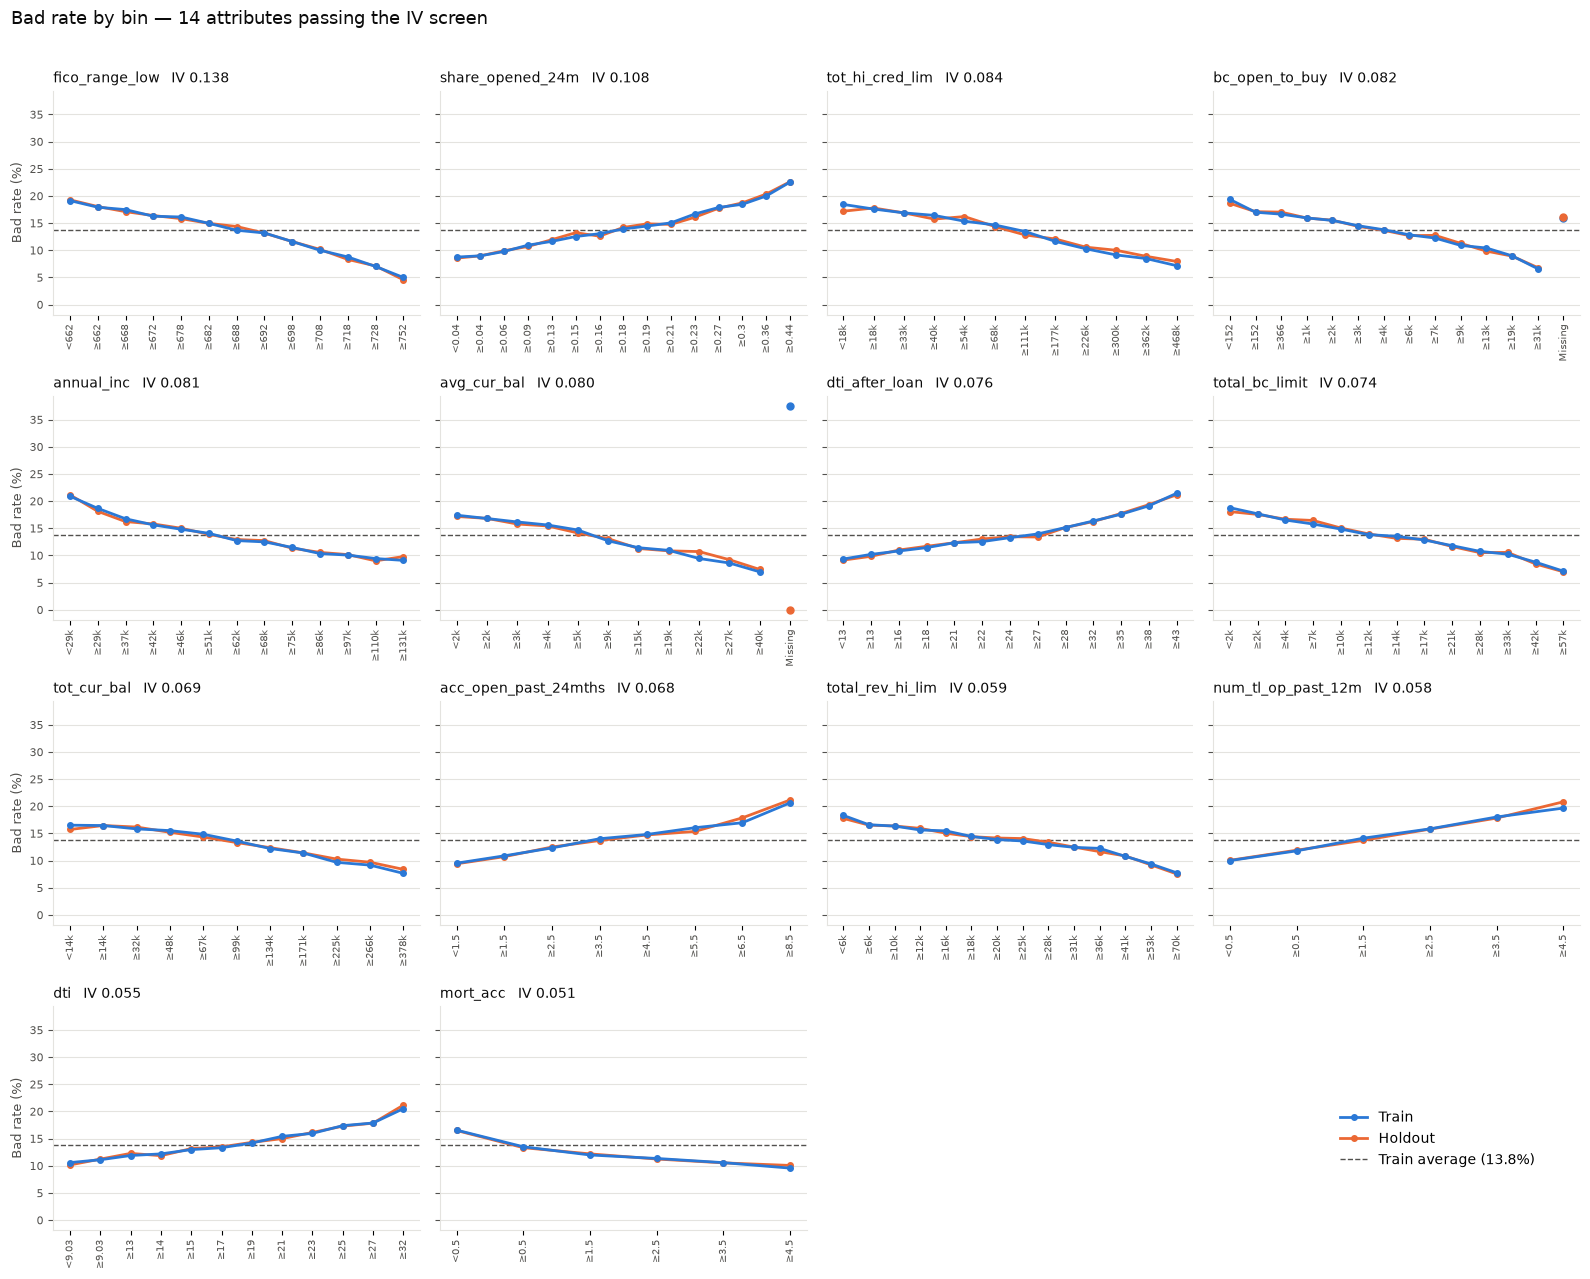

In [41]:
# ---------------------------------------------------------------
# 11.2  Bad rate by bin (train vs holdout) for the 14 IV survivors
# ---------------------------------------------------------------
import matplotlib.pyplot as plt

TRAIN_C, HOLD_C, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'

def short(v):
    """Compact number for tick labels."""
    if not np.isfinite(v): return ''
    if abs(v) >= 1e6: return f'{v/1e6:.1f}M'
    if abs(v) >= 1e3: return f'{v/1e3:.0f}k'
    return f'{v:.2f}'.rstrip('0').rstrip('.') if abs(v) < 10 else f'{v:.0f}'

def bin_rates(var):
    ob = bp.get_binned_variable(var)
    bt = ob.binning_table.build()
    bt = bt[(bt.index != 'Totals') & (bt['Count'] > 0)]
    labels = bt['Bin'].astype(str).tolist()
    tr_rate = (bt['Event rate'].astype(float) * 100).tolist()
    lab_h = pd.Series(ob.transform(hold[var].values, metric='bins')).astype(str)
    ho = hold.bad.reset_index(drop=True).groupby(lab_h).mean() * 100
    ho_rate = [ho.get(l, np.nan) for l in labels]
    if var in cat_vars:
        ticks = [l.replace("'", '').strip('[]')[:18] for l in labels]
    else:
        edges = [-np.inf] + list(ob.splits) + [np.inf]
        ticks = [('<' + short(edges[1])) if i == 0 else ('≥' + short(edges[i])) for i in range(len(edges) - 1)]
        ticks += ['Missing'] * (len(labels) - len(ticks))
    return labels, ticks, tr_rate, ho_rate

avg = train.bad.mean() * 100
fig, axes = plt.subplots(4, 4, figsize=(16, 13), sharey=True)
for ax, var in zip(axes.flat, cand_11):
    labels, ticks, tr_rate, ho_rate = bin_rates(var)
    x = np.arange(len(labels)); num = [i for i, l in enumerate(labels) if l != 'Missing']
    ax.axhline(avg, color=MUTED, lw=1, ls='--', zorder=1)
    ax.plot(x[num], np.array(tr_rate)[num], color=TRAIN_C, lw=2, marker='o', ms=4, zorder=3)
    ax.plot(x[num], np.array(ho_rate)[num], color=HOLD_C, lw=2, marker='o', ms=4, zorder=2)
    miss = [i for i, l in enumerate(labels) if l == 'Missing']
    for i in miss:   # missing bin: separate, unconnected point
        ax.plot(i, tr_rate[i], 'o', color=TRAIN_C, ms=5); ax.plot(i, ho_rate[i], 'o', color=HOLD_C, ms=5)
    ax.set_title(f"{var}   IV {iv_tbl.loc[var, 'IV train']:.3f}", fontsize=10, color=INK, loc='left')
    ax.set_xticks(x); ax.set_xticklabels(ticks, rotation=90, fontsize=7, color=MUTED)
    ax.tick_params(axis='y', labelsize=8, colors=MUTED)
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    for s in ['left', 'bottom']: ax.spines[s].set_color(GRID)
for ax in axes.flat[len(cand_11):]: ax.axis('off')
for ax in axes[:, 0]: ax.set_ylabel('Bad rate (%)', fontsize=9, color=MUTED)
fig.legend(handles=[plt.Line2D([], [], color=TRAIN_C, lw=2, marker='o', ms=4, label='Train'),
                    plt.Line2D([], [], color=HOLD_C, lw=2, marker='o', ms=4, label='Holdout'),
                    plt.Line2D([], [], color=MUTED, lw=1, ls='--', label=f'Train average ({avg:.1f}%)')],
           loc='lower right', bbox_to_anchor=(0.97, 0.08), fontsize=10, frameon=False)
fig.suptitle('Bad rate by bin — 14 attributes passing the IV screen', x=0.01, ha='left', fontsize=13, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/step11_monotonicity.png', dpi=130, facecolor='#fcfcfb')
plt.show()

**Reading the chart**

- **All 14 are monotonic**, and holdout tracks train closely in every panel, so the shapes are not noise.
- **Steepest gradients:** `fico_range_low` (19% → 5%), `share_opened_24m` (9% → 23%), `dti_after_loan` (9% → 21%), `dti` (10% → 21%).
- **Flatter or coarse:** `mort_acc` and `num_tl_op_past_12m` (6 bins each, small integer counts); `tot_cur_bal` is flat across its two lowest bins.
- **Missing bins:**
  - `bc_open_to_buy`: 1.0% of train, 15.9% bad. Slightly riskier than average and consistent on holdout.
  - `avg_cur_bal`: only 8 loans (3 bads), so its 37.5% bad rate is noise. Missing bins this small get a neutral WoE (0) in coarse binning (Step 13), a common treatment for sparse special values.

# Step 12 — Model estimation: stepwise logistic regression on WoE

Each candidate is replaced by the WoE of its bin (Step 11 bins, fitted on train). A logistic regression for P(bad) is then built by **forward stepwise selection**:

1. Start with the intercept only.
2. At each step, try adding each remaining attribute and measure the **gain in McFadden pseudo-R²** on train: pseudo-R² = 1 − LL(model) / LL(intercept only), the likelihood-ratio R².
3. Add the attribute with the largest gain, provided it clears the hurdle, then repeat. The first step that falls below the hurdle ends the model.

**Entry rules** (set before running):

| Rule | Threshold | Why |
|---|---|---|
| Pseudo-R² gain | ≥ 0.001 (0.1 percentage point) | Common stepwise criterion in scorecard development: an attribute must add a minimum amount of fit on top of those already selected. The 0.001 level is this project's choice |
| Sign | All coefficients negative | WoE = ln(%good/%bad), so a higher WoE means safer and should lower P(bad). A positive coefficient means the attribute is behaving opposite to its own bins, a collinearity symptom. Such candidates are skipped |

The path is traced past the hurdle (down to gains of 0.0002) so the cut-off is visible. Holdout and OOT AUC and KS are reported at every step for reference; they play no part in selection.

A. Pool = 14 attributes with IV >= 0.05


,attribute,ΔR²,cumulative R²,AUC holdout,KS holdout,AUC OOT,KS OOT,decision
step,,,,,,,,
1,fico_range_low,0.01916,0.0192,59.8,14.8,60.4,15.5,entered
2,share_opened_24m,0.01193,0.0311,63.0,18.7,63.8,19.8,entered
3,dti_after_loan,0.01140,0.0425,65.3,22.3,66.0,23.1,entered
4,tot_hi_cred_lim,0.00352,0.0460,65.6,22.6,66.3,23.4,entered
5,num_tl_op_past_12m,0.00157,0.0476,65.8,22.9,66.7,24.0,entered
6,bc_open_to_buy,0.00149,0.0491,66.0,23.3,66.9,24.2,entered


B. Pool = 34 attributes with IV >= 0.02


,attribute,ΔR²,cumulative R²,AUC holdout,KS holdout,AUC OOT,KS OOT,decision
step,,,,,,,,
1,fico_range_low,0.01916,0.0192,59.8,14.8,60.4,15.5,entered
2,share_opened_24m,0.01193,0.0311,63.0,18.7,63.8,19.8,entered
3,dti_after_loan,0.01140,0.0425,65.3,22.3,66.0,23.1,entered
4,tot_hi_cred_lim,0.00352,0.0460,65.6,22.6,66.3,23.4,entered
5,inq_last_6mths,0.00272,0.0487,66.0,23.2,66.9,24.2,entered
6,purpose,0.00207,0.0508,66.2,23.7,67.1,24.5,entered
7,bc_open_to_buy,0.00105,0.0519,66.4,23.8,67.2,24.7,entered
8,mths_since_recent_bc,0.00118,0.0530,66.6,24.1,67.4,25.0,entered
9,loan_to_income,0.00101,0.0540,66.7,24.2,67.5,25.3,entered


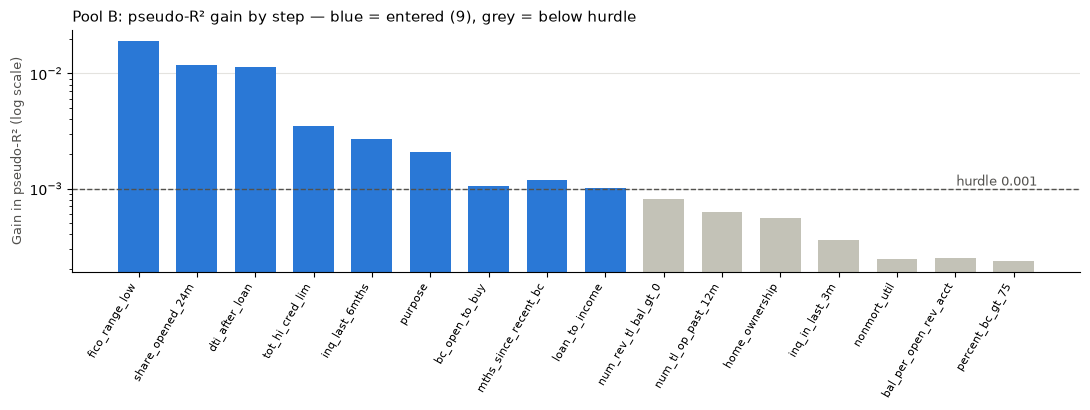

Comparison (points):


,attributes,AUC holdout,KS holdout,AUC OOT,KS OOT
A: pool of 14,6.0,66.0,23.3,66.9,24.2
B: pool of 34 (selected),9.0,66.7,24.2,67.5,25.3
LC sub_grade (champion),NaN,66.0,23.5,68.1,26.6
Step 8 raw-value test model,59.0,67.3,25.3,68.4,26.7


Selected model coefficients (target = bad; WoE inputs, so all should be negative):


,coef,std err
const,-1.8343,0.0059
fico_range_low,-0.6021,0.0196
share_opened_24m,-0.6514,0.0191
dti_after_loan,-0.8191,0.0257
tot_hi_cred_lim,-0.4897,0.0226
inq_last_6mths,-0.7691,0.0325
purpose,-0.8689,0.0407
bc_open_to_buy,-0.5225,0.0261
mths_since_recent_bc,-0.5709,0.0360
loan_to_income,-0.5143,0.0349


In [92]:
# ---------------------------------------------------------------
# 12  Forward stepwise logistic regression on WoE, pseudo-R² entry hurdle
# ---------------------------------------------------------------
import statsmodels.api as sm
import matplotlib.pyplot as plt

def woe_frame(d, cols):
    """Replace each attribute by the WoE of its bin (bins fitted on train in Step 11)."""
    return pd.DataFrame({v: bp.get_binned_variable(v).transform(d[v].values, metric='woe') for v in cols}, index=d.index)

pool_all = cand_11 + weak_band                       # everything with IV >= 0.02
W_tr, W_ho, W_oo = woe_frame(train, pool_all), woe_frame(hold, pool_all), woe_frame(oot, pool_all)
y_tr, y_ho, y_oo = train.bad.astype(int), hold.bad.astype(int), oot.bad.astype(int)

HURDLE = 0.001    # entry: gain in McFadden pseudo-R² >= 0.001 (0.1 percentage point)
TAIL   = 0.0002   # keep tracing the path below the hurdle down to this gain, for display only

def fit(cols):
    X = sm.add_constant(W_tr[cols], has_constant='add') if cols else np.ones((len(W_tr), 1))
    return sm.Logit(y_tr, X).fit(disp=0)

LL_NULL = fit([]).llf
def pseudo_r2(res):                                   # McFadden: 1 - LL(model) / LL(intercept only)
    return 1 - res.llf / LL_NULL

def pred_on(res, cols, W):
    return res.predict(sm.add_constant(W[cols], has_constant='add'))
def auc_on(res, cols, W, y): return auc_pts(y, pred_on(res, cols, W))
def ks_on(res, cols, W, y):  return ks_pts(y, pred_on(res, cols, W))

def forward_path(pool):
    """Each step: among attributes whose coefficients all stay negative, add the one with the largest pseudo-R² gain.
    The path continues past the hurdle (to TAIL) so the cut-off is visible; only steps above the hurdle enter the model."""
    selected, rows, current, entering = [], [], fit([]), True
    while True:
        best = None
        for v in [c for c in pool if c not in selected]:
            res = fit(selected + [v])
            if not (res.params.drop('const') < 0).all():          # sign rule: skip attributes that flip a coefficient
                continue
            gain = pseudo_r2(res) - pseudo_r2(current)
            if best is None or gain > best[1]:
                best = (v, gain, res)
        if best is None or best[1] < TAIL: break
        v, gain, res = best
        entering = entering and gain >= HURDLE                     # first step below the hurdle ends the model
        selected.append(v); current = res
        rows.append({'step': len(selected), 'attribute': v, 'ΔR²': gain, 'cumulative R²': pseudo_r2(res),
                     'AUC holdout': auc_on(res, selected, W_ho, y_ho), 'KS holdout': ks_on(res, selected, W_ho, y_ho),
                     'AUC OOT': auc_on(res, selected, W_oo, y_oo), 'KS OOT': ks_on(res, selected, W_oo, y_oo),
                     'decision': 'entered' if entering else 'below hurdle'})
    return pd.DataFrame(rows).set_index('step')

path_A = forward_path(cand_11)
path_B = forward_path(pool_all)

for name, path in [('A. Pool = 14 attributes with IV >= 0.05', path_A), (f'B. Pool = {len(pool_all)} attributes with IV >= 0.02', path_B)]:
    print(name); display(path.style.format({'ΔR²': '{:.5f}', 'cumulative R²': '{:.4f}', 'AUC holdout': '{:.1f}', 'KS holdout': '{:.1f}',
                                            'AUC OOT': '{:.1f}', 'KS OOT': '{:.1f}'}))

# Chart: pseudo-R² gain at each step of path B, with the hurdle
fig, ax = plt.subplots(figsize=(11, 4.2))
cols_ = ['#2a78d6' if d == 'entered' else '#c3c2b7' for d in path_B['decision']]
ax.bar(range(1, len(path_B) + 1), path_B['ΔR²'], color=cols_, width=0.7)
ax.axhline(HURDLE, color='#52514e', lw=1, ls='--')
ax.text(len(path_B) + 0.4, HURDLE, f'hurdle {HURDLE}', va='bottom', ha='right', fontsize=9, color='#52514e')
ax.set_yscale('log'); ax.set_ylabel('Gain in pseudo-R² (log scale)', fontsize=9, color='#52514e')
ax.set_xticks(range(1, len(path_B) + 1)); ax.set_xticklabels(path_B['attribute'], rotation=60, ha='right', fontsize=8)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e4e3df', lw=0.8); ax.set_axisbelow(True)
ax.set_title(f"Pool B: pseudo-R² gain by step — blue = entered ({(path_B.decision == 'entered').sum()}), grey = below hurdle",
             loc='left', fontsize=11)
fig.tight_layout(); os.makedirs('figures', exist_ok=True); fig.savefig('figures/step12_r2_gain.png', dpi=130, facecolor='#fcfcfb'); plt.show()

# Selected model = path B up to the cut
sel_12 = path_B.index[path_B.decision == 'entered'].map(path_B['attribute']).tolist()
model_12 = fit(sel_12)
def perf_row(n_attr, p_ho_, p_oo_, name):
    return pd.Series({'attributes': n_attr, 'AUC holdout': auc_pts(y_ho, p_ho_), 'KS holdout': ks_pts(y_ho, p_ho_),
                      'AUC OOT': auc_pts(y_oo, p_oo_), 'KS OOT': ks_pts(y_oo, p_oo_)}, name=name)
sel_A = path_A.index[path_A.decision == 'entered'].map(path_A['attribute']).tolist()
model_A = fit(sel_A)
bench = pd.DataFrame([
    perf_row(len(sel_A), pred_on(model_A, sel_A, W_ho), pred_on(model_A, sel_A, W_oo), 'A: pool of 14'),
    perf_row(len(sel_12), pred_on(model_12, sel_12, W_ho), pred_on(model_12, sel_12, W_oo), f'B: pool of {len(pool_all)} (selected)'),
    perf_row(np.nan, sg(hold), sg(oot), 'LC sub_grade (champion)'),
    perf_row(59, p_hold_single, p_oot_single, 'Step 8 raw-value test model'),
])
print('Comparison (points):'); display(bench.round(1))
print('Selected model coefficients (target = bad; WoE inputs, so all should be negative):')
display(pd.DataFrame({'coef': model_12.params, 'std err': model_12.bse}).round(4))

## 12.1 Takeaways - stepwise selection (done)

**Pool A (14 attributes, IV >= 0.05):** 6 attributes clear the hurdle; holdout AUC 66.0 / KS 23.3, OOT AUC 66.9 / KS 24.2. That only ties the champion on holdout and trails it on OOT, and several of the 14 duplicate each other (limits and balances), so the 0.02-0.05 weak band was opened as planned in Step 11.

**Pool B (34 attributes, IV >= 0.02), the selected model: 9 attributes.**

| Step | Attribute | Pseudo-R2 gain | Cumulative pseudo-R2 | AUC holdout | KS holdout | AUC OOT | KS OOT | Status |
|---|---|---|---|---|---|---|---|---|
| 1 | `fico_range_low` | 0.0192 | 0.0192 | 59.8 | 14.8 | 60.4 | 15.5 | entered |
| 2 | `share_opened_24m` | 0.0119 | 0.0311 | 63.0 | 18.7 | 63.8 | 19.8 | entered |
| 3 | `dti_after_loan` | 0.0114 | 0.0425 | 65.3 | 22.3 | 66.0 | 23.1 | entered |
| 4 | `tot_hi_cred_lim` | 0.0035 | 0.0460 | 65.6 | 22.6 | 66.3 | 23.4 | entered |
| 5 | `inq_last_6mths` | 0.0027 | 0.0487 | 66.0 | 23.2 | 66.9 | 24.2 | entered |
| 6 | `purpose` | 0.0021 | 0.0508 | 66.2 | 23.7 | 67.1 | 24.5 | entered |
| 7 | `bc_open_to_buy` | 0.0010 | 0.0519 | 66.4 | 23.8 | 67.2 | 24.7 | entered |
| 8 | `mths_since_recent_bc` | 0.0012 | 0.0530 | 66.6 | 24.1 | 67.4 | 25.0 | entered |
| 9 | `loan_to_income` | 0.0010 | 0.0540 | 66.7 | 24.2 | 67.5 | 25.3 | entered |
| - | **hurdle 0.001** | | | | | | | |
| 10 | `num_rev_tl_bal_gt_0` | 0.0008 | 0.0549 | 66.7 | 24.2 | 67.6 | 25.4 | below hurdle |
| 11 | `num_tl_op_past_12m` | 0.0006 | 0.0555 | 66.8 | 24.3 | 67.7 | 25.5 | below hurdle |
| 12 | `home_ownership` | 0.0006 | 0.0560 | 66.9 | 24.4 | 67.9 | 25.6 | below hurdle |
| 13-16 | `inq_in_last_3m`, `nonmort_util`, `bal_per_open_rev_acct`, `percent_bc_gt_75` | 0.0002-0.0004 each | 0.0571 | 67.1 | 24.7 | 68.1 | 25.9 | below hurdle |

| Model | Attributes | AUC holdout | KS holdout | AUC OOT | KS OOT |
|---|---|---|---|---|---|
| **Selected (B, cut at hurdle)** | **9** | **66.7** | **24.2** | **67.5** | **25.3** |
| LC `sub_grade` (champion) | n/a | 66.0 | 23.5 | 68.1 | 26.6 |
| Step 8 raw-value test model | 59 inputs | 67.3 | 25.3 | 68.4 | 26.7 |

- **The first three attributes carry most of the model:** pseudo-R2 0.043 of 0.054; holdout AUC 65.3 of 66.7 and KS 22.3 of 24.2.
- **The selected model beats the champion on holdout** (AUC +0.7, KS +0.7) **and trails it on OOT** (AUC −0.6, KS −1.3).
- **Below the hurdle, the next 7 attributes add about 0.4 holdout and 0.6 OOT AUC points combined** (KS +0.5 / +0.6). That is the cost of the 0.001 cut-off, the trade-off for a simpler, more stable scorecard. Lowering the hurdle to 0.0005 would admit `num_rev_tl_bal_gt_0`, `num_tl_op_past_12m` and `home_ownership` (12 attributes).
- **3 of the 9 are derived:** `share_opened_24m`, `dti_after_loan`, `loan_to_income`. Raw `dti`, `annual_inc` and `acc_open_past_24mths` never lead a step: their derived versions carry the signal.
- **All 9 coefficients are negative.**

The selected attributes are `sel_12`, and the fitted model is `model_12`. Coarse binning (Step 13) and VIF (Step 14) follow.

# Step 13 — Coarse binning of finalists ⏭️ (deferred)

Skipped for now; to revisit before scaling. What it would cover:

- **Fewer, readable bins.** Step 11 left the finalists with fine bins (e.g. `fico_range_low` 13, `share_opened_24m` 15, `tot_hi_cred_lim` 12, `bc_open_to_buy` 13). A production scorecard would merge to about 5–8 bins per attribute, via `max_n_bins` or rounded `user_splits` (e.g. FICO 680 / 700 / 720 …).
- **Enough bads per bin** (`min_bin_n_event`) and **adjacent bins that differ** (`max_pvalue = 0.05`); the 5% size rule alone guarantees neither.
- **`purpose`:** group small categories into a few sensible groups.
- **Re-check** bad rate by bin on holdout / OOT, then refit `model_12` on the coarse WoE and confirm AUC and KS move only slightly from 66.7 / 67.5 and 24.2 / 25.3 (holdout / OOT).

Steps 14 onward use the Step 11 bins as they are.

# Step 14 — Collinearity / VIF

`optbinning` bins each attribute on its own, and stepwise selection only rejects attributes that add little fit, so two correlated attributes can both enter. Collinearity makes coefficients unstable and can flip their signs, which breaks reason codes.

| Check | Rule |
|---|---|
| **VIF** = 1 / (1 − R²) of each attribute's WoE regressed on the other 8 | < 10 (common industry threshold); < 5 preferred |
| Pairwise correlation of WoE values | flag \|r\| ≥ 0.5 for a closer look |
| Coefficient signs and standard errors | all negative (WoE inputs); no inflated standard errors |
| Stability | VIF on holdout and OOT close to train |
| Drop-one test for flagged pairs | AUC and KS lost if either member of a correlated pair is removed |

VIF and coefficients for the 9 selected attributes (WoE inputs):


,VIF train,VIF holdout,VIF OOT,coef,std err,coef / std err,pass (< 10)
loan_to_income,1.62,1.63,1.56,-0.514,0.035,-14.7,True
bc_open_to_buy,1.57,1.58,1.63,-0.523,0.026,-20.1,True
dti_after_loan,1.54,1.55,1.48,-0.819,0.026,-31.8,True
fico_range_low,1.48,1.48,1.53,-0.602,0.020,-30.7,True
mths_since_recent_bc,1.28,1.28,1.34,-0.571,0.036,-15.8,True
share_opened_24m,1.24,1.24,1.29,-0.651,0.019,-34.2,True
tot_hi_cred_lim,1.20,1.20,1.20,-0.490,0.023,-21.6,True
inq_last_6mths,1.06,1.06,1.09,-0.769,0.032,-23.7,True
purpose,1.02,1.02,1.02,-0.869,0.041,-21.4,True


WoE correlation pairs with |r| >= 0.3 (train):


,attribute 1,attribute 2,r
20,dti_after_loan,loan_to_income,0.58
5,fico_range_low,bc_open_to_buy,0.53
13,share_opened_24m,mths_since_recent_bc,0.38


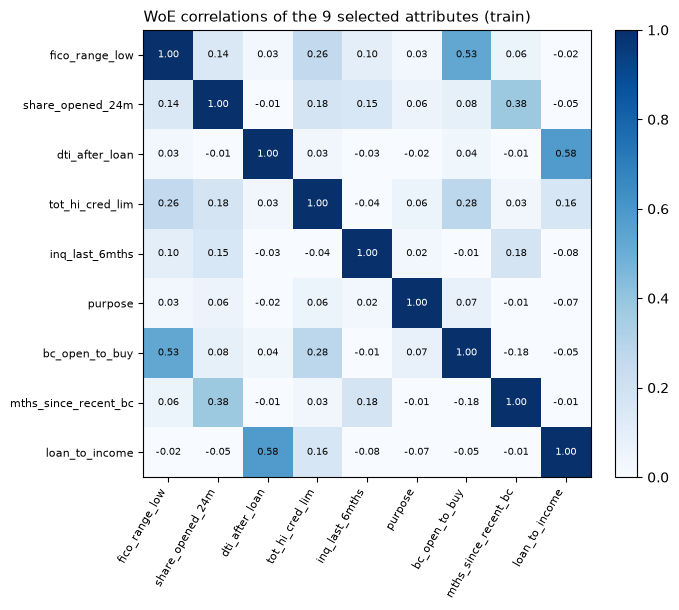

Drop-one test (full 9-attribute model: holdout AUC 66.7 / KS 24.2; OOT AUC 67.5 / KS 25.3):


,pseudo-R² lost,Δ AUC holdout,Δ KS holdout,Δ AUC OOT,Δ KS OOT,all coefs negative
dropped,,,,,,
dti_after_loan,0.0047,-0.87,-1.11,-0.88,-1.55,True
loan_to_income,0.0010,-0.09,-0.07,-0.10,-0.29,True
fico_range_low,0.0046,-0.84,-1.34,-0.72,-1.04,True
bc_open_to_buy,0.0019,-0.29,-0.26,-0.20,-0.46,True


In [93]:
# ---------------------------------------------------------------
# 14  Collinearity: VIF, WoE correlations, coefficient check, drop-one test
# ---------------------------------------------------------------
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_table(W, cols):
    """VIF of each attribute's WoE regressed on the others (with intercept)."""
    X = sm.add_constant(W[cols], has_constant='add').values
    return pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=cols)

vif_14 = pd.DataFrame({'VIF train': vif_table(W_tr, sel_12),
                       'VIF holdout': vif_table(W_ho, sel_12),
                       'VIF OOT': vif_table(W_oo, sel_12),
                       'coef': model_12.params[sel_12],
                       'std err': model_12.bse[sel_12]})
vif_14['coef / std err'] = vif_14['coef'] / vif_14['std err']
vif_14['pass (< 10)'] = vif_14['VIF train'] < 10
vif_14 = vif_14.sort_values('VIF train', ascending=False)
print('VIF and coefficients for the 9 selected attributes (WoE inputs):')
display(vif_14.style.format({'VIF train': '{:.2f}', 'VIF holdout': '{:.2f}', 'VIF OOT': '{:.2f}',
                             'coef': '{:.3f}', 'std err': '{:.3f}', 'coef / std err': '{:.1f}'}))

# Pairwise correlation of WoE values (train): pairs with |r| >= 0.3
corr_14 = W_tr[sel_12].corr()
pairs = (corr_14.where(np.triu(np.ones(corr_14.shape, bool), k=1)).stack()
         .rename('r').reset_index().rename(columns={'level_0': 'attribute 1', 'level_1': 'attribute 2'}))
pairs = pairs[pairs.r.abs() >= 0.3].sort_values('r', key=abs, ascending=False)
print('WoE correlation pairs with |r| >= 0.3 (train):'); display(pairs.round(2))

# Heatmap of WoE correlations
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr_14.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(sel_12))); ax.set_xticklabels(sel_12, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(sel_12))); ax.set_yticklabels(sel_12, fontsize=8)
for i in range(len(sel_12)):
    for j in range(len(sel_12)):
        r = corr_14.values[i, j]
        ax.text(j, i, f'{r:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(r) > 0.6 else '#0b0b0b')
ax.set_title('WoE correlations of the 9 selected attributes (train)', loc='left', fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); fig.tight_layout()
fig.savefig('figures/step14_woe_corr.png', dpi=130, facecolor='#fcfcfb'); plt.show()

# Drop-one test for the flagged pairs (|r| >= 0.5): AUC / KS cost of removing each member
base = {k: f(model_12, sel_12, W, y) for k, (f, W, y) in
        {'AUC holdout': (auc_on, W_ho, y_ho), 'KS holdout': (ks_on, W_ho, y_ho),
         'AUC OOT': (auc_on, W_oo, y_oo), 'KS OOT': (ks_on, W_oo, y_oo)}.items()}
rows = []
for v in pd.unique(pairs.loc[pairs.r.abs() >= 0.5, ['attribute 1', 'attribute 2']].values.ravel()):
    cols = [c for c in sel_12 if c != v]
    res = fit(cols)
    row = {'dropped': v, 'pseudo-R² lost': pseudo_r2(model_12) - pseudo_r2(res)}
    for k, (f, W, y) in {'AUC holdout': (auc_on, W_ho, y_ho), 'KS holdout': (ks_on, W_ho, y_ho),
                         'AUC OOT': (auc_on, W_oo, y_oo), 'KS OOT': (ks_on, W_oo, y_oo)}.items():
        row[f'Δ {k}'] = f(res, cols, W, y) - base[k]
    row['all coefs negative'] = bool((res.params.drop('const') < 0).all())
    rows.append(row)
drop_14 = pd.DataFrame(rows).set_index('dropped')
print(f"Drop-one test (full 9-attribute model: holdout AUC {base['AUC holdout']:.1f} / KS {base['KS holdout']:.1f}; "
      f"OOT AUC {base['AUC OOT']:.1f} / KS {base['KS OOT']:.1f}):")
display(drop_14.style.format({'pseudo-R² lost': '{:.4f}', 'Δ AUC holdout': '{:+.2f}', 'Δ KS holdout': '{:+.2f}',
                              'Δ AUC OOT': '{:+.2f}', 'Δ KS OOT': '{:+.2f}'}))

## 14.1 Takeaways — collinearity ✅

| Attribute | VIF train | VIF holdout | VIF OOT | coef | coef / std err |
|---|---|---|---|---|---|
| `loan_to_income` | 1.62 | 1.63 | 1.56 | −0.514 | −14.7 |
| `bc_open_to_buy` | 1.58 | 1.58 | 1.63 | −0.523 | −20.1 |
| `dti_after_loan` | 1.54 | 1.55 | 1.48 | −0.819 | −31.8 |
| `fico_range_low` | 1.48 | 1.48 | 1.53 | −0.602 | −30.7 |
| `mths_since_recent_bc` | 1.28 | 1.28 | 1.34 | −0.571 | −15.8 |
| `share_opened_24m` | 1.24 | 1.24 | 1.29 | −0.651 | −34.2 |
| `tot_hi_cred_lim` | 1.20 | 1.20 | 1.20 | −0.490 | −21.6 |
| `inq_last_6mths` | 1.06 | 1.06 | 1.10 | −0.769 | −23.7 |
| `purpose` | 1.02 | 1.02 | 1.02 | −0.869 | −21.4 |

- **No collinearity problem.** Highest VIF is 1.62, far below the threshold of 10 and below 2. VIFs on holdout and OOT are within 0.07 of train.
- **All 9 coefficients are negative**, with |coef / std err| ≥ 14.7, so no sign flips or inflated standard errors.
- **Two correlated pairs (|r| ≥ 0.5) are worth noting but keeping:**
  - `dti_after_loan` / `loan_to_income` (r = 0.58): both measure affordability. `loan_to_income` adds only 0.1 AUC (0.1–0.3 KS) once `dti_after_loan` is in; it entered last, right at the 0.001 hurdle (gain 0.0010). Keep it, but it is the first candidate to drop if a simpler model is wanted.
  - `fico_range_low` / `bc_open_to_buy` (r = 0.53): FICO partly reflects available revolving credit. Each adds its own signal (−0.8 and −0.3 holdout AUC if dropped), so both stay.
- `share_opened_24m` / `mths_since_recent_bc` (r = 0.38) is below the flag level.

**Drop-one test** (AUC and KS cost of removing each member of a flagged pair):

| Dropped | Pseudo-R² lost | Δ AUC holdout | Δ KS holdout | Δ AUC OOT | Δ KS OOT |
|---|---|---|---|---|---|
| `dti_after_loan` | 0.0047 | −0.87 | −1.11 | −0.88 | −1.55 |
| `loan_to_income` | 0.0010 | −0.09 | −0.07 | −0.10 | −0.29 |
| `fico_range_low` | 0.0046 | −0.84 | −1.34 | −0.72 | −1.04 |
| `bc_open_to_buy` | 0.0019 | −0.29 | −0.26 | −0.20 | −0.46 |

**Decision:** keep all 9 attributes (`sel_12`, `model_12`) unchanged. Next: Step 15, scaling and calibration.

# Step 15 - Scaling & calibration

**Scaling** turns the model's log-odds into scorecard points; it changes the units, not the ranking. **Calibration** checks whether predicted bad rates match actual ones.

**Scaling convention** (a common industry choice; scores rise as risk falls):

| Parameter | Value |
|---|---|
| Base score | 600 points at good:bad odds of 50:1 |
| PDO (points to double the odds) | 20 |
| Factor = PDO / ln(2) | 28.85 |
| Offset = 600 - Factor * ln(50) | 487.1 |

Score = Offset + Factor * ln(good:bad odds). With the model fitted on WoE, logit(PD) = b0 + sum of b_j * WoE_j, so the points for bin i of attribute j are

**points(i, j) = -Factor * b_j * WoE(i, j) + (Offset - Factor * b0) / n**, rounded to whole points, with n = 9 attributes.

**Calibration checks** (accepts only, since reject inference was diagnostic in Step 7; so probabilities should match train by construction, and the real test is holdout / OOT):

| Check | Tolerance |
|---|---|
| Overall: actual / predicted bad rate | within +/-10% |
| By decile of predicted PD | each decile within +/-10% relative, or inside its binomial 95% interval |
| Calibration slope: fit bad on logit(predicted PD) | close to 1 |
| Odds-to-score: actual ln(good:bad odds) by score band | slope close to ln(2) / 20 (i.e. actual PDO close to 20) |

Factor 28.85, Offset 487.1, intercept share per attribute 60.0 points
Points range by attribute (bins with data):


,min,max,range
attribute,,,
fico_range_low,53,79,26
dti_after_loan,47,70,23
share_opened_24m,49,70,21
bc_open_to_buy,54,72,18
tot_hi_cred_lim,55,70,15
mths_since_recent_bc,56,68,12
purpose,53,65,12
inq_last_6mths,52,63,11
loan_to_income,54,64,10


Score range train: 484–620, median 543


holdout: AUC model 66.68 vs score 66.65 | KS model 24.18 vs score 23.95


OOT: AUC model 67.50 vs score 67.47 | KS model 25.31 vs score 25.23


holdout: actual PDO = ln2 / slope = 21.9 points (target 20)
OOT: actual PDO = ln2 / slope = 20.6 points (target 20)


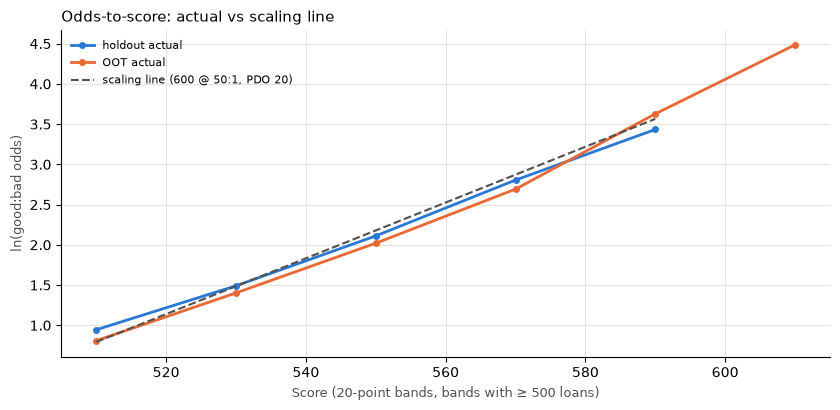

Scorecard (first attribute shown; full table in scorecard_15):


,attribute,bin,count,bad rate,WoE,points
0,fico_range_low,"(-inf, 662.50)",25918,0.1914,-0.3921,53
1,fico_range_low,"[662.50, 667.50)",25261,0.1792,-0.3115,55
2,fico_range_low,"[667.50, 672.50)",25213,0.1748,-0.2812,55
3,fico_range_low,"[672.50, 677.50)",22149,0.1627,-0.1945,57
4,fico_range_low,"[677.50, 682.50)",21756,0.1612,-0.1839,57
5,fico_range_low,"[682.50, 687.50)",18945,0.1495,-0.0947,58
6,fico_range_low,"[687.50, 692.50)",18197,0.1368,0.0089,60
7,fico_range_low,"[692.50, 697.50)",16169,0.1319,0.0517,61
8,fico_range_low,"[697.50, 707.50)",27045,0.1161,0.1973,63
9,fico_range_low,"[707.50, 717.50)",20509,0.1000,0.3642,66


In [95]:
# ---------------------------------------------------------------
# 15a  Scaling: log-odds -> points (600 at 50:1 good:bad, PDO 20)
# ---------------------------------------------------------------
BASE_SCORE, BASE_ODDS, PDO = 600, 50, 20
FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)
b0, betas, n_attr = model_12.params['const'], model_12.params[sel_12], len(sel_12)
SHARE = (OFFSET - FACTOR * b0) / n_attr          # intercept spread evenly across attributes
print(f'Factor {FACTOR:.2f}, Offset {OFFSET:.1f}, intercept share per attribute {SHARE:.1f} points')

# Scorecard table: points for every bin of every attribute (bins and WoE from Step 11, train)
rows = []
for v in sel_12:
    bt = bp.get_binned_variable(v).binning_table.build()
    bt = bt[bt.index != 'Totals']
    for _, r in bt.iterrows():
        rows.append({'attribute': v, 'bin': str(r['Bin']), 'count': int(r['Count']), 'bad rate': float(r['Event rate']) if r['Count'] > 0 else np.nan,
                     'WoE': float(r['WoE']), 'points': int(round(-FACTOR * betas[v] * float(r['WoE']) + SHARE))})
scorecard_15 = pd.DataFrame(rows)

def score_points(W):
    """Integer score: sum of rounded bin points (same rounding as the scorecard table)."""
    return sum(np.round(-FACTOR * betas[v] * W[v] + SHARE) for v in sel_12).astype(int)

S_tr, S_ho, S_oo = score_points(W_tr[sel_12]), score_points(W_ho[sel_12]), score_points(W_oo[sel_12])
pd_tr = model_12.predict(sm.add_constant(W_tr[sel_12], has_constant='add'))
pd_ho = model_12.predict(sm.add_constant(W_ho[sel_12], has_constant='add'))
pd_oo = model_12.predict(sm.add_constant(W_oo[sel_12], has_constant='add'))

# Points range per attribute = how far each attribute can move the score
rng = scorecard_15[scorecard_15['count'] > 0].groupby('attribute', sort=False)['points'].agg(['min', 'max'])
rng['range'] = rng['max'] - rng['min']
print('Points range by attribute (bins with data):'); display(rng.sort_values('range', ascending=False))

# Rounding check: integer score vs unrounded model (AUC / KS on the score should match the model)
print(f"Score range train: {S_tr.min()}–{S_tr.max()}, median {int(S_tr.median())}")
for name, y, p, S in [('holdout', y_ho, pd_ho, S_ho), ('OOT', y_oo, pd_oo, S_oo)]:
    print(f"{name}: AUC model {auc_pts(y, p):.2f} vs score {auc_pts(y, -S):.2f} | "
          f"KS model {ks_pts(y, p):.2f} vs score {ks_pts(y, -S):.2f}")

# Odds-to-score check (holdout and OOT): actual ln(good:bad odds) by 20-point score band
def odds_by_band(S, y, width=20):
    band = (S // width) * width
    g = pd.DataFrame({'band': band, 'bad': y.values}).groupby('band').bad.agg(['size', 'sum'])
    g = g[(g['size'] >= 500) & (g['sum'] > 0)]
    g['actual ln odds'] = np.log((g['size'] - g['sum']) / g['sum'])
    g['expected ln odds'] = (g.index + width / 2 - OFFSET) / FACTOR
    return g
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for name, S, y, c in [('holdout', S_ho, y_ho, '#2a78d6'), ('OOT', S_oo, y_oo, '#eb6834')]:
    g = odds_by_band(S, y)
    slope = np.polyfit(g.index + 10, g['actual ln odds'], 1, w=np.sqrt(g['size']))[0]
    print(f'{name}: actual PDO = ln2 / slope = {np.log(2)/slope:.1f} points (target {PDO})')
    ax.plot(g.index + 10, g['actual ln odds'], 'o-', color=c, lw=2, ms=4, label=f'{name} actual')
g = odds_by_band(S_ho, y_ho)
ax.plot(g.index + 10, g['expected ln odds'], '--', color='#52514e', lw=1.5, label='scaling line (600 @ 50:1, PDO 20)')
ax.set_xlabel('Score (20-point bands, bands with ≥ 500 loans)', fontsize=9, color='#52514e')
ax.set_ylabel('ln(good:bad odds)', fontsize=9, color='#52514e')
ax.legend(fontsize=8, frameon=False); ax.grid(color='#e4e3df', lw=0.8); ax.set_axisbelow(True)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.set_title('Odds-to-score: actual vs scaling line', loc='left', fontsize=11)
fig.tight_layout(); fig.savefig('figures/step15_odds_to_score.png', dpi=130, facecolor='#fcfcfb'); plt.show()

print('Scorecard (first attribute shown; full table in scorecard_15):')
display(scorecard_15[scorecard_15.attribute == 'fico_range_low'].round(4))

Overall calibration:


,actual,predicted,actual / predicted,cal. intercept a,cal. slope b
train,13.79%,13.79%,1.000,0.000,1.000
holdout,13.79%,13.77%,1.001,-0.023,0.985
OOT,14.74%,13.60%,1.083,0.117,1.011


Decile calibration — holdout (deciles cut on train PD; 1 = riskiest):


,n,predicted,actual,ratio,inside 95% CI,within ±10%
d,,,,,,
1,11292,28.61%,27.58%,0.964,False,True
2,11264,21.51%,22.05%,1.025,True,True
3,11650,18.12%,18.23%,1.006,True,True
4,11476,15.63%,15.59%,0.998,True,True
5,11669,13.57%,14.23%,1.049,False,True
6,11422,11.73%,11.95%,1.019,True,True
7,11665,10.02%,10.01%,0.999,True,True
8,11257,8.32%,8.31%,1.000,True,True
9,11388,6.46%,6.11%,0.946,True,True


Decile calibration — OOT (deciles cut on train PD; 1 = riskiest):


,n,predicted,actual,ratio,inside 95% CI,within ±10%
d,,,,,,
1,16340,28.71%,30.47%,1.061,False,True
2,15606,21.51%,23.32%,1.085,False,True
3,15634,18.11%,19.69%,1.087,False,True
4,15406,15.62%,16.96%,1.086,False,True
5,15532,13.57%,15.12%,1.115,False,False
6,15552,11.74%,12.56%,1.070,False,True
7,15588,10.03%,11.18%,1.114,False,False
8,16003,8.32%,9.29%,1.117,False,False
9,16907,6.45%,7.20%,1.117,False,False


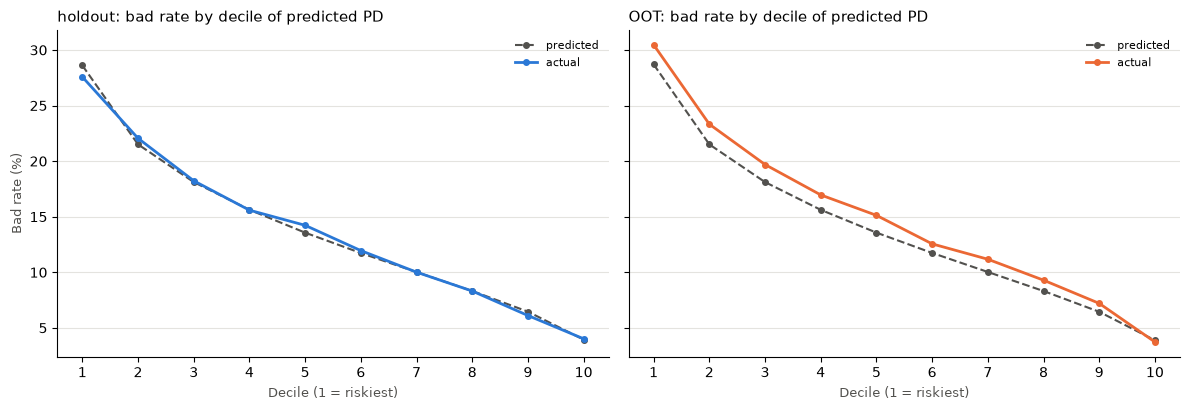

In [62]:
# ---------------------------------------------------------------
# 15b  Calibration: predicted vs actual bad rate (train / holdout / OOT)
# ---------------------------------------------------------------
from scipy.stats import norm

def calib_summary(p, y):
    """Overall ratio and calibration slope/intercept: logit fit of y on logit(p)."""
    lp = np.log(p / (1 - p))
    fit_ = sm.Logit(y.values, sm.add_constant(lp.values)).fit(disp=0)
    return {'actual': y.mean(), 'predicted': p.mean(), 'actual / predicted': y.mean() / p.mean(),
            'cal. intercept a': fit_.params[0], 'cal. slope b': fit_.params[1]}

summ_15 = pd.DataFrame({name: calib_summary(p, y) for name, p, y in
                        [('train', pd_tr, y_tr), ('holdout', pd_ho, y_ho), ('OOT', pd_oo, y_oo)]}).T
print('Overall calibration:')
display(summ_15.style.format({'actual': '{:.2%}', 'predicted': '{:.2%}', 'actual / predicted': '{:.3f}',
                              'cal. intercept a': '{:.3f}', 'cal. slope b': '{:.3f}'}))

# Decile table: deciles of predicted PD cut on train, applied to holdout / OOT; decile 1 = riskiest
edges = np.unique(np.quantile(pd_tr, np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
def decile_table(p, y):
    d = 10 - pd.cut(p, edges, labels=False)                       # 1 = highest PD
    g = pd.DataFrame({'d': d, 'p': p.values, 'y': y.values}).groupby('d').agg(n=('y', 'size'), predicted=('p', 'mean'), actual=('y', 'mean'))
    g['ratio'] = g['actual'] / g['predicted']
    se = np.sqrt(g['predicted'] * (1 - g['predicted']) / g['n'])
    g['inside 95% CI'] = (g['actual'] - g['predicted']).abs() <= norm.ppf(0.975) * se
    g['within ±10%'] = (g['ratio'] - 1).abs() <= 0.10
    return g
dec = {name: decile_table(p, y) for name, p, y in [('train', pd_tr, y_tr), ('holdout', pd_ho, y_ho), ('OOT', pd_oo, y_oo)]}
for name in ['holdout', 'OOT']:
    print(f'Decile calibration — {name} (deciles cut on train PD; 1 = riskiest):')
    display(dec[name].style.format({'predicted': '{:.2%}', 'actual': '{:.2%}', 'ratio': '{:.3f}'}))

# Chart: predicted vs actual by decile
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, name, c in zip(axes, ['holdout', 'OOT'], ['#2a78d6', '#eb6834']):
    g = dec[name]
    ax.plot(g.index, 100 * g['predicted'], '--', color='#52514e', lw=1.5, marker='o', ms=4, label='predicted')
    ax.plot(g.index, 100 * g['actual'], '-', color=c, lw=2, marker='o', ms=4, label='actual')
    ax.set_title(f'{name}: bad rate by decile of predicted PD', loc='left', fontsize=11)
    ax.set_xticks(g.index); ax.set_xlabel('Decile (1 = riskiest)', fontsize=9, color='#52514e')
    ax.grid(axis='y', color='#e4e3df', lw=0.8); ax.set_axisbelow(True); ax.legend(fontsize=8, frameon=False)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
axes[0].set_ylabel('Bad rate (%)', fontsize=9, color='#52514e')
fig.tight_layout(); fig.savefig('figures/step15_calibration_deciles.png', dpi=130, facecolor='#fcfcfb'); plt.show()

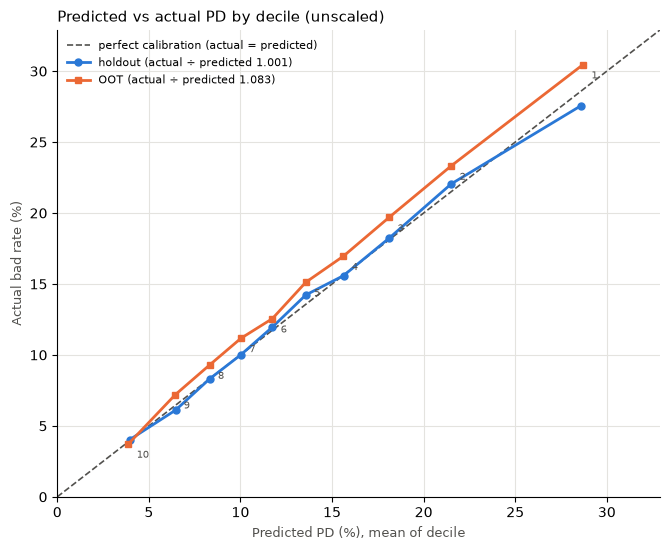

In [67]:
# ---------------------------------------------------------------
# 15c  Odds-to-score chart without scaling: actual vs predicted PD (reliability plot)
# ---------------------------------------------------------------
# Same bands as the deciles above (cut on train PD); x = mean predicted PD, y = actual bad rate
fig, ax = plt.subplots(figsize=(6.8, 5.6))
lim = 100 * max(dec['OOT']['actual'].max(), dec['holdout']['predicted'].max()) * 1.08
ax.plot([0, lim], [0, lim], '--', color='#52514e', lw=1.2, label='perfect calibration (actual = predicted)')
for name, c, m in [('holdout', '#2a78d6', 'o'), ('OOT', '#eb6834', 's')]:
    g = dec[name]
    ax.plot(100 * g['predicted'], 100 * g['actual'], '-', color=c, lw=2, marker=m, ms=5,
            label=f"{name} (actual ÷ predicted {summ_15.loc[name, 'actual / predicted']:.3f})")
for d, r in dec['OOT'].iterrows():                                  # decile labels on the OOT line
    ax.annotate(str(d), (100 * r['predicted'], 100 * r['actual']), textcoords='offset points', xytext=(6, -10),
                fontsize=7, color='#52514e')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Predicted PD (%), mean of decile', fontsize=9, color='#52514e')
ax.set_ylabel('Actual bad rate (%)', fontsize=9, color='#52514e')
ax.set_title('Predicted vs actual PD by decile (unscaled)', loc='left', fontsize=11)
ax.legend(fontsize=8, frameon=False, loc='upper left'); ax.grid(color='#e4e3df', lw=0.8); ax.set_axisbelow(True)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig('figures/step15_pd_reliability.png', dpi=130, facecolor='#fcfcfb'); plt.show()

holdout: actual vs predicted by 2.5-point PD band


,n,predicted,actual,actual / predicted
band,,,,
0.0-2.5,"1,228",2.1%,2.0%,0.95
2.5-5.0,"8,302",3.9%,3.8%,0.97
5.0-7.5,"13,713",6.3%,6.2%,0.98
7.5-10.0,"16,605",8.8%,8.6%,0.98
10.0-12.5,"16,564",11.2%,11.5%,1.02
12.5-15.0,"15,008",13.7%,14.1%,1.03
15.0-17.5,"12,264",16.2%,16.3%,1.01
17.5-20.0,"9,748",18.7%,19.0%,1.02
20.0-22.5,"6,955",21.2%,21.3%,1.00


OOT: actual vs predicted by 2.5-point PD band


,n,predicted,actual,actual / predicted
band,,,,
0.0-2.5,"2,190",2.0%,1.6%,0.81
2.5-5.0,"13,547",3.9%,3.8%,0.97
5.0-7.5,"20,323",6.3%,6.9%,1.10
7.5-10.0,"22,975",8.7%,9.7%,1.11
10.0-12.5,"22,612",11.2%,12.1%,1.08
12.5-15.0,"19,967",13.7%,15.4%,1.12
15.0-17.5,"16,486",16.2%,17.8%,1.10
17.5-20.0,"13,066",18.7%,19.8%,1.06
20.0-22.5,"9,820",21.2%,23.0%,1.08


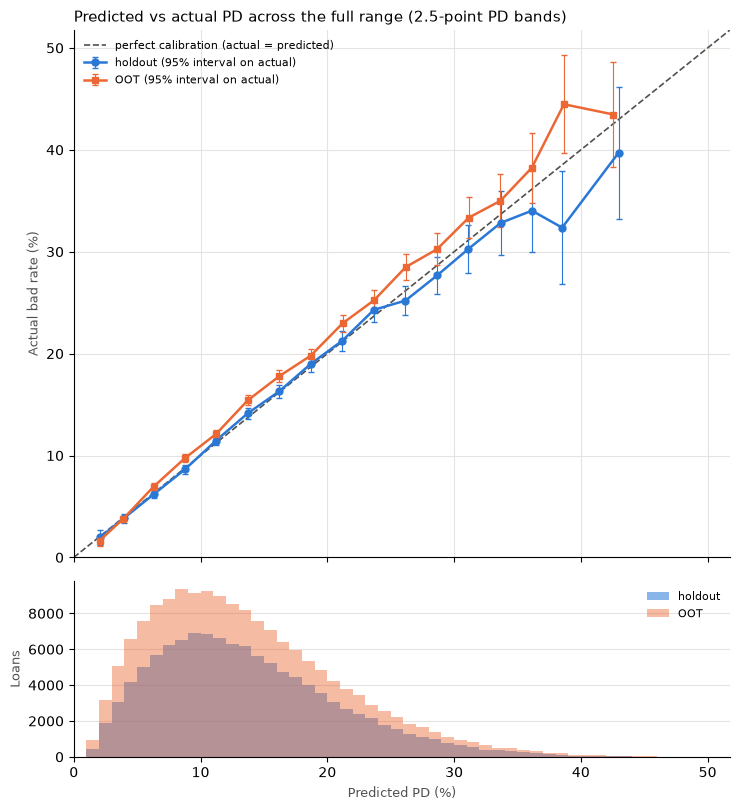

In [77]:
# ---------------------------------------------------------------
# 15d  Full PD range: actual vs predicted in 2.5-point PD bands (deciles hide the tail)
# ---------------------------------------------------------------
# The top decile spans predicted PD ~24% to ~53% and averages 28.7%, so the decile chart stops near 30%.
# Fixed-width 2.5-point bands show the whole range; bands above 40% are merged (few loans).
band_edges = np.r_[np.arange(0, 0.40 + 1e-9, 0.025), 1.0]
band_labels = [f'{100*a:.1f}-{100*b:.1f}' if b < 1 else f'{100*a:.0f}+' for a, b in zip(band_edges[:-1], band_edges[1:])]

def band_table(p, y):
    b = pd.cut(p, band_edges, labels=band_labels, right=False)
    g = pd.DataFrame({'band': b, 'p': p.values, 'y': y.values}).groupby('band', observed=True).agg(
        n=('y', 'size'), predicted=('p', 'mean'), actual=('y', 'mean'))
    g['actual / predicted'] = g['actual'] / g['predicted']
    se = np.sqrt(g['actual'] * (1 - g['actual']) / g['n'])
    g['actual 95% lo'], g['actual 95% hi'] = g['actual'] - 1.96 * se, g['actual'] + 1.96 * se
    return g

bands_15 = {name: band_table(p, y) for name, p, y in [('holdout', pd_ho, y_ho), ('OOT', pd_oo, y_oo)]}
for name, g in bands_15.items():
    print(f'{name}: actual vs predicted by 2.5-point PD band')
    display(g[['n', 'predicted', 'actual', 'actual / predicted']].style.format(
        {'n': '{:,}', 'predicted': '{:.1%}', 'actual': '{:.1%}', 'actual / predicted': '{:.2f}'}))

fig, (ax, axh) = plt.subplots(2, 1, figsize=(7.5, 8.2), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
lim = 100 * max(max(g['actual 95% hi'].max(), g['predicted'].max()) for g in bands_15.values()) * 1.05
ax.plot([0, lim], [0, lim], '--', color='#52514e', lw=1.2, label='perfect calibration (actual = predicted)')
for (name, g), c, m in zip(bands_15.items(), ['#2a78d6', '#eb6834'], ['o', 's']):
    ax.errorbar(100 * g['predicted'], 100 * g['actual'],
                yerr=[100 * (g['actual'] - g['actual 95% lo']), 100 * (g['actual 95% hi'] - g['actual'])],
                fmt=m + '-', color=c, lw=1.8, ms=5, capsize=2, elinewidth=0.8, label=f'{name} (95% interval on actual)')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_ylabel('Actual bad rate (%)', fontsize=9, color='#52514e')
ax.set_title('Predicted vs actual PD across the full range (2.5-point PD bands)', loc='left', fontsize=11)
ax.legend(fontsize=8, frameon=False, loc='upper left'); ax.grid(color='#e4e3df', lw=0.8); ax.set_axisbelow(True)
# Lower panel: how many loans sit at each predicted PD
axh.hist(100 * pd_ho, bins=np.arange(0, lim + 1, 1), color='#2a78d6', alpha=0.55, label='holdout')
axh.hist(100 * pd_oo, bins=np.arange(0, lim + 1, 1), color='#eb6834', alpha=0.45, label='OOT')
axh.set_xlabel('Predicted PD (%)', fontsize=9, color='#52514e'); axh.set_ylabel('Loans', fontsize=9, color='#52514e')
axh.legend(fontsize=8, frameon=False); axh.grid(axis='y', color='#e4e3df', lw=0.8); axh.set_axisbelow(True)
for a in (ax, axh):
    for s in ['top', 'right']: a.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig('figures/step15_pd_bands_full_range.png', dpi=130, facecolor='#fcfcfb'); plt.show()

## 15.1 Takeaways - scaling & calibration (done)

**Scaling (600 points at 50:1 good:bad, PDO 20).** Each attribute gets a 60-point intercept share; bin points range from 47 to 79. Train scores run 484-620 (median 543).

| Attribute | Points range | Spread |
|---|---|---|
| `fico_range_low` | 53-79 | 26 |
| `dti_after_loan` | 47-70 | 23 |
| `share_opened_24m` | 49-70 | 21 |
| `bc_open_to_buy` | 54-72 | 18 |
| `tot_hi_cred_lim` | 55-70 | 15 |
| `mths_since_recent_bc` | 56-68 | 12 |
| `purpose` | 53-65 | 12 |
| `inq_last_6mths` | 52-63 | 11 |
| `loan_to_income` | 54-64 | 10 |

- **Rounding to whole points costs almost nothing:** AUC 66.65 vs 66.68 unrounded (holdout) and 67.47 vs 67.50 (OOT); KS 23.95 vs 24.18 and 25.23 vs 25.31.
- **The odds-to-score relationship holds:** actual PDO is 21.9 points on holdout and 20.6 on OOT, against the target 20. Actual ln-odds track the scaling line across 500-600.

**Calibration (predicted vs actual bad rate).**

| Sample | Actual | Predicted | Actual / predicted | Cal. intercept a | Cal. slope b |
|---|---|---|---|---|---|
| Train | 13.79% | 13.79% | 1.000 | 0.000 | 1.000 |
| Holdout | 13.79% | 13.77% | 1.002 | -0.023 | 0.985 |
| OOT (Jul-Dec 2015) | 14.74% | 13.60% | **1.083** | 0.117 | 1.011 |

(a and b are fitted together: logit P(bad) = a + b * logit(predicted PD).)

- **Holdout is well calibrated:** all 10 deciles within +/-10%; 8 of 10 inside their 95% binomial interval.
- **OOT is under-predicted by 8.3% overall**, inside the +/-10% overall tolerance, but deciles 5, 7, 8 and 9 run 11-12% above prediction.
- **The OOT miss is a level shift, not a shape problem:** slope b = 1.01, and ranking holds (deciles fall steadily). The later vintage is riskier (14.7% vs 13.8% bad), and the model's average PD hasn't moved with it.
- **Fix, if needed:** an intercept-only shift of **+0.098** on the log-odds (fitted with b fixed at 1) brings OOT predicted to 14.74%, matching actual; in score terms, about -2.8 points for everyone. Platt scaling is unnecessary, since the slope is already close to 1.

**Decision:** keep `model_12` and the scaling as they are. Recalibrating on OOT would leave no later data to validate it; record the +0.098 intercept shift as the candidate adjustment and re-test it on the 2016-2017 vintages in Step 23 (monitoring). The scorecard table is `scorecard_15`; scores are `S_tr` / `S_ho` / `S_oo`.

# Step 16 — Performance: AUC, KS, rank-ordering vs `sub_grade`

The integer score from Step 15 (`S_tr` / `S_ho` / `S_oo`; higher = safer) is compared with the champion, LendingClub's `sub_grade` (A1 = safest … G5 = riskiest), and with FICO alone, on the same loans.

| Check | What it answers |
|---|---|
| AUC and KS (train / holdout / OOT) | How well each score separates bads from goods. AUC: probability a random bad scores worse than a random good (50 = random). KS: largest gap between the cumulative bad and good distributions |
| Δ AUC and Δ KS with 95% bootstrap intervals | Is the difference from the champion real or sampling noise? (paired resampling of loans, 200 draws) |
| Bad rate by score decile | Does risk fall steadily from the worst decile to the best, with no reversals? |
| Capture of bads (riskiest 10%, 20%, 30% …) | Share of all bads caught if that share of applicants were declined, the practical view of discrimination |
| ROC and KS charts | ROC curves for scorecard, `sub_grade` and FICO; cumulative bad / good curves by score with the KS point marked |

In [96]:
# ---------------------------------------------------------------
# 16a  AUC / KS: scorecard vs sub_grade, with bootstrap intervals for the differences
# ---------------------------------------------------------------
samples = {'train': (S_tr, y_tr, train), 'holdout': (S_ho, y_ho, hold), 'OOT': (S_oo, y_oo, oot)}

rows = []
for name, (S, y, d) in samples.items():
    for model_name, risk in [('Scorecard (9 attributes)', -S), ('LC sub_grade', sg(d)), ('FICO alone', -d.fico_range_low)]:
        rows.append({'sample': name, 'model': model_name, 'AUC': auc_pts(y, risk), 'KS': ks_pts(y, risk)})
perf = pd.DataFrame(rows).set_index(['sample', 'model'])
display(perf.round(1))

# Paired bootstrap of the AUC and KS differences (scorecard minus sub_grade) on holdout and OOT
rng_bs = np.random.default_rng(16)
ci = []
for name in ['holdout', 'OOT']:
    S, y, d = samples[name]
    y_, a_, b_ = y.values, (-S).values, sg(d).values
    d_auc, d_ks = [], []
    for _ in range(200):
        i = rng_bs.integers(0, len(y_), len(y_))
        (aa, ka), (ab, kb) = auc_ks(y_[i], a_[i]), auc_ks(y_[i], b_[i])
        d_auc.append(100 * (aa - ab)); d_ks.append(100 * (ka - kb))
    sc, sgr = perf.loc[(name, 'Scorecard (9 attributes)')], perf.loc[(name, 'LC sub_grade')]
    for metric, draws in [('AUC', d_auc), ('KS', d_ks)]:
        ci.append({'sample': name, 'metric': metric, 'Δ (scorecard − sub_grade)': sc[metric] - sgr[metric],
                   '95% low': np.percentile(draws, 2.5), '95% high': np.percentile(draws, 97.5)})
print('Difference vs champion, 95% bootstrap interval (points):')
display(pd.DataFrame(ci).set_index(['sample', 'metric']).round(2))

AUC    KS
sample  model                               
train   Scorecard (9 attributes)  66.9  24.1
        LC sub_grade              66.3  24.1
        FICO alone                59.7  14.6
holdout Scorecard (9 attributes)  66.6  23.9
        LC sub_grade              66.0  23.5
        FICO alone                59.8  14.8
OOT     Scorecard (9 attributes)  67.5  25.2
        LC sub_grade              68.1  26.6
        FICO alone                60.4  15.5

Difference vs champion, 95% bootstrap interval (points):


Δ (scorecard − sub_grade)  95% low  95% high
sample  metric                                              
holdout AUC                          0.60     0.23      1.04
        KS                           0.42    -0.27      1.37
OOT     AUC                         -0.67    -1.06     -0.35
        KS                          -1.39    -2.13     -0.76

In [97]:
# ---------------------------------------------------------------
# 16b  Rank-ordering by score decile (cut points from train scores) and capture of bads
# ---------------------------------------------------------------
edges = np.unique(np.quantile(S_tr, np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
dec_labels = [f'D{i}' for i in range(1, len(edges))]          # D1 = lowest score (riskiest)

rank = {}
for name, (S, y, d) in samples.items():
    dec = pd.cut(S, edges, labels=dec_labels, right=False)
    g = pd.DataFrame({'dec': dec, 'bad': y.values}).groupby('dec', observed=True).bad.agg(['size', 'mean'])
    rank[(name, 'bad rate %')] = (100 * g['mean']).round(1)
    rank[(name, '% of loans')] = (100 * g['size'] / g['size'].sum()).round(1)
rank = pd.DataFrame(rank)
rank.index = [f'{l} ({int(edges[i]) if np.isfinite(edges[i]) else "min"}–{int(edges[i+1]) - 1 if np.isfinite(edges[i+1]) else "max"})'
              for i, l in enumerate(dec_labels)]
print('Bad rate by score decile (D1 = riskiest):'); display(rank)
for name in samples:
    br = rank[(name, 'bad rate %')].values
    print(f'{name}: reversals = {int((np.diff(br) > 0).sum())}, worst/best decile ratio = {br[0] / br[-1]:.1f}x')

# Capture: share of all bads in the riskiest X% of applicants (sub_grade ties broken at random)
def capture(y, risk, fracs=(0.1, 0.2, 0.3, 0.5)):
    order = np.lexsort((rng_bs.random(len(risk)), -np.asarray(risk)))   # riskiest first; random tie-break
    cum = np.cumsum(np.asarray(y)[order]) / np.sum(y)
    return {f'worst {int(f*100)}%': 100 * cum[int(f * len(cum)) - 1] for f in fracs}
cap = pd.DataFrame({(name, m): capture(y, r) for name, (S, y, d) in samples.items() if name != 'train'
                    for m, r in [('Scorecard', -S), ('sub_grade', sg(d))]}).T
print('Share of all bads captured in the riskiest X% of applicants (%):'); display(cap.round(1))

Bad rate by score decile (D1 = riskiest):


train               holdout                   OOT           
              bad rate % % of loans bad rate % % of loans bad rate % % of loans
D1 (min–520)        28.0        9.9       27.8        9.8       30.6       10.1
D2 (521–527)        22.1        9.7       21.8        9.5       23.1        9.4
D3 (528–532)        18.1        9.0       18.4        9.2       19.9        8.8
D4 (533–537)        15.9       10.2       16.1       10.2       17.3        9.7
D5 (538–542)        13.8       10.6       14.1       10.7       15.4       10.3
D6 (543–547)        12.2       10.3       12.3       10.3       12.4        9.9
D7 (548–552)        10.4        9.3        9.9        9.5       11.5        9.0
D8 (553–559)         8.3       10.8        8.5       10.6        9.3       10.6
D9 (560–568)         6.6        9.4        6.2        9.3        7.3        9.9
D10 (569–max)        3.7       10.7        4.2       10.8        4.0       12.3

train: reversals = 0, worst/best decile ratio = 7.6x
holdout: reversals = 0, worst/best decile ratio = 6.6x
OOT: reversals = 0, worst/best decile ratio = 7.7x
Share of all bads captured in the riskiest X% of applicants (%):


worst 10%  worst 20%  worst 30%  worst 50%
holdout Scorecard       20.2       35.8       49.1       70.6
        sub_grade       18.9       35.0       48.0       70.1
OOT     Scorecard       20.8       36.5       49.6       71.4
        sub_grade       20.7       36.2       50.3       72.4

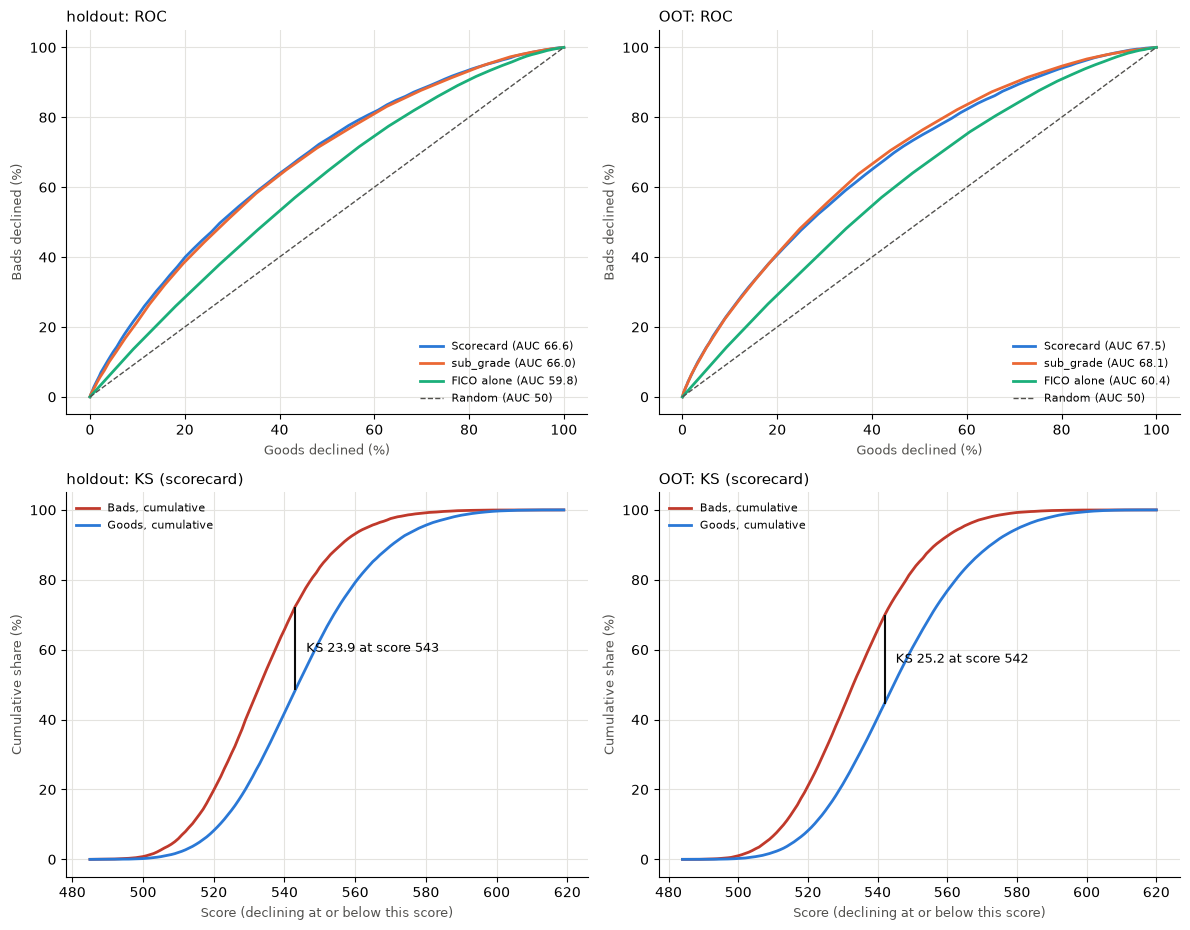

In [98]:
# ---------------------------------------------------------------
# 16c  ROC curves (AUC) and KS curves: holdout and OOT
# ---------------------------------------------------------------
from sklearn.metrics import roc_curve

def thin(x, y, n=400):
    k = np.linspace(0, len(x) - 1, min(n, len(x))).astype(int)
    return x[k], y[k]

fig, axes = plt.subplots(2, 2, figsize=(12, 9.4))
for j, name in enumerate(['holdout', 'OOT']):
    S, y, d = samples[name]

    # Top row: ROC. AUC = area under the curve; KS = largest vertical gap to the diagonal
    ax = axes[0, j]
    for label, key, risk, c in [('Scorecard', 'Scorecard (9 attributes)', -S, '#2a78d6'),
                                ('sub_grade', 'LC sub_grade', sg(d), '#eb6834'),
                                ('FICO alone', 'FICO alone', -d.fico_range_low, '#1baf7a')]:
        fpr, tpr, _ = roc_curve(y, risk)
        a = perf.loc[(name, key), 'AUC']
        ax.plot(*thin(fpr * 100, tpr * 100), color=c, lw=2, label=f'{label} (AUC {a:.1f})')
    ax.plot([0, 100], [0, 100], color='#52514e', lw=1, ls='--', label='Random (AUC 50)')
    ax.set_title(f'{name}: ROC', loc='left', fontsize=11)
    ax.set_xlabel('Goods declined (%)', fontsize=9, color='#52514e')
    ax.set_ylabel('Bads declined (%)', fontsize=9, color='#52514e')
    ax.legend(fontsize=8, frameon=False, loc='lower right')

    # Bottom row: KS. Cumulative share of bads and goods at or below each score; KS = maximum gap
    ax = axes[1, j]
    grid = np.arange(S.min(), S.max() + 1)
    s_b, s_g = np.sort(S[y.values == 1].values), np.sort(S[y.values == 0].values)
    cb = np.searchsorted(s_b, grid, side='right') / len(s_b) * 100
    cg = np.searchsorted(s_g, grid, side='right') / len(s_g) * 100
    k = np.argmax(cb - cg)
    ax.plot(grid, cb, color='#c0392b', lw=2, label='Bads, cumulative')
    ax.plot(grid, cg, color='#2a78d6', lw=2, label='Goods, cumulative')
    ax.vlines(grid[k], cg[k], cb[k], color='#0b0b0b', lw=1.5)
    ax.annotate(f"KS {cb[k] - cg[k]:.1f} at score {grid[k]}", (grid[k], (cb[k] + cg[k]) / 2),
                xytext=(8, 0), textcoords='offset points', fontsize=9, va='center')
    ax.set_title(f'{name}: KS (scorecard)', loc='left', fontsize=11)
    ax.set_xlabel('Score (declining at or below this score)', fontsize=9, color='#52514e')
    ax.set_ylabel('Cumulative share (%)', fontsize=9, color='#52514e')
    ax.legend(fontsize=8, frameon=False, loc='upper left')

for ax in axes.ravel():
    ax.grid(color='#e4e3df', lw=0.8); ax.set_axisbelow(True)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig('figures/step16_roc_ks.png', dpi=130, facecolor='#fcfcfb'); plt.show()

## 16.1 Takeaways — performance ✅

| Sample | Scorecard AUC | `sub_grade` AUC | Δ AUC (95% interval) | Scorecard KS | `sub_grade` KS | Δ KS (95% interval) |
|---|---|---|---|---|---|---|
| Train | 66.9 | 66.3 | — | 24.1 | 24.1 | — |
| Holdout | 66.6 | 66.0 | **+0.6** (+0.2 to +1.0) | 23.9 | 23.5 | +0.4 (−0.3 to +1.4) |
| OOT (Jul–Dec 2015) | 67.5 | 68.1 | **−0.7** (−1.1 to −0.4) | 25.2 | 26.6 | **−1.4** (−2.1 to −0.8) |

FICO alone: AUC 59.7 / 59.8 / 60.4, KS 14.6 / 14.8 / 15.5 (train / holdout / OOT).

- **On AUC the scorecard beats the champion on holdout and loses to it on OOT, and both differences are statistically real:** neither interval includes zero. On KS the holdout edge is within noise; the OOT shortfall is real.
- **The swing comes from `sub_grade`, not the scorecard.** From holdout to OOT the scorecard's AUC rises 0.9 points and KS 1.3; `sub_grade` rises 2.1 and 3.1. A plausible reason is that LendingClub's underwriting and grading in late 2015 used information or model updates this scorecard can't see (fuller bureau data, verification, internal history). That's a hypothesis; the data doesn't show it directly.
- **The KS point sits at a score of about 542–543** on both holdout and OOT, near the median score.
- **Rank-ordering is clean:** no reversals across the 10 score deciles on train, holdout or OOT. The riskiest decile defaults at 28–31% and the safest at about 4%, a 6.6–7.7× spread.
- **In practical terms the two are close.** Declining the riskiest 20% of applicants catches 35.8% of bads with the scorecard vs 35.0% with `sub_grade` (holdout), and 36.5% vs 36.2% (OOT). At 30–50% the champion edges ahead on OOT by about 1 point.
- **Train vs holdout is stable** (AUC 66.9 vs 66.6, KS 24.1 vs 23.9), so there's no sign of overfitting.

**Verdict:** a 9-attribute, fully explainable scorecard built on public data roughly matches LendingClub's own grade: ahead on the development period, behind on the most recent one. The OOT gap and the 8% OOT under-prediction (Step 15) both point to a later vintage that moved. Steps 18 (stability) and 23 (monitoring) follow up on that.

# Step 17 — Summary of model attributes

One table for the 9 final attributes, in stepwise order, pulling together results from Steps 11 (IV, bins, direction), 12 (entry gain), 14 (coefficient, VIF) and 15 (points). No new estimation.

In [104]:
# ---------------------------------------------------------------
# 17  Final model attributes: one summary table
# ---------------------------------------------------------------
descr = {
    'fico_range_low':       'Lower bound of FICO range at application',
    'share_opened_24m':     'Accounts opened in last 24 months / total accounts ever',
    'dti_after_loan':       'DTI plus the new loan payment (12% reference APR, 36 months) as % of monthly income',
    'tot_hi_cred_lim':      'Total high credit / credit limit across all accounts',
    'inq_last_6mths':       'Credit inquiries in the last 6 months',
    'purpose':              'Stated loan purpose',
    'bc_open_to_buy':       'Unused bankcard limit (total open-to-buy)',
    'mths_since_recent_bc': 'Months since most recent bankcard was opened',
    'loan_to_income':       'Loan amount / annual income',
}
entry = path_B.set_index('attribute')
summary_17 = pd.DataFrame({
    'type':          iv_tbl.loc[sel_12, 'type'],
    'description':   pd.Series(descr),
    'step entered':  entry.loc[sel_12].index.map(lambda v: int(path_B.index[path_B.attribute == v][0])),
    'ΔR² at entry':  entry.loc[sel_12, 'ΔR²'],
    'IV train':      iv_tbl.loc[sel_12, 'IV train'],
    'IV holdout':    iv_tbl.loc[sel_12, 'IV holdout'],
    'IV OOT':        iv_tbl.loc[sel_12, 'IV OOT'],
    'bins':          iv_tbl.loc[sel_12, 'n_bins'],
    'direction':     iv_tbl.loc[sel_12, 'trend'],
    'coef':          model_12.params[sel_12],
    'VIF':           vif_14.loc[sel_12, 'VIF train'],
    'points min':    rng.loc[sel_12, 'min'],
    'points max':    rng.loc[sel_12, 'max'],
    'points range':  rng.loc[sel_12, 'range'],
}).rename_axis('attribute')
display(summary_17.style.format({'ΔR² at entry': '{:.4f}', 'IV train': '{:.3f}', 'IV holdout': '{:.3f}', 'IV OOT': '{:.3f}',
                                 'coef': '{:.3f}', 'VIF': '{:.2f}'}))
print(f"Raw {(summary_17.type == 'raw').sum()} | derived {(summary_17.type == 'derived').sum()} | "
      f"total points range {rng.loc[sel_12, 'min'].sum()}–{rng.loc[sel_12, 'max'].sum()}")

,type,description,step entered,ΔR² at entry,IV train,IV holdout,IV OOT,bins,direction,coef,VIF,points min,points max,points range
attribute,,,,,,,,,,,,,,
fico_range_low,raw,Lower bound of FICO range at application,1,0.0192,0.138,0.145,0.159,13,safer as value rises,-0.602,1.48,53,79,26
share_opened_24m,derived,Accounts opened in last 24 months / total accounts ever,2,0.0119,0.108,0.111,0.139,15,riskier as value rises,-0.651,1.24,49,70,21
dti_after_loan,derived,"DTI plus the new loan payment (12% reference APR, 36 months) as % of monthly income",3,0.0114,0.076,0.078,0.078,13,riskier as value rises,-0.819,1.54,47,70,23
tot_hi_cred_lim,raw,Total high credit / credit limit across all accounts,4,0.0035,0.084,0.068,0.073,12,safer as value rises,-0.490,1.20,55,70,15
inq_last_6mths,raw,Credit inquiries in the last 6 months,5,0.0027,0.032,0.032,0.062,4,riskier as value rises,-0.769,1.06,52,63,11
purpose,raw,Stated loan purpose,6,0.0021,0.021,0.016,0.021,4,categorical,-0.869,1.02,53,65,12
bc_open_to_buy,raw,Unused bankcard limit (total open-to-buy),7,0.0010,0.082,0.080,0.082,13,safer as value rises,-0.523,1.57,54,72,18
mths_since_recent_bc,raw,Months since most recent bankcard was opened,8,0.0012,0.034,0.035,0.049,11,safer as value rises,-0.571,1.28,56,68,12
loan_to_income,derived,Loan amount / annual income,9,0.0010,0.042,0.035,0.033,11,riskier as value rises,-0.514,1.62,54,64,10


Raw 6 | derived 3 | total points range 473–621


## 17.1 Takeaways — model attributes ✅

| # | Attribute | Type | What it measures | IV train / holdout / OOT | Direction | Points range |
|---|---|---|---|---|---|---|
| 1 | `fico_range_low` | raw | FICO at application | 0.138 / 0.145 / 0.159 | safer as it rises | 53–79 (26) |
| 2 | `share_opened_24m` | derived | Accounts opened in 24 months / all accounts | 0.108 / 0.111 / 0.139 | riskier as it rises | 49–70 (21) |
| 3 | `dti_after_loan` | derived | DTI including the new loan's payment | 0.076 / 0.078 / 0.078 | riskier | 47–70 (23) |
| 4 | `tot_hi_cred_lim` | raw | Total credit limits, all accounts | 0.084 / 0.068 / 0.073 | safer | 55–70 (15) |
| 5 | `inq_last_6mths` | raw | Inquiries, last 6 months | 0.032 / 0.032 / 0.062 | riskier | 52–63 (11) |
| 6 | `purpose` | raw | Stated loan purpose | 0.021 / 0.016 / 0.021 | categorical | 53–65 (12) |
| 7 | `bc_open_to_buy` | raw | Unused bankcard limit | 0.082 / 0.080 / 0.082 | safer | 54–72 (18) |
| 8 | `mths_since_recent_bc` | raw | Months since newest bankcard | 0.034 / 0.035 / 0.049 | safer | 56–68 (12) |
| 9 | `loan_to_income` | derived | Loan amount / income | 0.042 / 0.035 / 0.033 | riskier | 54–64 (10) |

- **Balanced, explainable mix:** credit standing (FICO), credit-seeking (`share_opened_24m`, `inq_last_6mths`, `mths_since_recent_bc`), capacity (`tot_hi_cred_lim`, `bc_open_to_buy`), affordability (`dti_after_loan`, `loan_to_income`) and loan use (`purpose`). 6 raw, 3 derived.
- **All directions make business sense** and every numeric attribute is monotonic, which keeps reason codes coherent (Step 20).
- **Weight is spread out:** the largest points range is FICO (26), then `dti_after_loan` (23) and `share_opened_24m` (21). No single attribute dominates.
- **Entry order is not IV order.** `inq_last_6mths` and `purpose` have low stand-alone IV but entered 5th and 6th because they add information the first four don't carry. `bc_open_to_buy` has a higher IV (0.082) but entered 7th because it overlaps FICO (r = 0.53, Step 14).
- **Stable out of sample:** holdout IVs match train within about 0.015. On OOT the credit-seeking attributes get stronger (`share_opened_24m` 0.108 → 0.139, `inq_last_6mths` 0.032 → 0.062), consistent with the higher OOT AUC.

The table is `summary_17`.

# Step 18 — Out-of-sample and out-of-time validation (summary) ✅

Brought together from Steps 15–17; no new modeling.

| Check | Holdout (same period, random 30%) | OOT (Jul–Dec 2015) |
|---|---|---|
| What it tests | Overfitting | Drift over time |
| Ranking (AUC / KS) | 66.6 / 23.9 vs train 66.9 / 24.1: no overfitting | 67.5 / 25.2, no decile reversals: ranking holds |
| Score PSI vs train (train-score deciles) | 0.0002 | 0.003: no population shift |
| Attribute PSI vs train (Step 11 bins) | — | All 9 below 0.03 (largest `inq_last_6mths` 0.021, `mths_since_recent_bc` 0.019) |
| Calibration (actual / predicted) | 1.002 | 1.083: under-predicted, a level shift (slope 1.01) |

- **Holdout:** performance and calibration match train, so the model generalizes within the development period.
- **OOT:** the applicant mix is stable (no population drift) and ranking holds, but the later vintage defaults about 8% more than predicted at the same scores. That is calibration drift, not a ranking or population problem. The response is the candidate intercept shift from Step 15 (+0.098), to be re-tested on the 2016–2017 vintages (Step 23), not a rebuild.

# Step 19 — Fair lending (description only) ⏭️

Not testable here: the public data has no race, ethnicity, sex or age fields. What a lender would do:

- **Disparate treatment:** no prohibited-basis inputs. `addr_state` was already removed in Step 10 as a compliance filter, and each of the 9 attributes would get a legal / compliance review for proxy risk.
- **Disparate impact:** estimate protected-class membership with a proxy method (e.g. BISG, which combines surname and geography), then compute the **Adverse Impact Ratio** at the strategy cutoff: approval rate of the protected group ÷ approval rate of the control group. A ratio below about 0.80 is the usual flag.
- **Less discriminatory alternatives:** if a flag appears, test model variants (drop or re-bin attributes) and compare the AIR gain against the loss in AUC / KS; adopt an alternative that meets the business need with less impact.
- Typically run by, or reviewed with, an independent fair-lending firm and documented in the model file.

# Step 20 — Adverse action reason codes (description + worked example) ✅

A declined applicant must be told the principal reasons for the decision (ECOA / Regulation B). The reasons must describe factors the scorecard actually uses, and the Regulation B commentary notes that more than four reasons is unlikely to help the applicant, so four is standard. Regulation B allows several selection methods; the most common for a points scorecard is **points lost**:

1. For each attribute, points lost = the attribute's maximum points − the applicant's points.
2. Rank attributes by points lost; the top four become the reasons.
3. Map each attribute to a plain-English reason statement.
4. Rules: ties are broken by a fixed priority (e.g. IV, or stepwise entry order); attributes with 0 points lost never produce a reason; Missing / Special bins need a pre-agreed reason (e.g. "insufficient credit file") or are suppressed.

**Worked example: an OOT applicant scoring 513** (below the KS-point cutoff of 543, so declined; the loan later went bad):

| Attribute | Applicant value | Points | Max | Points lost | Rank | Reason statement |
|---|---|---|---|---|---|---|
| `fico_range_low` | 660 | 53 | 79 | **26** | 1 | Credit score too low |
| `share_opened_24m` | 0.50 | 49 | 70 | **21** | 2 | Too many accounts opened recently |
| `tot_hi_cred_lim` | 13,419 | 55 | 70 | **15** | 3 | Insufficient total credit limits |
| `bc_open_to_buy` | 3,990 | 60 | 72 | **12** | 4 (tie, wins on IV and entry order) | Insufficient available credit on bank cards |
| `mths_since_recent_bc` | 3 | 56 | 68 | 12 | 5 | — |
| `inq_last_6mths` | 3 | 52 | 63 | 11 | 6 | — |
| `purpose` | debt consolidation | 59 | 65 | 6 | 7 | — |
| `dti_after_loan` | 16.8% | 67 | 70 | 3 | 8 | — |
| `loan_to_income` | 0.15 | 62 | 64 | 2 | 9 | — |

The applicant's notice lists the top four. Their affordability was fine (DTI after the loan about 17%); the decline was driven by a low FICO, a thin and newly built file, and limited available credit. The reasons explain exactly that.

When a bureau score is used in the decision, FCRA adds a separate disclosure: the score itself and up to four key factors that hurt it (five if inquiries is one of them).

# Step 23 — Monitoring simulation on 2016–2018 loans

The frozen scorecard (Step 15 bins, coefficients and points) is applied to 36-month loans issued 2016–2018, treated as "post-launch" quarters.

| Metric | Benchmark | Needs outcomes? | Thresholds (industry convention) |
|---|---|---|---|
| Score PSI | Train score deciles | No | < 0.10 green, 0.10–0.25 yellow, ≥ 0.25 red |
| Attribute PSI (CSI) | Train distribution over each attribute's Step 11 bins | No | same |
| Calibration (actual / predicted) | Model PD | Yes | ±10% |

Caveats: these are booked loans, not all applicants, so LendingClub's own credit-policy changes show up as shifts. 2017–2018 loans are largely unresolved (still Current), so outcome checks use 2016 only, shown as a range: **upper** = Current loans excluded (only resolved loans, which over-weights early charge-offs), **lower** = Current loans counted as good.

In [116]:
# ---------------------------------------------------------------
# 23  Monitoring simulation: score PSI, attribute PSI (CSI), 2016 calibration
# ---------------------------------------------------------------
def psi(e, a, floor=1e-4):
    e, a = np.clip(np.asarray(e, float), floor, None), np.clip(np.asarray(a, float), floor, None)
    return float(((a - e) * np.log(a / e)).sum())

def light(v, y=0.10, r=0.25):
    return 'red' if v >= r else 'yellow' if v >= y else 'green'

# Post-launch population: same exclusions as the modeling frame, 36-month loans, 2016-2018
mon = dm[dm.issue_dt.dt.year.between(2016, 2018) & (dm.term_m == 36)].copy()
mon['qtr'] = mon.issue_dt.dt.year.astype(str) + 'Q' + mon.issue_dt.dt.quarter.astype(str)
W_mon = woe_frame(mon, sel_12)
S_mon = score_points(W_mon[sel_12])
pd_mon = model_12.predict(sm.add_constant(W_mon[sel_12], has_constant='add'))

# Score PSI by quarter, on train-score decile edges (frozen)
edges = np.unique(np.quantile(S_tr, np.linspace(0, 1, 11)[1:-1]))
dist = lambda S: np.bincount(np.searchsorted(edges, S, side='right'), minlength=len(edges) + 1) / len(S)
e_score = dist(S_tr)
ref = {'holdout': S_ho, 'OOT (2015H2)': S_oo}
psi_rows = [{'period': k, 'loans': len(S), 'mean score': S.mean(), 'score PSI': psi(e_score, dist(S))} for k, S in ref.items()]
for q, idx in mon.groupby('qtr').groups.items():
    S = S_mon.loc[idx]
    psi_rows.append({'period': q, 'loans': len(S), 'mean score': S.mean(), 'score PSI': psi(e_score, dist(S))})
psi_tbl = pd.DataFrame(psi_rows).set_index('period')
psi_tbl['status'] = psi_tbl['score PSI'].map(light)
print('Score PSI vs train:'); display(psi_tbl.style.format({'loans': '{:,}', 'mean score': '{:.1f}', 'score PSI': '{:.3f}'}))

# Attribute PSI (CSI) by year, on the Step 11 bins (frozen)
def bin_share(d, v):
    return pd.Series(bp.get_binned_variable(v).transform(d[v].values, metric='bins')).value_counts(normalize=True)
csi = {}
for v in sel_12:
    e = bin_share(train, v)
    for name, d in [('OOT (2015H2)', oot)] + [(str(y), mon[mon.issue_dt.dt.year == y]) for y in (2016, 2017, 2018)]:
        a = bin_share(d, v); idx = e.index.union(a.index)
        csi[(v, name)] = psi(e.reindex(idx, fill_value=0), a.reindex(idx, fill_value=0))
csi_tbl = pd.Series(csi).unstack()[['OOT (2015H2)', '2016', '2017', '2018']].loc[sel_12]
print('Attribute PSI (CSI) vs train:')
display(csi_tbl.style.format('{:.3f}').map(lambda v: {'green': '', 'yellow': 'background-color:#fff3b0',
                                                      'red': 'background-color:#f4b6b6'}[light(v)]))

# 2016 outcomes: calibration range and ranking (lifetime target; ~27% of 2016 loans still Current)
m16 = mon[mon.issue_dt.dt.year == 2016].copy()
m16['pd'] = pd_mon.loc[m16.index]
m16['pd_shift'] = 1 / (1 + np.exp(-(np.log(m16.pd / (1 - m16.pd)) + 0.098)))      # candidate intercept shift from Step 15
m16['half'] = '2016H' + ((m16.issue_dt.dt.month > 6) + 1).astype(str)
cur = m16.loan_status.eq('Current')
cal_rows = []
for h, g in m16.groupby('half'):
    res = g[g.bad.notna()]                                   # resolved: Fully Paid / Charged Off / Late 31-120
    cur_g = g[g.loan_status.eq('Current')]
    lo_bad = res.bad.sum() / (len(res) + len(cur_g))          # Current counted as good
    cal_rows.append({'period': h, 'loans': len(g), '% still Current': 100 * len(cur_g) / len(g),
                     'predicted PD %': 100 * g.pd.mean(), 'predicted + shift %': 100 * g.pd_shift.mean(),
                     'actual % (lower: Current = good)': 100 * lo_bad, 'actual % (upper: resolved only)': 100 * res.bad.mean(),
                     'A/P lower': lo_bad / g.pd.mean(), 'A/P upper': res.bad.mean() / res.pd.mean(),
                     'AUC (resolved)': auc_pts(res.bad, res.pd), 'KS (resolved)': ks_pts(res.bad, res.pd)})
cal_23 = pd.DataFrame(cal_rows).set_index('period')
print('2016 calibration (actual / predicted) and ranking:')
display(cal_23.round(2))

Score PSI vs train:


,loans,mean score,score PSI,status
period,,,,
holdout,"114,576",544.0,0.000,green
OOT (2015H2),"161,213",544.8,0.003,green
2016Q1,"93,934",544.8,0.005,green
2016Q2,"73,167",544.6,0.002,green
2016Q3,"73,113",543.9,0.002,green
2016Q4,"75,970",545.2,0.005,green
2017Q1,"69,350",546.8,0.020,green
2017Q2,"72,997",546.9,0.023,green
2017Q3,"80,101",546.8,0.021,green


Attribute PSI (CSI) vs train:


,OOT (2015H2),2016,2017,2018
fico_range_low,0.004,0.006,0.042,0.124
share_opened_24m,0.011,0.037,0.047,0.060
dti_after_loan,0.006,0.003,0.008,0.016
tot_hi_cred_lim,0.006,0.009,0.010,0.014
inq_last_6mths,0.021,0.024,0.044,0.086
purpose,0.005,0.025,0.046,0.036
bc_open_to_buy,0.016,0.035,0.099,0.230
mths_since_recent_bc,0.019,0.020,0.010,0.013
loan_to_income,0.005,0.020,0.065,0.037


2016 calibration (actual / predicted) and ranking:


,loans,% still Current,predicted PD %,predicted + shift %,actual % (lower: Current = good),actual % (upper: resolved only),A/P lower,A/P upper,AUC (resolved),KS (resolved)
period,,,,,,,,,,
2016H1,167101,16.86,13.61,14.75,15.76,18.97,1.16,1.39,67.91,25.88
2016H2,149083,37.75,13.54,14.68,14.60,23.56,1.08,1.71,66.19,23.31


## 23.1 Takeaways — monitoring simulation ✅

**Score PSI (vs train deciles): green in every quarter, but trending up.**

| Period | 2015H2 (OOT) | 2016 Q1–Q4 | 2017 Q1–Q3 | 2017Q4 | 2018 Q1–Q4 |
|---|---|---|---|---|---|
| Score PSI | 0.003 | 0.002–0.005 | 0.020–0.023 | 0.058 | 0.061–0.096 |
| Mean score | 544.8 | 543.9–545.2 | 546.8–546.9 | 548.7 | 548.8–549.7 |

By 2018Q3–Q4 the score PSI (0.096, 0.094) sits just under the 0.10 yellow line. The mean score rises about 5 points: the booked population is getting **safer**.

**Attribute PSI (CSI): two attributes turn yellow in 2018.**

| Attribute | OOT | 2016 | 2017 | 2018 | What moved |
|---|---|---|---|---|---|
| `bc_open_to_buy` | 0.016 | 0.035 | 0.099 | **0.230** | Median unused bankcard limit $3.6K (train) → $5.0K → $6.2K → $8.0K |
| `fico_range_low` | 0.004 | 0.006 | 0.042 | **0.124** | Share with FICO ≥ 720: 17% (train) → 20% → 25% → 30% |
| `inq_last_6mths` | 0.021 | 0.024 | 0.044 | 0.086 | |
| `loan_to_income` | 0.005 | 0.020 | 0.065 | 0.037 | |
| other 5 | ≤ 0.02 | ≤ 0.04 | ≤ 0.05 | ≤ 0.06 | |

- The shift is towards higher FICO and more available credit, consistent with tighter credit policy on booked loans and with nominal growth in card limits. It is a population shift, not a data break.
- Score PSI stays lower than these two CSIs because the other seven attributes barely move and FICO / `bc_open_to_buy` are only part of the score.

**2016 outcomes: the under-prediction seen on OOT continues.**

| Half | % still Current | Predicted PD | Actual bad rate (range) | Actual / predicted (range) | Predicted with +0.098 shift | AUC / KS (resolved loans) |
|---|---|---|---|---|---|---|
| 2016H1 | 17% | 13.6% | 15.8% – 19.0% | 1.16 – 1.39 | 14.8% | 67.9 / 25.9 |
| 2016H2 | 38% | 13.5% | 14.6% – 23.6% | 1.08 – 1.71 | 14.7% | 66.2 / 23.3 |

- Even the conservative bound (Current counted as good) shows 2016H1 under-predicted by 16%, outside the ±10% tolerance. The true figure lies inside the range and moves toward the upper end as Current loans resolve; 2016H2 is too immature to pin down.
- The Step 15 intercept shift (+0.098) brings predicted to 14.7–14.8%, which matches the conservative bound (2016H1 actual / predicted 1.07, 2016H2 0.99). It is directionally right and likely a minimum.
- Ranking on resolved 2016 loans (AUC 66–68, KS 23–26) is in line with development, so the model still sorts risk.

**Monitoring verdict (green / yellow / red):**

| Metric | Status | Action |
|---|---|---|
| Score PSI | Green (approaching yellow by 2018H2) | Continue quarterly; watch 2019 |
| CSI | Yellow for `bc_open_to_buy`, `fico_range_low` (2018) | Investigate: confirm policy / limit-growth cause; no data break found |
| Calibration | Red-side: under-prediction persists (≥ 8% on OOT, ≥ 16% on 2016H1 conservative) | Apply the +0.098 intercept shift as a minimum recalibration; re-measure as 2016–2017 mature |
| Ranking (AUC / KS) | Green | None |

Population moved safer while defaults per score ran higher: classic calibration drift with stable ranking, so the response is recalibration, not redevelopment.